# Noon Food-Delivery Fraud Detection — Phase 1: *Build Blind*

**Candidate:** Sparsh Saraya · **Challenge:** Noon ML internship audition · **Phase gate:** this notebook covers Phase 0 and Phase 1 only. Phase 2 (Noon's GAN data), Phase 3 (real referee data) and Phase 4 (fraud-check app) start only after this submission.

**What this notebook does.** With nothing but the 11 column names in the data dictionary, it (1) reasons out what UAE food-delivery transactions and fraud look like, (2) builds a 50,000-row synthetic *seed* dataset, (3) trains fraud classifiers and shows why fraud is hard to learn, (4) trains a **genuine CTGAN** on the training-partition fraud only, (5) adds the GAN's synthetic fraud to the training data and measures, honestly, whether detection improves, against class weighting, SMOTE-NC, plain duplication and a "no-structure" generator.

**How to read the labels used throughout**

| Label | Meaning |
|---|---|
| **[SOURCE FACT]** | Stated in the supplied brief or data dictionary |
| **[ASSUMPTION]** | A modelling decision made because real data is unavailable |
| **[FINDING]** | A result produced by running the code in this notebook |
| **[HYPOTHESIS]** | An explanation that cannot be verified until real data arrives |

> Every number in this notebook describes **synthetic data generated from stated assumptions**. None of it is a measurement of Noon's transactions, fraud rate, or model performance.

In [1]:
import os, sys, time, json, hashlib, platform, warnings, importlib
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import joblib
from IPython.display import display, Markdown

from src.config import *
from src import plotting as P, gan as G, modeling as M, evaluation as E, experiment as X
from src.seed_generator import (generate_transactions, validate_schema, params_to_markdown,
                                scenario_params, BASE_PARAMS, STRESS_OVERRIDES)

P.style()
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

DEV = os.environ.get("FRAUD_DEV") == "1"          # quick smoke-test mode; the delivered run uses DEV = False
GAN_EPOCHS = 40 if DEV else CTGAN_PARAMS["epochs"]
SEEDS_TO_REPEAT = REPEAT_SEEDS[:2] if DEV else REPEAT_SEEDS
N_BOOT = 200 if DEV else N_BOOTSTRAP
TUNE_ITER = 3 if DEV else 10
T0 = time.time()

pkgs = ["numpy", "pandas", "sklearn", "scipy", "torch", "ctgan", "sdmetrics", "rdt", "imblearn", "matplotlib", "joblib"]
env = pd.DataFrame([(p, importlib.import_module(p).__version__) for p in pkgs], columns=["package", "version"])
print(f"Python {platform.python_version()} on {platform.platform()} · DEV mode = {DEV}")
print(f"Master seed {SEED} · CTGAN epochs {GAN_EPOCHS} · bootstrap resamples {N_BOOT}")
display(env.set_index("package").T)

Python 3.13.16 on Linux-6.18.44-fc-v114-x86_64-with-glibc2.39 · DEV mode = False
Master seed 42 · CTGAN epochs 600 · bootstrap resamples 2000


package,numpy,pandas,sklearn,scipy,torch,ctgan,sdmetrics,rdt,imblearn,matplotlib,joblib
version,2.5.3,2.3.3,1.9.1,1.18.1,2.14.1+cu130,0.12.1,0.32.0,1.22.0,0.14.2,3.11.2,1.6.0


## Phase 0 — Preparation and experiment design

The full Phase 0 record (inventory, environment, seeds, pre-declared decision rules, review gate) is in `reports/experiment_plan.md`. Its key points:

* **Supplied:** the brief and the data dictionary. **Not supplied:** the optional `eval_helper.py` and the Phase 4 `app.py` shell; all metrics are therefore computed in `src/evaluation.py` with scikit-learn and checked against it. Phase 2/3 files are, by design, not available yet.
* **Six training arms on one untouched test set:** A Baseline · B CTGAN augmentation · C Class-weighted · D SMOTE-NC · E Random oversampling · F Independent marginals (a generator with correct column distributions but **no** learned relationships between columns — the ablation that tells us whether the GAN learned anything joint).
* **Pre-declared rules:** augmentation ratio and decision threshold (max-F1) are chosen on the **validation** set; the final model is the arm with the best validation average precision, with a 0.01 tolerance in favour of simpler arms; an improvement is only claimed if its paired bootstrap 95% interval excludes zero **and** it holds in ≥ 4 of 5 seeds.
* A quick correction to the master prompt: step 1.6 mentions "nine predictor columns", but the data dictionary has **ten** predictors (11 columns minus `is_fraud`). All ten are used everywhere.

In [2]:
expected = {
    "A_INTERN_BRIEF.md": "Phase 1 (supplied)", "A_INTERN_data_dictionary.md": "Phase 1 (supplied)",
    "eval_helper.py": "Phase 1 (optional)", "app.py": "Phase 4 shell",
    "data/B_NOON_synthetic_fraud.csv": "Phase 2", "models/B_NOON_model.joblib": "Phase 2/3",
    "data/C_REFEREE_real_test.csv": "Phase 3",
}
inv = pd.DataFrame([(f, phase, (ROOT / f).exists()) for f, phase in expected.items()], columns=["file", "needed for", "present"])
display(inv)
assert inv.query("`needed for` == 'Phase 1 (supplied)'")["present"].all()
assert not inv.query("`needed for` in ['Phase 2', 'Phase 3', 'Phase 2/3']")["present"].any(), "Later-phase files must not be present in Phase 1"
print("Schema used everywhere (data-dictionary order):", list(SCHEMA))

,file,needed for,present
0,A_INTERN_BRIEF.md,Phase 1 (supplied),True
1,A_INTERN_data_dictionary.md,Phase 1 (supplied),True
2,eval_helper.py,Phase 1 (optional),False
3,app.py,Phase 4 shell,False
4,data/B_NOON_synthetic_fraud.csv,Phase 2,False
5,models/B_NOON_model.joblib,Phase 2/3,False
6,data/C_REFEREE_real_test.csv,Phase 3,False


Schema used everywhere (data-dictionary order): ['order_amount', 'account_age_days', 'hour_of_day', 'num_orders_last_7d', 'payment_method', 'delivery_distance_km', 'discount_applied', 'prev_refunds', 'device_change', 'location_mismatch', 'is_fraud']


## 1.1 Reasoning about transaction behaviour

The complete assumptions register — per-feature range, distribution, rationale, legitimate and fraudulent behaviour, interactions, innocent explanations and uncertainty — is in `reports/assumptions_register.md`. Research anchors (with citations) are in the deep-research report. The essentials:

**[SOURCE FACT]** Ten predictors and one binary target; `payment_method` ∈ {card, wallet, cod, applepay}; `hour_of_day` ∈ 0–23; three binary flags. Noon says fraud includes *stolen cards, promo-code abuse and fake "my order never arrived" refund scams*, and that fraud is so infrequent that a model barely sees it.

**[ASSUMPTION] What legitimate UAE orders look like.** Basket ≈ AED 62 median / AED 77 mean (anchor: UAE delivery tickets ≈ AED 77 in 2025–26); 1–2 orders a week with a long power-user tail; lunch and dinner peaks with a real late-night tail (~9% between 00:00 and 05:59); card ≈ 48%, Apple Pay ≈ 30%, COD ≈ 14%, wallet ≈ 8%; delivery distance median ≈ 3.2 km, capped at 15 km.

**[ASSUMPTION] Fraud is a mixture of five typologies, not one pattern.** Each has its own fingerprint, so fraud's account-age distribution is *bimodal* (brand-new accounts for promo abuse, stolen cards and COD fakes; old accounts for account takeover):

| Typology (share of fraud) | Fingerprint in these ten columns | Innocent look-alike built into the legitimate data |
|---|---|---|
| Promo abuse (32%) | account < ~1 week, discount ≈ always, small basket (~AED 38) | New customers using a welcome promo (72% use a discount) |
| Refund abuse (27%) | several prior refund claims, more orders in 7 days, mid–high basket | Genuine customers with real delivery problems (1.5% of legit) |
| Stolen card (23%) | new account, card payment, high basket (~AED 135), location mismatch 55%, 3× night uplift | Tourists and expats with foreign cards (mismatch 13–16% of legit) |
| Account takeover (13%) | **old** account, device change 80%, mismatch 45%, burst of orders, farther delivery | Customers who changed phones (3.5% of legit) |
| COD fake orders (5%) | brand-new account, COD only, high basket | New customers paying cash (22% COD among new legit accounts) |

**[HYPOTHESIS → tested in the synthetic world]** The eight feature combinations the brief asks about (account age × amount, account age × device change, discount × order frequency, refunds × frequency, location mismatch × payment, distance × amount, hour × account age, device × location × amount) are visualised as fraud-rate heatmaps in §1.3. They are *designed into* the generator, so the EDA can only confirm the design — not the real world.

The exact generator parameters, rendered directly from the code so the register and the data cannot drift apart:

In [3]:
display(Markdown(params_to_markdown()))


**Legitimate segments** (share = share of legitimate-profile rows)

| Profile | Share | account_age_days | num_orders_last_7d | order_amount (AED) | payment_method | discount | prev_refunds | device_change | location_mismatch (by payment) | hour | distance (km) |
|---|---|---|---|---|---|---|---|---|---|---|---|
| L_established | 88.5% | 100% LogN(median 420d, σ 0.85) in [31,3000] | Gamma-Poisson mean 1.4 | LogN(median 62, σ 0.62) | card 48%, applepay 30%, wallet 8%, cod 14% | 32% (+8% wallet) | Poisson(0.12·(age/365)^0.7) | 3.5% | card 14%, applepay 13%, wallet 8%, cod 2% | legit curve | Gamma(2.3, 1.6) |
| L_new_customer | 8.0% | 100% Exp(mean 9d) in [0,30] | Gamma-Poisson mean 0.8 | LogN(median 60, σ 0.6) | card 45%, applepay 27%, wallet 6%, cod 22% | 72% | Poisson(0.01) | 3.0% | card 16%, applepay 13%, wallet 8%, cod 2% | legit curve | Gamma(2.3, 1.6) |
| L_power_user | 2.0% | 100% LogN(median 600d, σ 0.7) in [31,3000] | Gamma-Poisson mean 9.0 | LogN(median 95, σ 0.7) | card 50%, applepay 32%, wallet 10%, cod 8% | 30% (+5% wallet) | Poisson(0.35·(age/365)^0.7) | 4.0% | card 14%, applepay 13%, wallet 8%, cod 2% | legit curve | Gamma(2.3, 1.6) |
| L_genuine_complainer | 1.5% | 100% LogN(median 500d, σ 0.8) in [31,3000] | Gamma-Poisson mean 2.0 | LogN(median 70, σ 0.6) | card 48%, applepay 30%, wallet 10%, cod 12% | 32% (+8% wallet) | 30% Poisson(1.0), else 1+Poisson(1.5) | 3.5% | card 14%, applepay 13%, wallet 8%, cod 2% | legit curve | Gamma(2.3, 1.6) |

**Fraud typologies** (share = share of fraud-profile rows)

| Profile | Share | account_age_days | num_orders_last_7d | order_amount (AED) | payment_method | discount | prev_refunds | device_change | location_mismatch (by payment) | hour | distance (km) |
|---|---|---|---|---|---|---|---|---|---|---|---|
| F_promo_abuse | 32.0% | 100% Exp(mean 2.5d) in [0,20] | Gamma-Poisson mean 0.4 | LogN(median 38, σ 0.4) | card 45%, wallet 30%, applepay 18%, cod 7% | 96% | Poisson(0.02) | 7.0% | card 18%, applepay 15%, wallet 10%, cod 2% | legit curve, flattened^0.7 | Gamma(2.3, 1.6) |
| F_refund_abuse | 27.0% | 100% LogN(median 260d, σ 0.9) in [10,3000] | Gamma-Poisson mean 2.6 | LogN(median 90, σ 0.55) | card 40%, applepay 25%, wallet 22%, cod 13% | 45% | 15% Poisson(0.5), else 1+Poisson(2.3) | 5.0% | card 14%, applepay 13%, wallet 8%, cod 2% | legit curve | Gamma(2.3, 1.6) |
| F_stolen_card | 23.0% | 65% Exp(mean 6d) in [0,60]; 35% LogN(median 120d, σ 0.8) in [0,3000] | Gamma-Poisson mean 2.8 | LogN(median 135, σ 0.6) | card 78%, applepay 15%, wallet 7% | 22% | Poisson(0.05) | 30.0% | card 55%, applepay 45%, wallet 30%, cod 0% | legit curve, ×3.0 at 00-05 | Gamma(2.3, 1.8) |
| F_account_takeover | 13.0% | 100% LogN(median 700d, σ 0.6) in [120,3000] | Gamma-Poisson mean 1.4 + Poisson(3.0) burst | LogN(median 115, σ 0.55) | card 55%, wallet 30%, applepay 10%, cod 5% | 20% | Poisson(0.12·(age/365)^0.7) | 80.0% | card 45%, applepay 45%, wallet 45%, cod 5% | legit curve, ×2.0 at 00-05 | Gamma(2.5, 2.4) |
| F_cod_fake_order | 5.0% | 100% Exp(mean 5d) in [0,60] | Gamma-Poisson mean 1.8 | LogN(median 150, σ 0.5) | cod 100% | 30% | Poisson(0.0) | 10.0% | card 0%, applepay 0%, wallet 0%, cod 3% | legit curve, flattened^0.8 | Gamma(2.4, 2.3) |

**Shared rules for every profile:** basket ×0.8 at 06-10h and ×1.08 at 18-22h; +1.5% per km beyond 3.5 km; values clipped to the plausibility bounds in `config.PLAUSIBLE_BOUNDS`.  
**Label noise:** 3% of fraud recorded as legitimate; 0.1% of legitimate recorded as fraud.

## 1.2 The synthetic seed dataset

**Mechanism (latent-profile mixture).** Each row first draws a hidden profile (4 legitimate segments, 5 fraud typologies). All ten features are then sampled *conditionally on that profile* from overlapping distributions, plus shared rules that apply to every order (dinner baskets are larger, farther restaurants slightly pricier, refunds accumulate with tenure, order counts are over-dispersed). The label is the profile's class **with label noise**: 3% of fraud is recorded as legitimate (never detected or charged back) and 0.1% of legitimate orders are recorded as fraud (review errors).

**Why this design.** It produces the non-monotonic patterns real fraud is reported to show (e.g. both very new *and* very old accounts are risky), legitimate look-alikes for every fraud signal, and irreducible error — so no single feature or simple rule can separate the classes.

**Limitations.** (1) The fraud patterns are only as good as the assumptions; the model can at best learn *these* rules. (2) Features are independent *within* a profile except for the shared rules, which is simpler than reality. (3) The strongest real-world promo-abuse signals (accounts per device, linked accounts) are not in the schema, so promo abuse is deliberately hard to tell from genuine welcome-promo users. (4) The 3% prevalence is an illustrative choice for a "fraud + abuse" label (research range 2–5%; confirmed card fraud alone would be ~0.1–0.5%).

**Size.** 50,000 rows at 3% → ~1,500 fraud rows, so that the 15% test partition holds ≥ 200 fraud cases (a common minimum for stable validation estimates).

In [4]:
seed_df, seed_meta = generate_transactions(N_ROWS, PREVALENCE, SEED)
DATA.mkdir(exist_ok=True, parents=True)
seed_path = DATA / "seed_transactions.csv"
seed_df.to_csv(seed_path, index=False)
seed_meta.assign(row_index=np.arange(len(seed_meta)))[["row_index", "latent_profile", "true_class", "label_flipped"]] \
    .to_csv(DATA / "seed_latent_profiles_DIAGNOSTIC_ONLY.csv", index=False)

print(f"[FINDING] {len(seed_df):,} rows × {seed_df.shape[1]} columns · observed fraud rate {seed_df.is_fraud.mean():.3%} "
      f"({seed_df.is_fraud.sum():,} fraud rows) · SHA-256 {hashlib.sha256(seed_path.read_bytes()).hexdigest()[:16]}…")
prof = seed_meta.groupby("latent_profile").agg(rows=("true_class", "size"), recorded_as_fraud=("label_flipped", "sum"))
prof["recorded_label"] = np.where(prof.index.str.startswith("F_"), "fraud (unless flipped)", "legit (unless flipped)")
display(prof.sort_values("rows", ascending=False))
print("Label-noise rows: fraud recorded as legit =", int(((seed_meta.true_class == 1) & (seed_meta.label_flipped == 1)).sum()),
      "· legit recorded as fraud =", int(((seed_meta.true_class == 0) & (seed_meta.label_flipped == 1)).sum()))
checks = validate_schema(seed_df)
display(checks)
assert checks["passed"].all(), "Seed data violates the schema"
print("Duplicate rows:", int(seed_df.duplicated().sum()))
seed_df.head()

[FINDING] 50,000 rows × 11 columns · observed fraud rate 3.024% (1,512 fraud rows) · SHA-256 733178f610d08827…


,rows,recorded_as_fraud,recorded_label
latent_profile,,,
L_established,43054,47,legit (unless flipped)
L_new_customer,3812,3,legit (unless flipped)
L_power_user,953,0,legit (unless flipped)
L_genuine_complainer,685,0,legit (unless flipped)
F_promo_abuse,467,14,fraud (unless flipped)
F_refund_abuse,406,8,fraud (unless flipped)
F_stolen_card,349,8,fraud (unless flipped)
F_account_takeover,186,2,fraud (unless flipped)
F_cod_fake_order,88,2,fraud (unless flipped)


Label-noise rows: fraud recorded as legit = 34 · legit recorded as fraud = 50


,check,n_violations,passed
0,columns exactly match data dictionary (names + order),0,True
1,missing values,0,True
2,order_amount: float dtype,0,True
3,account_age_days: integer dtype,0,True
4,hour_of_day: integer dtype,0,True
5,num_orders_last_7d: integer dtype,0,True
6,"payment_method: values in ['card', 'wallet', 'cod', 'applepay']",0,True
7,delivery_distance_km: float dtype,0,True
8,discount_applied: integer dtype,0,True
9,"discount_applied: values in {0,1}",0,True


Duplicate rows: 0


,order_amount,account_age_days,hour_of_day,num_orders_last_7d,payment_method,delivery_distance_km,discount_applied,prev_refunds,device_change,location_mismatch,is_fraud
0,101.7300,1713,20,0,wallet,3.1000,0,0,0,0,0
1,160.3000,370,18,0,wallet,0.8100,0,0,0,0,0
2,50.6500,467,15,0,card,4.1900,0,0,0,0,0
3,41.1600,594,17,2,cod,3.6500,1,0,0,0,0
4,31.3000,9,13,0,applepay,5.2100,0,0,0,0,0


**Shortcut checks.** A dataset is useless if one feature or a tiny rule set gives the answer away. Three checks: (1) each feature's stand-alone ROC-AUC, (2) the purest cell among all combinations of payment method × the three binary flags, (3) how much a 4-leaf decision tree achieves compared with a tuned model (in §1.5).

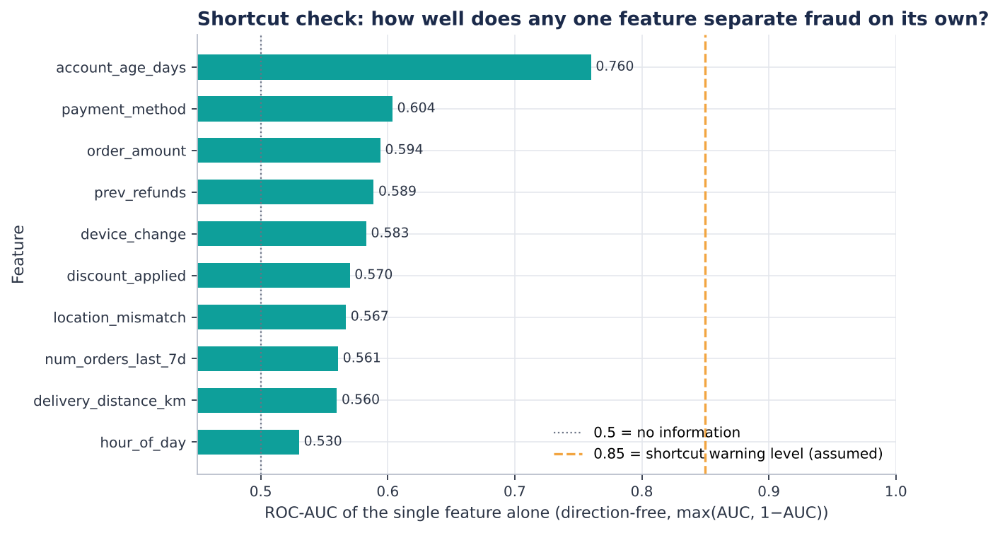

[FINDING] Highest single-feature AUC: account_age_days = 0.760 (no feature ≥ 0.85).
[FINDING] Purest categorical cell (n ≥ 30): fraud rate 52.2% (n = 134) — no combination of the categorical flags is a fraud rule.


[FINDING] A 4-leaf decision tree reaches average precision 0.227 (chance = 0.030): simple rules capture only part of the signal.


In [5]:
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_predict, StratifiedKFold

auc_single = {}
for c in FEATURES:
    x = seed_df[c] if c != "payment_method" else seed_df[c].map(seed_df.groupby(c)["is_fraud"].mean())
    a = roc_auc_score(seed_df.is_fraud, x)
    auc_single[c] = max(a, 1 - a)
auc_single = pd.Series(auc_single)
P.single_feature_auc(auc_single, OUT["eda"] / "09_single_feature_auc.png")

combo = seed_df.groupby(["payment_method"] + BINARY_COLS)["is_fraud"].agg(["mean", "size"]).query("size >= 30")
print(f"[FINDING] Highest single-feature AUC: {auc_single.idxmax()} = {auc_single.max():.3f} (no feature ≥ 0.85).")
print(f"[FINDING] Purest categorical cell (n ≥ 30): fraud rate {combo['mean'].max():.1%} "
      f"(n = {int(combo.loc[combo['mean'].idxmax(), 'size'])}) — no combination of the categorical flags is a fraud rule.")
Xd = seed_df[FEATURES].assign(payment_method=seed_df.payment_method.map({m: i for i, m in enumerate(PAYMENT_METHODS)}))
p_tree = cross_val_predict(DecisionTreeClassifier(max_leaf_nodes=4, random_state=SEED), Xd, seed_df.is_fraud,
                           cv=StratifiedKFold(3, shuffle=True, random_state=SEED), method="predict_proba")[:, 1]
print(f"[FINDING] A 4-leaf decision tree reaches average precision {average_precision_score(seed_df.is_fraud, p_tree):.3f} "
      f"(chance = {seed_df.is_fraud.mean():.3f}): simple rules capture only part of the signal.")
assert auc_single.max() < 0.85

## 1.3 Exploratory data analysis

Everything below describes the generated data. Where a pattern appears, it appears **because it was designed in**; the value of the EDA is to confirm the generator behaves as specified and that classes overlap realistically.

In [6]:
print("Shape:", seed_df.shape)
display(pd.DataFrame({"dtype": seed_df.dtypes.astype(str), "missing": seed_df.isna().sum(),
                      "unique values": seed_df.nunique()}).T)
display(seed_df.groupby("is_fraud")[["order_amount", "account_age_days", "num_orders_last_7d", "delivery_distance_km",
                                      "prev_refunds"]].describe().T.rename(columns={0: "legit", 1: "fraud"}, level=0))
display(pd.concat({c: seed_df.groupby("is_fraud")[c].mean() for c in BINARY_COLS}, axis=1)
        .rename(index={0: "legit", 1: "fraud"}).style.format("{:.1%}").set_caption("Share of orders with each flag = 1"))
display((pd.crosstab(seed_df.payment_method, seed_df.is_fraud, normalize="columns") * 100).round(1)
        .rename(columns={0: "legit %", 1: "fraud %"}))

Shape: (50000, 11)


,order_amount,account_age_days,hour_of_day,num_orders_last_7d,payment_method,delivery_distance_km,discount_applied,prev_refunds,device_change,location_mismatch,is_fraud
dtype,float64,int64,int64,int64,object,float64,int64,int64,int64,int64,int64
missing,0,0,0,0,0,0,0,0,0,0,0
unique values,15740,2584,24,33,4,1340,2,10,2,2,2


is_fraud                         legit      fraud
order_amount         count 48,488.0000 1,512.0000
                     mean      77.2991   106.3021
                     std       54.1296    84.4510
                     min       15.0000    15.0000
                     25%       41.4700    45.7025
                     50%       63.1500    80.5500
                     75%       97.1200   141.7975
                     max      842.0600   749.8300
account_age_days     count 48,488.0000 1,512.0000
                     mean     546.4556   242.3677
                     std      543.6493   419.2415
                     min        0.0000     0.0000
                     25%      199.0000     2.0000
                     50%      385.0000    31.5000
                     75%      706.2500   324.2500
                     max    3,000.0000 3,000.0000
num_orders_last_7d   count 48,488.0000 1,512.0000
                     mean       1.5120     2.0893
                     std        2.0464     2.4046
                     min        0.0000     0.0000
                     25%        0.0000     0.0000
                     50%        1.0000     1.0000
                     75%        2.0000     3.0000
                     max       40.0000    16.0000
delivery_distance_km count 48,488.0000 1,512.0000
                     mean       3.6671     4.2604
                     std        2.4078     2.7897
                     min        0.3000     0.3000
                     25%        1.8900     2.2000
                     50%        3.1600     3.6350
                     75%        4.9100     5.6700
                     max       15.0000    15.0000
prev_refunds         count 48,488.0000 1,512.0000
                     mean       0.1785     0.8373
                     std        0.4940     1.5966
                     min        0.0000     0.0000
                     25%        0.0000     0.0000
                     50%        0.0000     0.0000
                     75%        0.0000     1.0000
                     max        8.0000     9.0000

,discount_applied,device_change,location_mismatch
is_fraud,,,
legit,35.5%,3.4%,11.5%
fraud,49.5%,20.0%,24.9%


is_fraud,legit %,fraud %
payment_method,,
applepay,29.4000,17.1000
card,48.1000,51.1000
cod,14.7000,12.6000
wallet,7.8000,19.1000


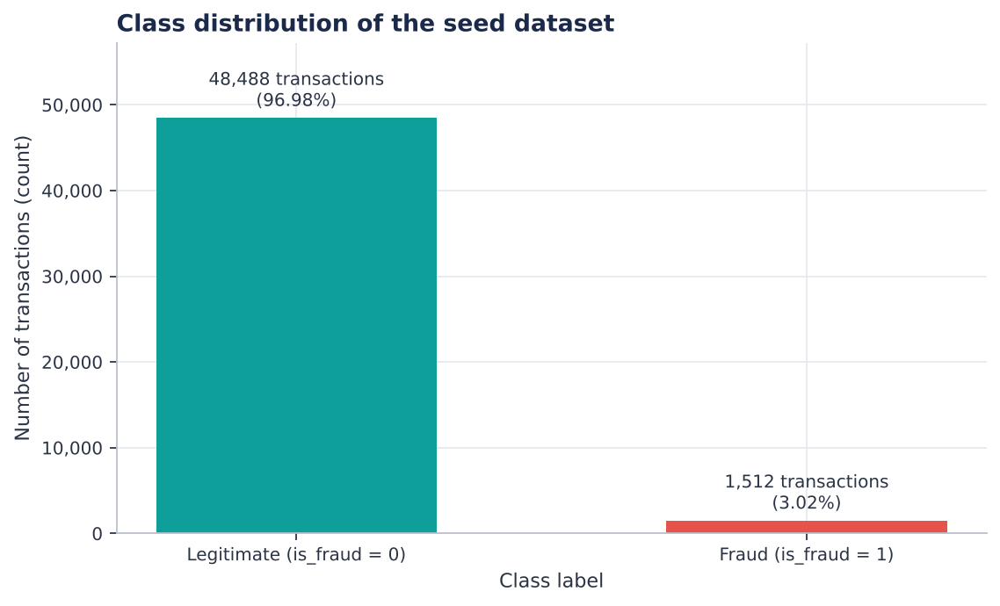

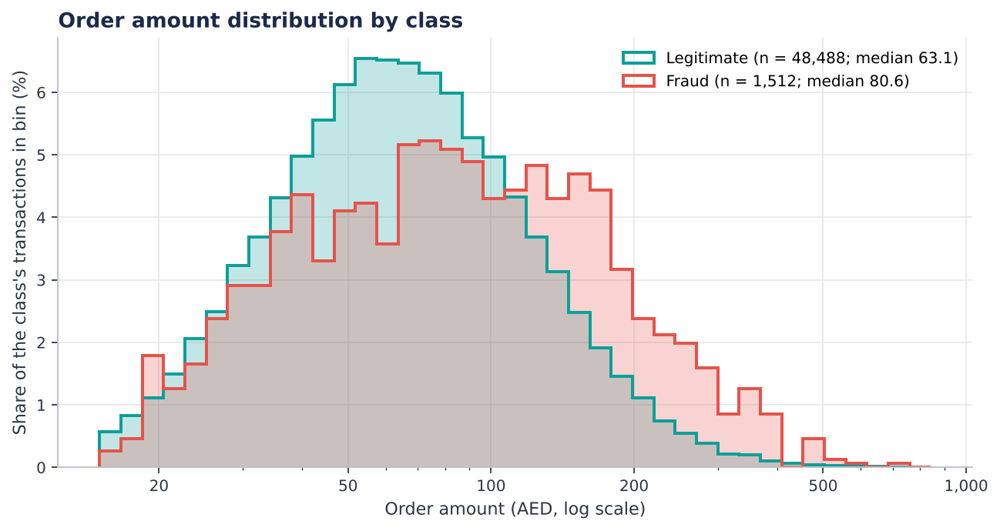

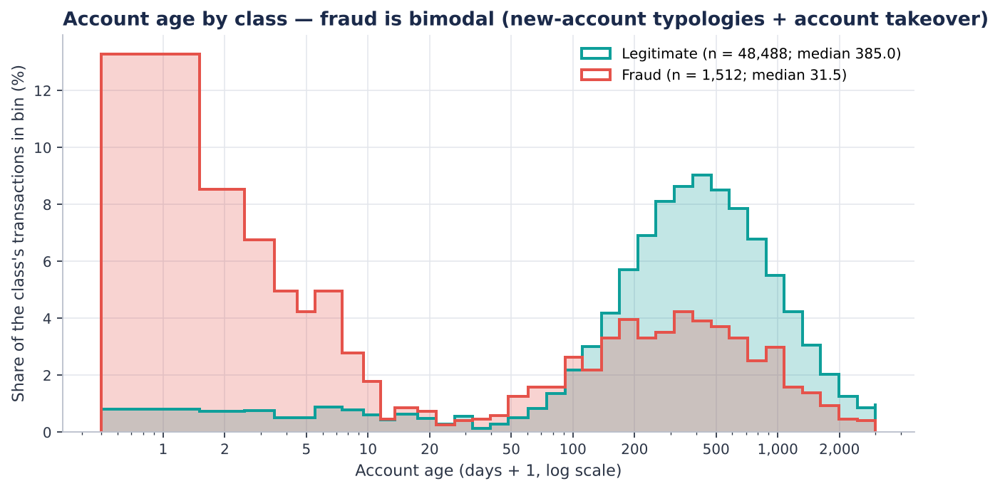

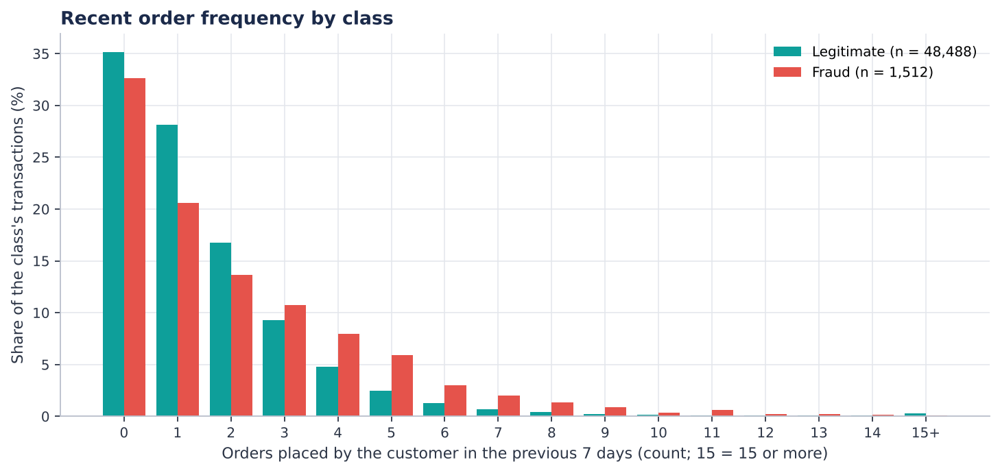

PosixPath('/home/claude/Noon_Fraud_Detection/outputs/eda/04_orders_last_7d_by_class.png')

In [7]:
P.class_distribution(seed_df, OUT["eda"] / "01_class_distribution.png")
P.numeric_by_class(seed_df, "order_amount", OUT["eda"] / "02_order_amount_by_class.png",
                   "Order amount (AED, log scale)", log=True, title="Order amount distribution by class")
P.numeric_by_class(seed_df, "account_age_days", OUT["eda"] / "03_account_age_by_class.png",
                   "Account age (days + 1, log scale)", log=True,
                   title="Account age by class — fraud is bimodal (new-account typologies + account takeover)")
P.discrete_by_class(seed_df, "num_orders_last_7d", OUT["eda"] / "04_orders_last_7d_by_class.png",
                    "Orders placed by the customer in the previous 7 days (count; 15 = 15 or more)",
                    title="Recent order frequency by class")

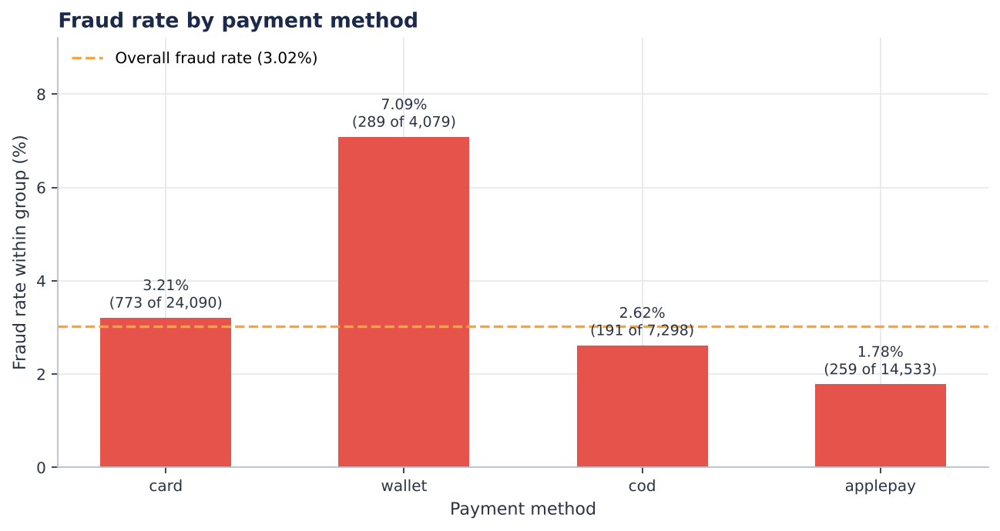

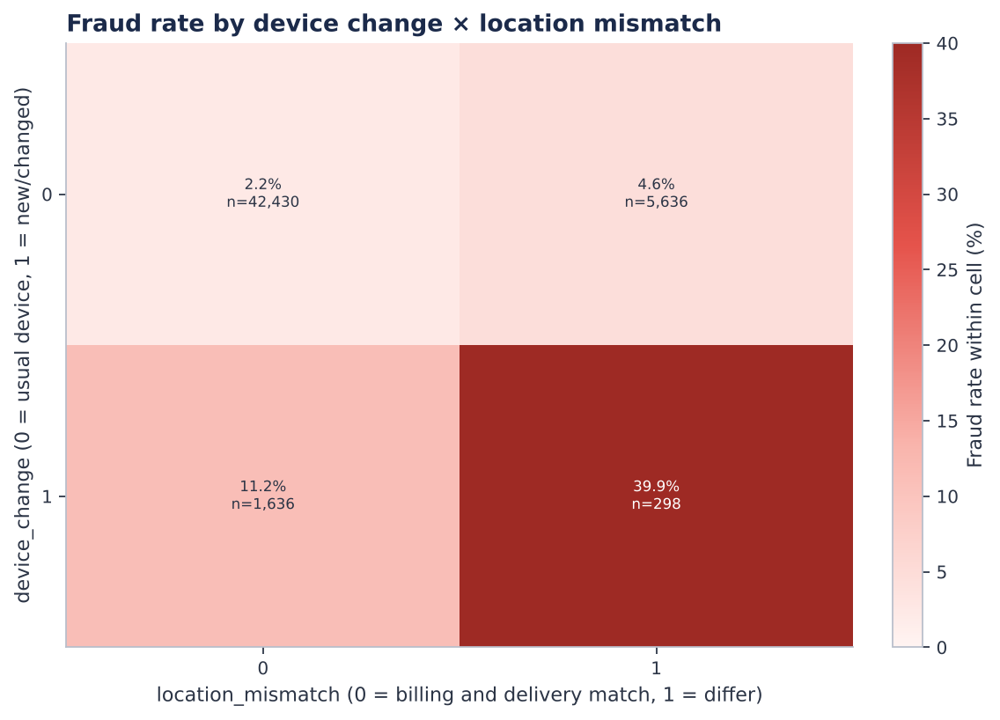

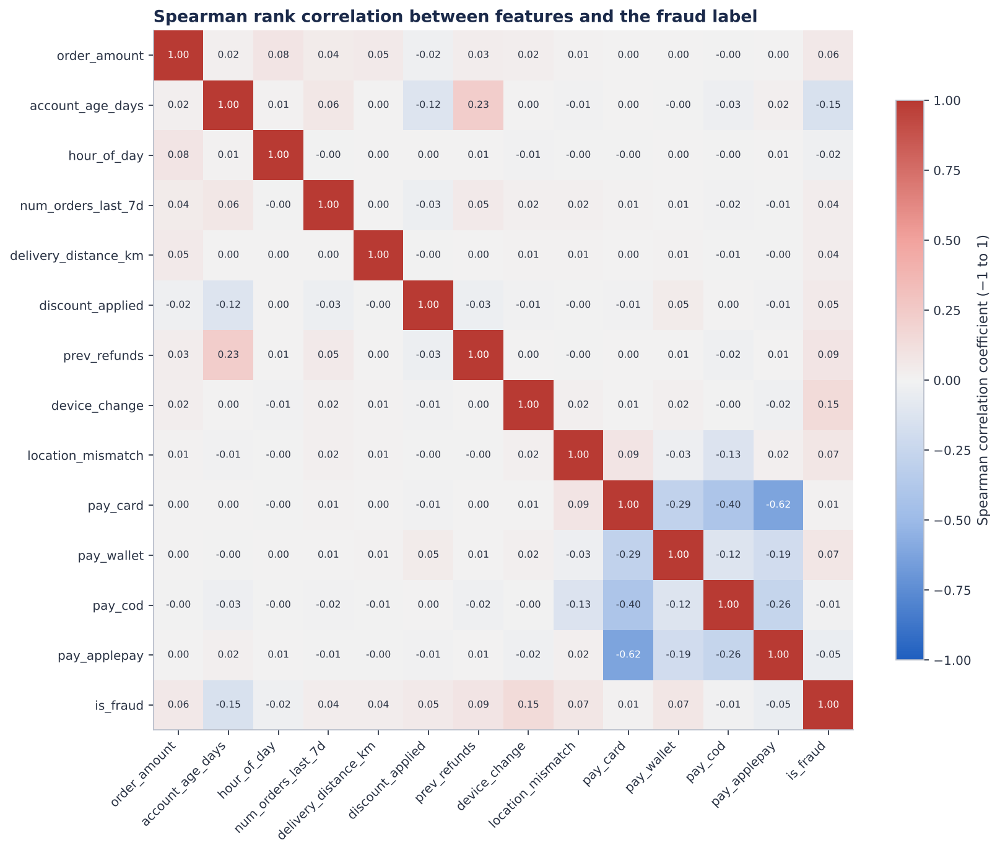

[FINDING] Strongest Spearman associations with is_fraud:


,ρ with is_fraud
account_age_days,-0.1542
device_change,0.1475
prev_refunds,0.0851
location_mismatch,0.0710
pay_wallet,0.0707
order_amount,0.0559


In [8]:
P.fraud_rate_by_category(seed_df, "payment_method", OUT["eda"] / "05_fraud_rate_by_payment.png", "Payment method",
                         order=PAYMENT_METHODS, title="Fraud rate by payment method")
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7, 5), constrained_layout=True)
im = P.rate_heatmap(ax, seed_df, "device_change", "location_mismatch", vmax=40, title=None)
ax.set_xlabel("location_mismatch (0 = billing and delivery match, 1 = differ)")
ax.set_ylabel("device_change (0 = usual device, 1 = new/changed)")
cb = fig.colorbar(im, ax=ax); cb.set_label("Fraud rate within cell (%)")
ax.set_title("Fraud rate by device change × location mismatch")
P.save(fig, OUT["eda"] / "06_fraud_rate_device_x_location.png")
_, corr = P.association_heatmap(seed_df, OUT["eda"] / "07_association_heatmap.png")
print("[FINDING] Strongest Spearman associations with is_fraud:")
display(corr["is_fraud"].drop("is_fraud").sort_values(key=abs, ascending=False).head(6).to_frame("ρ with is_fraud"))

**The eight hypothesised feature combinations** (fraud rate per cell; cells with fewer than 20 orders are greyed out rather than shown as noisy percentages).

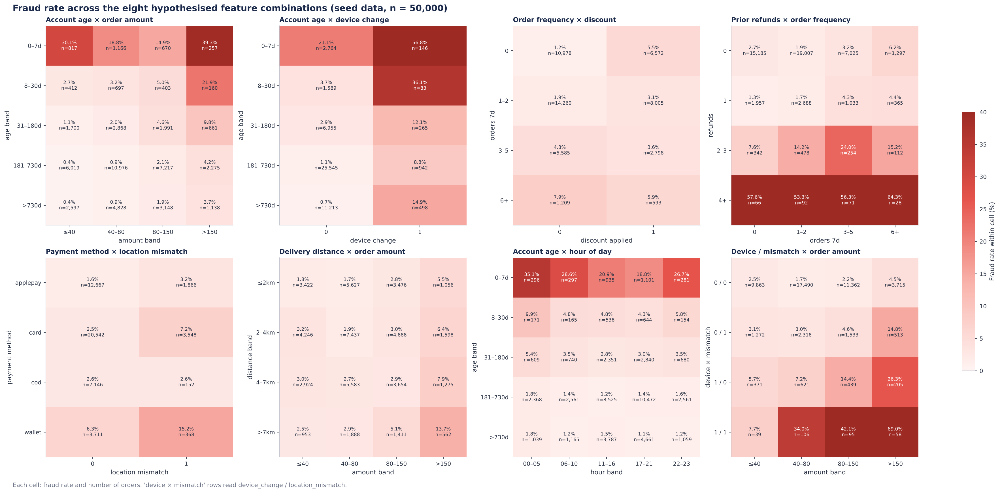

PosixPath('/home/claude/Noon_Fraud_Detection/outputs/eda/08_feature_interactions.png')

In [9]:
d = seed_df.copy()
d["age band"] = pd.cut(d.account_age_days, [-1, 7, 30, 180, 730, 3000], labels=["0–7d", "8–30d", "31–180d", "181–730d", ">730d"])
d["amount band"] = pd.cut(d.order_amount, [0, 40, 80, 150, 2000], labels=["≤40", "40–80", "80–150", ">150"])
d["orders 7d"] = pd.cut(d.num_orders_last_7d, [-1, 0, 2, 5, 40], labels=["0", "1–2", "3–5", "6+"])
d["refunds"] = pd.cut(d.prev_refunds, [-1, 0, 1, 3, 15], labels=["0", "1", "2–3", "4+"])
d["distance band"] = pd.cut(d.delivery_distance_km, [0, 2, 4, 7, 15], labels=["≤2km", "2–4km", "4–7km", ">7km"])
d["hour band"] = pd.cut(d.hour_of_day, [-1, 5, 10, 16, 21, 23], labels=["00–05", "06–10", "11–16", "17–21", "22–23"])
d["device × mismatch"] = d.device_change.astype(str) + " / " + d.location_mismatch.astype(str)
panels = [("age band", "amount band", "Account age × order amount"),
          ("age band", "device_change", "Account age × device change"),
          ("orders 7d", "discount_applied", "Order frequency × discount"),
          ("refunds", "orders 7d", "Prior refunds × order frequency"),
          ("payment_method", "location_mismatch", "Payment method × location mismatch"),
          ("distance band", "amount band", "Delivery distance × order amount"),
          ("age band", "hour band", "Account age × hour of day"),
          ("device × mismatch", "amount band", "Device / mismatch × order amount")]
fig, axes = plt.subplots(2, 4, figsize=(22, 10.5), constrained_layout=True)
for ax, (r, c, t) in zip(axes.ravel(), panels):
    im = P.rate_heatmap(ax, d, r, c, vmax=40, title=t, min_n=20)
cb = fig.colorbar(im, ax=axes, shrink=0.6); cb.set_label("Fraud rate within cell (%)")
P._suptitle(fig, "Fraud rate across the eight hypothesised feature combinations (seed data, n = 50,000)",
            "Each cell: fraud rate and number of orders. 'device × mismatch' rows read device_change / location_mismatch.")
P.save(fig, OUT["eda"] / "08_feature_interactions.png")

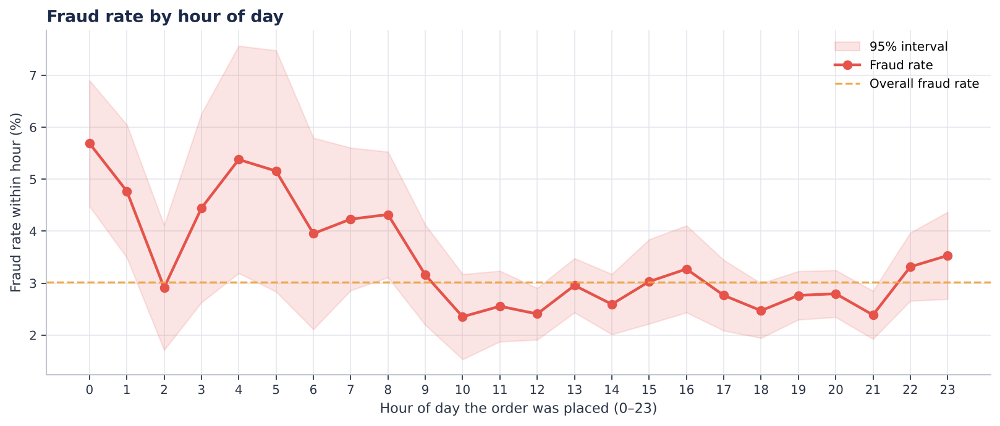

,column,upper IQR fence,rows above fence,fraud rate above fence
0,order_amount,182.9900,2438,8.9%
1,account_age_days,"1,460.0000",3206,1.2%
2,num_orders_last_7d,5.0000,1802,7.3%
3,delivery_distance_km,9.4700,1454,5.8%
4,prev_refunds,0.0000,7486,6.0%


[FINDING] Long upper tails exist by design (large group orders, power users, refund histories) and are kept: they are plausible, and dropping them would remove legitimate look-alikes of fraud.


In [10]:
hr = seed_df.groupby("hour_of_day")["is_fraud"].agg(["mean", "size"])
se = np.sqrt(hr["mean"] * (1 - hr["mean"]) / hr["size"])
fig, ax = plt.subplots(figsize=(10, 4.2), constrained_layout=True)
ax.fill_between(hr.index, (hr["mean"] - 1.96 * se) * 100, (hr["mean"] + 1.96 * se) * 100, color=FRAUD, alpha=0.15, label="95% interval")
ax.plot(hr.index, hr["mean"] * 100, "o-", color=FRAUD, label="Fraud rate")
ax.axhline(seed_df.is_fraud.mean() * 100, color=AMBER, ls="--", lw=1.4, label="Overall fraud rate")
ax.set_xticks(range(24)); ax.set_xlabel("Hour of day the order was placed (0–23)")
ax.set_ylabel("Fraud rate within hour (%)"); ax.legend(); ax.set_title("Fraud rate by hour of day")
P.save(fig, OUT["eda"] / "10_fraud_rate_by_hour.png")

out_rows = []
for c in ["order_amount", "account_age_days", "num_orders_last_7d", "delivery_distance_km", "prev_refunds"]:
    q1, q3 = seed_df[c].quantile([0.25, 0.75]); hi = q3 + 1.5 * (q3 - q1)
    m = seed_df[c] > hi
    out_rows.append((c, round(hi, 2), int(m.sum()), f"{seed_df.loc[m, 'is_fraud'].mean():.1%}" if m.any() else "–"))
display(pd.DataFrame(out_rows, columns=["column", "upper IQR fence", "rows above fence", "fraud rate above fence"]))
print("[FINDING] Long upper tails exist by design (large group orders, power users, refund histories) and are kept: "
      "they are plausible, and dropping them would remove legitimate look-alikes of fraud.")

In [11]:
fr = lambda m: seed_df.loc[m, "is_fraud"].mean()
print("[FINDING] Key EDA observations (seed data, i.e. the designed assumptions — not real-world evidence):")
print(f"  • Median basket: legit AED {seed_df.loc[seed_df.is_fraud == 0, 'order_amount'].median():.0f} vs fraud AED "
      f"{seed_df.loc[seed_df.is_fraud == 1, 'order_amount'].median():.0f}; but fraud spans both small promo baskets and large stolen-card baskets.")
print(f"  • Account age: {fr(seed_df.account_age_days <= 7):.1%} of orders from accounts ≤ 7 days old are fraud, "
      f"{fr(seed_df.account_age_days.between(31, 730)):.1%} for 31–730 days, {fr(seed_df.account_age_days > 730):.1%} for > 730 days (takeover).")
print(f"  • Device change AND location mismatch: fraud rate {fr((seed_df.device_change == 1) & (seed_df.location_mismatch == 1)):.1%}, "
      f"vs {fr((seed_df.device_change == 0) & (seed_df.location_mismatch == 0)):.1%} when neither is set.")
print(f"  • ≥ 2 prior refunds: fraud rate {fr(seed_df.prev_refunds >= 2):.1%} — high, but most such customers are legitimate.")
print(f"  • Wallet orders carry the highest fraud rate ({fr(seed_df.payment_method == 'wallet'):.1%}); Apple Pay the lowest ({fr(seed_df.payment_method == 'applepay'):.1%}).")

[FINDING] Key EDA observations (seed data, i.e. the designed assumptions — not real-world evidence):
  • Median basket: legit AED 63 vs fraud AED 81; but fraud spans both small promo baskets and large stolen-card baskets.
  • Account age: 22.9% of orders from accounts ≤ 7 days old are fraud, 1.8% for 31–730 days, 1.3% for > 730 days (takeover).
  • Device change AND location mismatch: fraud rate 39.9%, vs 2.2% when neither is set.
  • ≥ 2 prior refunds: fraud rate 22.0% — high, but most such customers are legitimate.
  • Wallet orders carry the highest fraud rate (7.1%); Apple Pay the lowest (1.8%).


## 1.4 Split before anything is learned

Stratified 70 / 15 / 15 split (train / validation / test), made **before** the GAN or any classifier sees the data. The checks below are executed, not just asserted in prose.

In [12]:
tr_idx, va_idx, te_idx = M.stratified_split(seed_df, SEED)
Xall, yall = seed_df[FEATURES], seed_df[TARGET]
X_tr, y_tr = Xall.iloc[tr_idx], yall.iloc[tr_idx]
X_val, y_val = Xall.iloc[va_idx], yall.iloc[va_idx]
X_te, y_te = Xall.iloc[te_idx], yall.iloc[te_idx]
split_tab = pd.DataFrame({"rows": [len(tr_idx), len(va_idx), len(te_idx)],
                          "fraud rows": [int(y_tr.sum()), int(y_val.sum()), int(y_te.sum())],
                          "fraud rate": [y_tr.mean(), y_val.mean(), y_te.mean()]}, index=["train", "validation", "test"])
display(split_tab.style.format({"rows": "{:,}", "fraud rows": "{:,}", "fraud rate": "{:.3%}"}))
assert len(set(tr_idx) & set(va_idx)) == len(set(tr_idx) & set(te_idx)) == len(set(va_idx) & set(te_idx)) == 0
assert len(tr_idx) + len(va_idx) + len(te_idx) == len(seed_df)
assert all(abs(r - seed_df.is_fraud.mean()) < 0.002 for r in split_tab["fraud rate"])
np.savez(DATA / "split_indices.npz", train=tr_idx, validation=va_idx, test=te_idx)
print("[FINDING] Partitions are disjoint, cover every row, and each keeps the 3% fraud rate. Test fraud cases:", int(y_te.sum()))

,rows,fraud rows,fraud rate
train,"35,000","1,058",3.023%
validation,"7,500",227,3.027%
test,"7,500",227,3.027%


[FINDING] Partitions are disjoint, cover every row, and each keeps the 3% fraud rate. Test fraud cases: 227


## 1.5 Baseline classifiers — and *feeling the problem*

**The accuracy trap first.** A "model" that always says *legit* is about 97% accurate and catches no fraud at all.

[FINDING] Majority-class benchmark on validation: accuracy 96.97% · recall 0% · fraud caught 0 of 227.


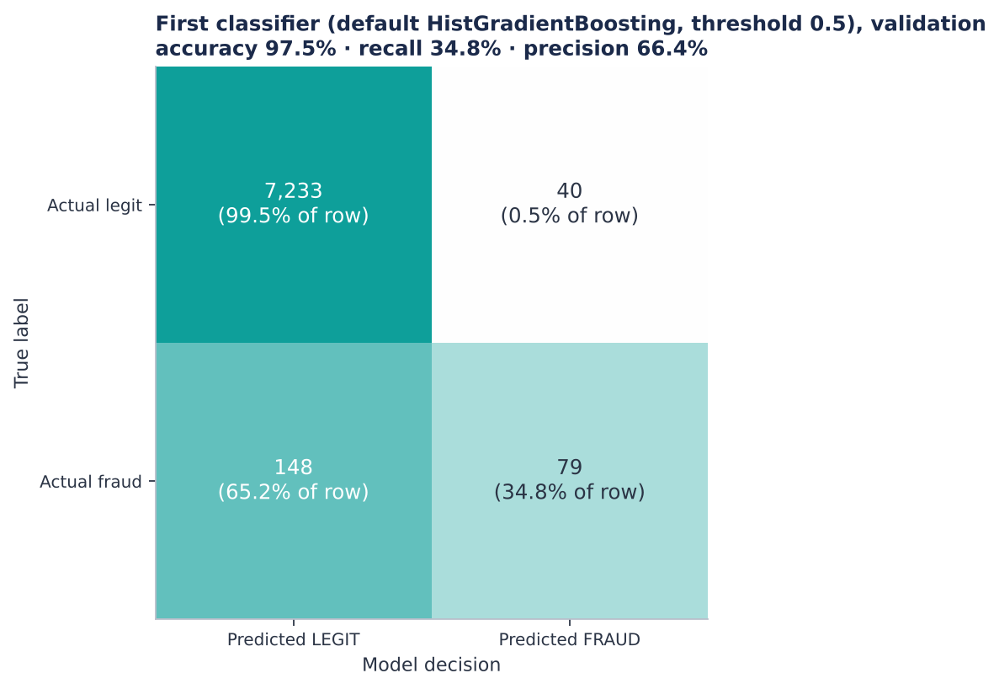

[FINDING] A default classifier at the default 0.5 threshold is 97.5% accurate yet catches only 79 of 227 fraud cases (34.8%). This is the problem the brief describes.


In [13]:
maj = E.compute_metrics(y_val, np.zeros(len(y_val)), 0.5)
print(f"[FINDING] Majority-class benchmark on validation: accuracy {maj['accuracy']:.2%} · recall {maj['recall']:.0%} · "
      f"fraud caught {maj['TP']} of {maj['n_fraud']}.")

quick = M.make_estimator("hist_gb", SEED).fit(X_tr, y_tr)
p_quick = quick.predict_proba(X_val)[:, 1]
mq = E.compute_metrics(y_val, p_quick, 0.5)
P.single_confusion(mq, OUT["cm"] / "00_first_classifier_default_threshold.png",
                   f"First classifier (default HistGradientBoosting, threshold 0.5), validation\n"
                   f"accuracy {mq['accuracy']:.1%} · recall {mq['recall']:.1%} · precision {mq['precision']:.1%}")
print(f"[FINDING] A default classifier at the default 0.5 threshold is {mq['accuracy']:.1%} accurate yet catches only "
      f"{mq['TP']} of {mq['n_fraud']} fraud cases ({mq['recall']:.1%}). This is the problem the brief describes.")

**Candidate families.** Four model families, each tuned by 3-fold cross-validation **on the training partition only** (scoring = average precision, the right summary when positives are rare: its chance level equals the fraud rate). Logistic regression gets spline features and a periodic hour encoding so it can represent the bimodal account-age effect; the tree models use raw features.

Logistic regression (splines)    CV AP 0.4633  best params {'C': 10.0}


Random forest                    CV AP 0.5309  best params {'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': None}


Extra trees                      CV AP 0.4980  best params {'min_samples_leaf': 5, 'max_features': 0.5, 'max_depth': None}


HistGradientBoosting             CV AP 0.5362  best params {'min_samples_leaf': 50, 'max_leaf_nodes': 15, 'max_iter': 200, 'learning_rate': 0.03, 'l2_regularization': 1.0}
Tuning time 223s


,family,class_weight,cv_ap_train,val_ap,val_roc_auc,val_f1_at_best_threshold,val_recall,val_precision
0,Logistic regression (splines),none,0.4633,0.4445,0.9383,0.4886,0.6123,0.4064
1,Logistic regression (splines),balanced,0.4633,0.4181,0.9381,0.4710,0.5374,0.4192
2,Random forest,none,0.5309,0.4918,0.9378,0.5558,0.5374,0.5755
3,Random forest,balanced,0.5309,0.4728,0.9409,0.5294,0.5947,0.4770
4,Extra trees,none,0.4980,0.4796,0.9400,0.5273,0.6167,0.4605
5,Extra trees,balanced,0.4980,0.4649,0.9401,0.5190,0.5110,0.5273
6,HistGradientBoosting,none,0.5362,0.5199,0.9434,0.5536,0.5463,0.5611
7,HistGradientBoosting,balanced,0.5362,0.4876,0.9414,0.5369,0.5286,0.5455


[FINDING] Selected shared classifier configuration (best validation AP, unweighted): HistGradientBoosting {'min_samples_leaf': 50, 'max_leaf_nodes': 15, 'max_iter': 200, 'learning_rate': 0.03, 'l2_regularization': 1.0}


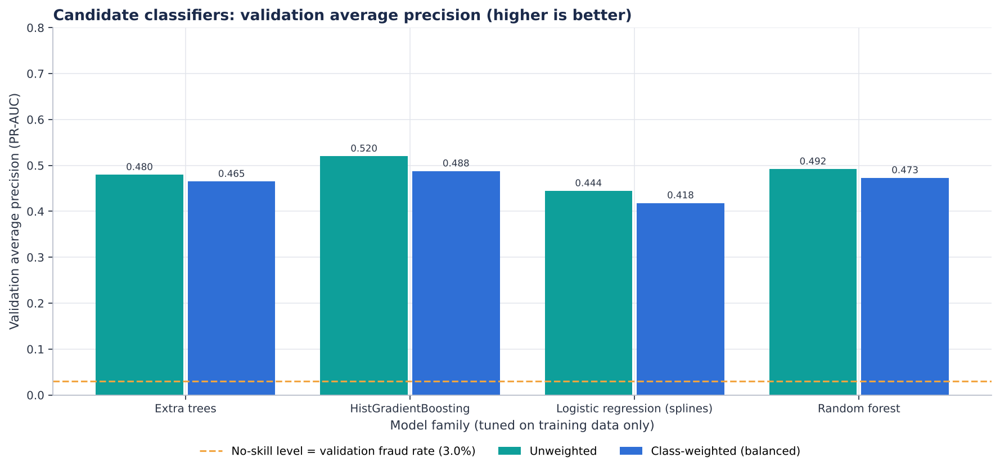

PosixPath('/home/claude/Noon_Fraud_Detection/outputs/metrics/01_candidate_families_validation_ap.png')

In [14]:
tuned = {}
t_start = time.time()
for fam in ["logreg", "random_forest", "extra_trees", "hist_gb"]:
    best, cv_ap, _ = M.tune_family(fam, X_tr, y_tr, SEED, n_iter=TUNE_ITER)
    tuned[fam] = dict(params=best, cv_ap=cv_ap)
    print(f"{M.FAMILY_LABELS[fam]:32s} CV AP {cv_ap:.4f}  best params {best}")
print(f"Tuning time {time.time() - t_start:.0f}s")

rows = []
for fam, t in tuned.items():
    for cw in (None, "balanced"):
        model, p_v, ap = M.fit_and_score(fam, t["params"], SEED, X_tr, y_tr, X_val, y_val, class_weight=cw)
        thr = M.max_f1_threshold(y_val, p_v)
        m = E.compute_metrics(y_val, p_v, thr)
        rows.append({"family": M.FAMILY_LABELS[fam], "family_key": fam, "class_weight": cw or "none",
                     "cv_ap_train": t["cv_ap"], "val_ap": ap, "val_roc_auc": m["roc_auc"],
                     "val_f1_at_best_threshold": m["f1"], "val_recall": m["recall"], "val_precision": m["precision"]})
cand = pd.DataFrame(rows)
display(cand.drop(columns="family_key").style.format(precision=4).background_gradient(subset=["val_ap"], cmap="Greens"))
cand.to_csv(OUT["metrics"] / "candidate_classifiers_validation.csv", index=False)

unweighted = cand[cand.class_weight == "none"].set_index("family_key")
FAMILY = unweighted["val_ap"].idxmax()
PARAMS = tuned[FAMILY]["params"]
print(f"[FINDING] Selected shared classifier configuration (best validation AP, unweighted): {M.FAMILY_LABELS[FAMILY]} {PARAMS}")
cmp = cand.pivot(index="family", columns="class_weight", values="val_ap")[["none", "balanced"]]
cmp.columns = ["Unweighted", "Class-weighted (balanced)"]
P.grouped_bars(cmp, {"Unweighted": LEGIT, "Class-weighted (balanced)": ARM_COLORS["C_class_weighted"]},
               OUT["metrics"] / "01_candidate_families_validation_ap.png",
               "Candidate classifiers: validation average precision (higher is better)",
               "Validation average precision (PR-AUC)", "Model family (tuned on training data only)",
               fmt="{:.3f}", ylim=(0, max(0.8, cmp.values.max() * 1.15)), pct_axis=False,
               refline=(y_val.mean(), f"No-skill level = validation fraud rate ({y_val.mean():.1%})"), figsize=(11, 4.8))

## 1.6 A genuine CTGAN, trained only on training-partition fraud

**How CTGAN works.** Two neural networks are trained against each other. The **generator** turns random noise (plus a randomly chosen *condition*, e.g. "payment_method = wallet") into a synthetic transaction. The **discriminator** (here a *critic*) looks at real and generated transactions and scores how real they look. Each training step the critic is updated to separate real from fake better, then the generator is updated to fool the critic. Over many epochs the generator's output distribution is pulled towards the real one — the GAN **learns a distribution** rather than copying or inventing rows.

CTGAN adds three things that matter for tabular fraud data: **mode-specific normalisation** (each continuous column is modelled with a Gaussian mixture, so bimodal account age is representable), a **conditional generator with training-by-sampling** (rare categories are deliberately shown to the generator), and a **PacGAN critic** that judges packs of 10 rows at once to discourage mode collapse. The loss is WGAN-GP: the discriminator loss is the negative of its Wasserstein estimate, the generator loss is the critic's score of fake rows plus a conditional term — neither should "go to zero"; what matters is that they stabilise.

**Configuration (pre-declared).** ctgan 0.12.1; 600 epochs; batch size 100 (the default 500 would give only ~2 gradient steps per epoch on ~1,050 rows); pac = 10; discrete columns = payment method, the three flags, hour, and the two count columns (so they can only take observed integer values); `account_age_days`, `order_amount` and `delivery_distance_km` are continuous.

GAN training data: 1,058 fraud rows, all from the TRAINING partition (verified: none from validation/test).


[FINDING] CTGAN fitted in 1.9 min · 600 epochs · ≈6,000 generator updates · seed 42
Generator network: 220,810 trainable parameters; saved to models/ctgan_fraud_generator.pkl
Generator(
  (seq): Sequential(
    (0): Residual(
      (fc): Linear(in_features=188, out_features=256, bias=True)
      (bn): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU()
    )
    (1): Residual(
      (fc): Linear(in_features=444, out_features=256, bias=True)
      (bn): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU()
    )
    (2): Linear(in_features=700, out_features=82, bias=True)
  )
)


,Epoch,Generator Loss,Discriminator Loss
0,0,1.7981,-0.0429
1,1,1.7154,-0.2105
2,2,1.5806,-0.3026
597,597,-2.0017,0.1836
598,598,-1.9621,0.0787
599,599,-2.0933,-0.2507


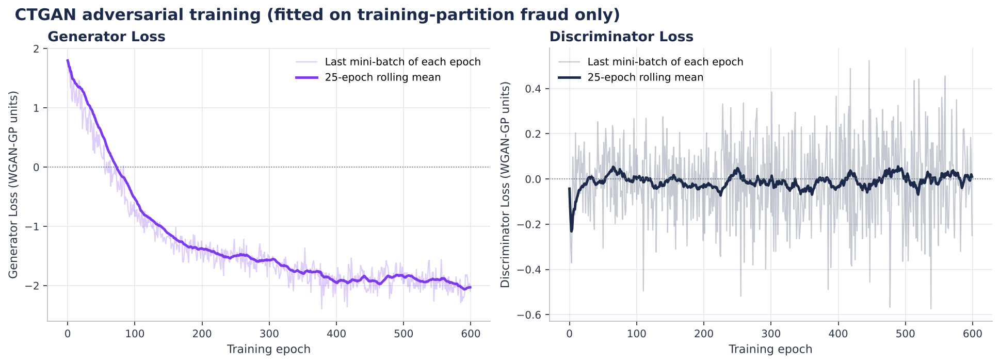

[FINDING] Generator loss, mean of first 50 epochs 0.939 → last 50 epochs -1.996; discriminator loss, last 50 epochs mean 0.019 (sd 0.177).


In [15]:
fraud_tr = X_tr[y_tr.values == 1]
train_fraud_index = set(fraud_tr.index)
assert train_fraud_index <= set(X_tr.index) and not (train_fraud_index & set(X_val.index)) and not (train_fraud_index & set(X_te.index))
assert (yall.loc[list(train_fraud_index)] == 1).all()
print(f"GAN training data: {len(fraud_tr):,} fraud rows, all from the TRAINING partition (verified: none from validation/test).")

gan = G.FraudCTGAN(SEED, epochs=GAN_EPOCHS).fit(fraud_tr)
steps = GAN_EPOCHS * max(len(fraud_tr) // CTGAN_PARAMS["batch_size"], 1)
print(f"[FINDING] CTGAN fitted in {gan.fit_seconds / 60:.1f} min · {GAN_EPOCHS} epochs · ≈{steps:,} generator updates · seed {SEED}")
loss = gan.loss_values
loss.to_csv(OUT["gan"] / "ctgan_loss_values.csv", index=False)
MODELS.mkdir(exist_ok=True, parents=True)
gan.save(MODELS / "ctgan_fraud_generator.pkl")
n_params = sum(p.numel() for p in gan.model._generator.parameters())
print(f"Generator network: {n_params:,} trainable parameters; saved to models/ctgan_fraud_generator.pkl")
print(gan.model._generator)
display(loss.iloc[np.r_[0:3, -3:0]])
P.gan_losses(loss, OUT["gan"] / "01_ctgan_loss_curves.png")
early, late = loss["Generator Loss"].iloc[:50].mean(), loss["Generator Loss"].iloc[-50:].mean()
print(f"[FINDING] Generator loss, mean of first 50 epochs {early:.3f} → last 50 epochs {late:.3f}; "
      f"discriminator loss, last 50 epochs mean {loss['Discriminator Loss'].iloc[-50:].mean():.3f} (sd {loss['Discriminator Loss'].iloc[-50:].std():.3f}).")

**Training-length sensitivity.** Two extra CTGANs (100 and 300 epochs, same seed and data) are kept to show whether more training produces more faithful fraud — evidence that the generator is *learning*, not just running.

In [16]:
gans_by_epoch = {GAN_EPOCHS: gan}
if not DEV:
    for ep in EPOCH_SENSITIVITY:
        gans_by_epoch[ep] = G.FraudCTGAN(SEED, epochs=ep).fit(fraud_tr)
        print(f"Fitted {ep}-epoch CTGAN in {gans_by_epoch[ep].fit_seconds / 60:.1f} min")

Fitted 100-epoch CTGAN in 0.3 min


Fitted 300-epoch CTGAN in 0.9 min


Fitted 1000-epoch CTGAN in 3.2 min


## 1.7 Validating the generated fraud

The pool is drawn once (2× the training-fraud count, the largest ratio tested); smaller augmentation ratios use its first rows.

**Constraint handling (documented, every step counted).** CTGAN's continuous columns are modelled with Gaussian modes, which can spill outside the valid domain. The policy: (1) **clip to the floor only where the training data has a genuine point mass there** — 13.8% of training fraud has `account_age_days` = 0 (brand-new accounts), and generated ages just below 0 belong to that spike; (2) round integers and 2-dp columns to schema precision; (3) **reject** every other row that breaks a hard constraint or an assumed plausibility bound (amounts and distances have almost no mass at their floors, so clipping them would invent spikes). The cell after the log compares this policy with *reject everything* and *clip everything*, measured against training fraud only.

In [17]:
N_MAX = int(round(max(AUG_RATIOS) * len(fraud_tr)))
ctgan_pool, samp_log = gan.sample_valid(N_MAX)
log_df = samp_log.as_frame()
display(log_df[log_df.rows > 0])
log_df.to_csv(OUT["gan"] / "ctgan_sampling_log.csv", index=False)
v = validate_schema(ctgan_pool, require_target=False)
assert v["passed"].all()
print(f"[FINDING] {samp_log.raw_generated:,} rows drawn → {samp_log.n_rejected:,} rejected "
      f"({samp_log.n_rejected / samp_log.raw_generated:.1%}: {sum(samp_log.rejected_hard.values()):,} hard-constraint, "
      f"{sum(samp_log.rejected_plausibility.values()):,} plausibility) · {sum(samp_log.clipped_to_floor.values()):,} ages clipped to 0 days · "
      f"{samp_log.retained:,} retained (the rest of the final batch was valid surplus, not needed).")
exact_copies = ctgan_pool.merge(fraud_tr.drop_duplicates(), how="inner").shape[0]
print(f"[FINDING] Exact copies of training-fraud rows in the CTGAN pool: {exact_copies} · duplicate rows within the pool: "
      f"{int(ctgan_pool.duplicated().sum())}")
synthetic_out = ctgan_pool.assign(is_fraud=1)[list(SCHEMA)]
assert validate_schema(synthetic_out)["passed"].all()
synthetic_out.to_csv(DATA / "synthetic_fraud_gan.csv", index=False)
print(f"Saved data/synthetic_fraud_gan.csv: {len(synthetic_out):,} GAN-generated fraud rows, is_fraud set to 1 after generation.")

raw_check = gan.model.sample(4000)
policy_rows = []
lo_hi = {c: (fraud_tr[c].min(), fraud_tr[c].max()) for c in ["order_amount", "account_age_days", "delivery_distance_km"]}
for name, frame in [("Reject every violation", G.postprocess_generated(raw_check, clip_floor={})),
                    ("Clip age floor (point mass), reject rest — ADOPTED", G.postprocess_generated(raw_check)),
                    ("Clip every column to training min/max", G.postprocess_generated(
                        raw_check.assign(**{c: raw_check[c].clip(*lo_hi[c]) for c in lo_hi}), clip_floor={}))]:
    dt = G.marginal_distances(fraud_tr, frame).set_index("column")
    cc_ = G.c2st(fraud_tr, frame, SEED)
    policy_rows.append({"policy": name, "rows kept of 4,000": len(frame), "KS account_age_days": dt.loc["account_age_days", "ks_stat"],
                        "KS order_amount": dt.loc["order_amount", "ks_stat"], "KS delivery_distance_km": dt.loc["delivery_distance_km", "ks_stat"],
                        "C2ST AUC (gradient boosting)": cc_["AUC — Gradient boosting"]})
policy_tab = pd.DataFrame(policy_rows).set_index("policy")
display(policy_tab.style.format({"rows kept of 4,000": "{:,.0f}"}, precision=3))
policy_tab.to_csv(OUT["gan"] / "constraint_policy_comparison.csv")
print(f"[FINDING] Share of training fraud with account_age_days = 0: {(fraud_tr.account_age_days == 0).mean():.1%}; "
      f"order_amount at its floor: {(fraud_tr.order_amount == fraud_tr.order_amount.min()).mean():.1%}.")

pools = X.make_pools(X_tr, y_tr, SEED, N_MAX, ctgan_pool)
for k, p in pools.items():
    assert validate_schema(p, require_target=False)["passed"].all(), k

,step,rows
0,Rows requested,2116
1,Rows drawn from the generator,4000
2,Corrected — clipped to domain floor (training point mass): account_age_days,1229
3,Corrected — rounded to integer: account_age_days,2771
4,Corrected — rounded to 2 dp: order_amount,4000
5,Corrected — rounded to 2 dp: delivery_distance_km,4000
6,Rejected — hard constraint: order_amount,11
10,Rejected — hard constraint: delivery_distance_km,27
16,Rejected — outside assumed plausible range: order_amount,104
17,Rejected — outside assumed plausible range: account_age_days,1


[FINDING] 4,000 rows drawn → 197 rejected (4.9%: 38 hard-constraint, 159 plausibility) · 1,229 ages clipped to 0 days · 2,116 retained (the rest of the final batch was valid surplus, not needed).
[FINDING] Exact copies of training-fraud rows in the CTGAN pool: 0 · duplicate rows within the pool: 0
Saved data/synthetic_fraud_gan.csv: 2,116 GAN-generated fraud rows, is_fraud set to 1 after generation.


,"rows kept of 4,000",KS account_age_days,KS order_amount,KS delivery_distance_km,C2ST AUC (gradient boosting)
policy,,,,,
Reject every violation,"2,616",0.393,0.147,0.135,0.815
"Clip age floor (point mass), reject rest — ADOPTED","3,796",0.180,0.100,0.112,0.790
Clip every column to training min/max,"4,000",0.187,0.094,0.120,0.799


[FINDING] Share of training fraud with account_age_days = 0: 13.8%; order_amount at its floor: 0.6%.


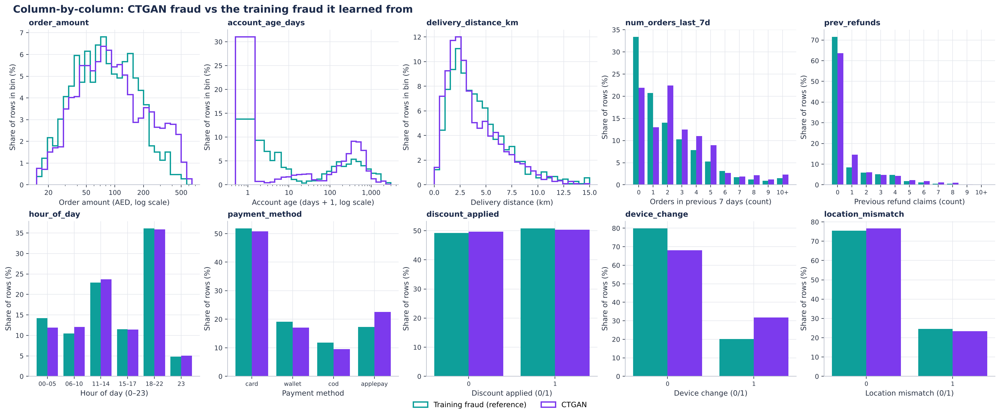

,CTGAN,SMOTE-NC,Independent marginals
"column (KS statistic for numeric, total-variation distance for categorical; 0 = identical)",,,
order_amount,0.108,0.017,0.012
account_age_days,0.172,0.052,0.016
hour_of_day,0.049,0.057,0.016
num_orders_last_7d,0.192,0.088,0.003
payment_method,0.053,0.128,0.017
delivery_distance_km,0.101,0.058,0.023
discount_applied,0.004,0.022,0.009
prev_refunds,0.079,0.054,0.013
device_change,0.117,0.108,0.005


,real_summary,syn_summary
"column (KS statistic for numeric, total-variation distance for categorical; 0 = identical)",,
order_amount,"median 77.7, mean 104.0","median 87.5, mean 134.0"
account_age_days,"median 13.0, mean 239.2","median 94.0, mean 237.4"
hour_of_day,"median 15.0, mean 14.2","median 15.0, mean 14.3"
num_orders_last_7d,"median 1.0, mean 2.0","median 2.0, mean 2.7"
payment_method,"applepay:0.17, card:0.52, cod:0.12, wallet:0.19","applepay:0.23, card:0.51, cod:0.09, wallet:0.17"
delivery_distance_km,"median 3.6, mean 4.2","median 3.0, mean 3.8"
discount_applied,"0:0.49, 1:0.51","0:0.50, 1:0.50"
prev_refunds,"median 0.0, mean 0.8","median 0.0, mean 1.0"
device_change,"0:0.80, 1:0.20","0:0.68, 1:0.32"


In [18]:
gen_frames = {"Training fraud (reference)": fraud_tr, "CTGAN": pools["B_ctgan"]}
P.marginal_comparison(gen_frames, {"Training fraud (reference)": REAL_REF, "CTGAN": GAN},
                      OUT["dist"] / "01_ctgan_vs_training_fraud_marginals.png",
                      "Column-by-column: CTGAN fraud vs the training fraud it learned from")
dist_tables = {nm: G.marginal_distances(fraud_tr, pools[k]).set_index("column")
               for nm, k in [("CTGAN", "B_ctgan"), ("SMOTE-NC", "D_smote_nc"), ("Independent marginals", "F_independent_marginals")]}
ks = pd.DataFrame({nm: t["ks_stat"].fillna(t["tvd"]) for nm, t in dist_tables.items()})
ks.index.name = "column (KS statistic for numeric, total-variation distance for categorical; 0 = identical)"
display(ks.style.format("{:.3f}").background_gradient(cmap="Reds", vmin=0, vmax=0.3))
display(dist_tables["CTGAN"][["real_summary", "syn_summary"]])

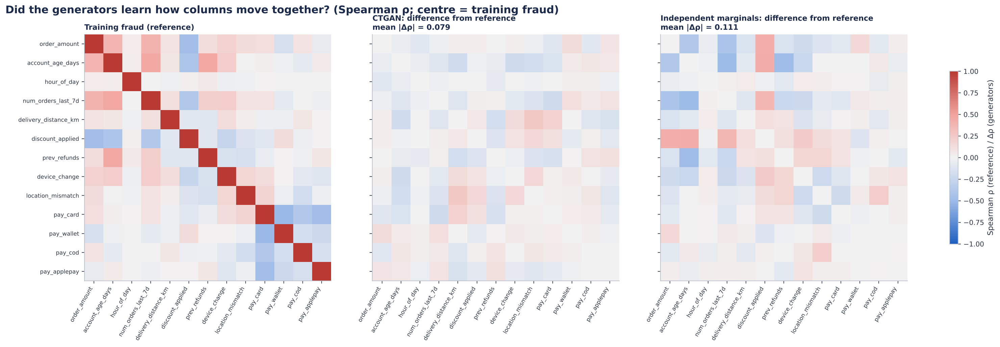

[FINDING] Mean |Δρ| vs training fraud — CTGAN: 0.079 · SMOTE-NC: 0.054 · Independent marginals: 0.111


,Training fraud (reference),CTGAN,SMOTE-NC,Independent marginals,Training LEGIT (for scale)
Account takeover age > 180 d · device change · location mismatch,3.7%,4.4%,0.9%,1.1%,0.3%
Promo abuse age < 15 d · discount · basket < AED 50,22.9%,15.3%,25.8%,7.4%,1.8%
Refund abuse ≥ 2 prior refunds · ≥ 2 orders in 7 d,12.9%,17.8%,9.8%,10.0%,1.0%
Stolen card card · location mismatch · age < 60 d,10.2%,10.7%,9.7%,6.3%,0.6%
COD fake order COD · age < 60 d · basket > AED 100,4.2%,1.5%,4.5%,2.7%,0.4%


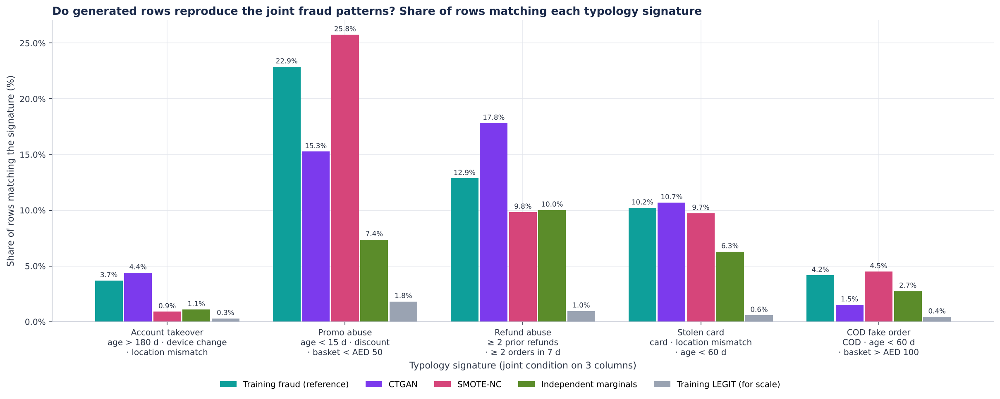

PosixPath('/home/claude/Noon_Fraud_Detection/outputs/gan_diagnostics/03_fraud_typology_signatures.png')

In [19]:
P.correlation_triptych(fraud_tr, {"CTGAN": pools["B_ctgan"], "Independent marginals": pools["F_independent_marginals"]},
                       OUT["gan"] / "02_correlation_structure.png",
                       "Did the generators learn how columns move together? (Spearman ρ; centre = training fraud)")
def mean_abs_dcorr(d):
    def corr(z):
        q = z[[c for c in FEATURES if c != "payment_method"]].copy()
        for m in PAYMENT_METHODS:
            q[f"pay_{m}"] = (z.payment_method == m).astype(int)
        return q.corr(method="spearman").fillna(0).values
    a, b = corr(fraud_tr), corr(d)
    iu = np.triu_indices(a.shape[0], 1)
    return float(np.abs(b - a)[iu].mean())
print("[FINDING] Mean |Δρ| vs training fraud — " + " · ".join(f"{nm}: {mean_abs_dcorr(pools[k]):.3f}" for nm, k in
      [("CTGAN", "B_ctgan"), ("SMOTE-NC", "D_smote_nc"), ("Independent marginals", "F_independent_marginals")]))

sig = G.signature_shares({"Training fraud (reference)": fraud_tr, "CTGAN": pools["B_ctgan"],
                          "SMOTE-NC": pools["D_smote_nc"], "Independent marginals": pools["F_independent_marginals"],
                          "Training LEGIT (for scale)": X_tr[y_tr.values == 0]})
display(sig.style.format("{:.1%}"))
sig_colors = {"Training fraud (reference)": REAL_REF, "CTGAN": GAN, "SMOTE-NC": ARM_COLORS["D_smote_nc"],
              "Independent marginals": ARM_COLORS["F_independent_marginals"], "Training LEGIT (for scale)": "#9AA3B2"}
P.grouped_bars(sig, sig_colors, OUT["gan"] / "03_fraud_typology_signatures.png",
               "Do generated rows reproduce the joint fraud patterns? Share of rows matching each typology signature",
               "Share of rows matching the signature (%)", "Typology signature (joint condition on 3 columns)",
               fmt="{:.1%}", figsize=(15, 5.6), legend_loc="upper right")

,overall_quality,quality: Column Shapes,quality: Column Pair Trends,diagnostic: Data Validity,diagnostic: Data Structure,diagnostic: Constraint Validity,LogisticDetection (1 = indistinguishable)
CTGAN (600 ep),0.905,0.911,0.899,1.000,1.000,nan,0.725
SMOTE-NC,0.916,0.930,0.903,1.000,1.000,nan,0.663
Independent marginals,0.956,0.988,0.923,1.000,1.000,nan,0.995
Real holdout fraud (validation) — reference,0.926,0.949,0.903,1.000,1.000,nan,0.946
CTGAN (100 ep),0.865,0.858,0.871,0.999,1.000,nan,0.435
CTGAN (300 ep),0.885,0.889,0.881,0.999,1.000,nan,0.594
CTGAN (1000 ep),0.883,0.882,0.883,1.000,1.000,nan,0.671


,n_per_source,AUC — Logistic regression,AUC — Gradient boosting
CTGAN,1058,0.624,0.776
SMOTE-NC,1058,0.663,0.619
Independent marginals,1058,0.456,0.756
Real holdout fraud,227,0.561,0.527


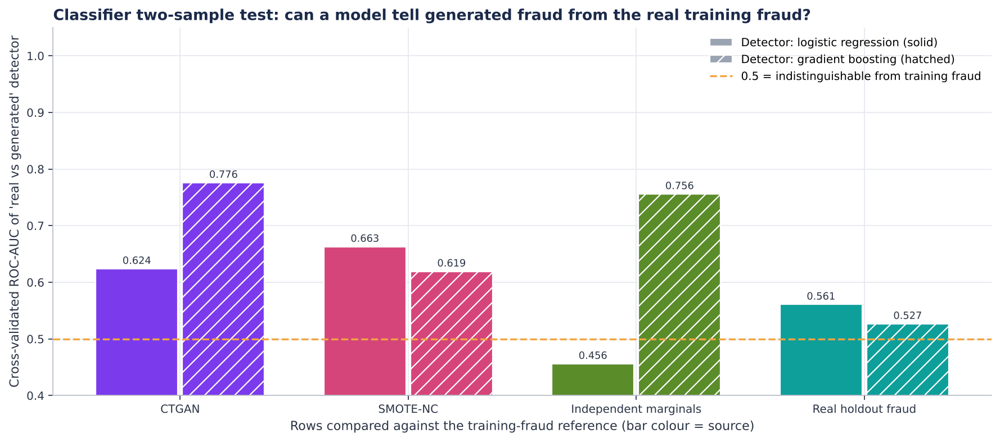

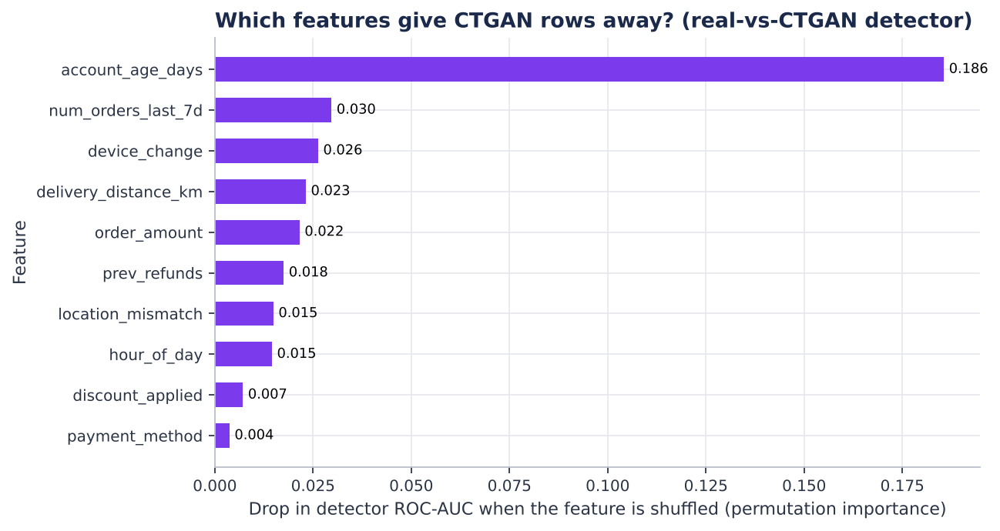

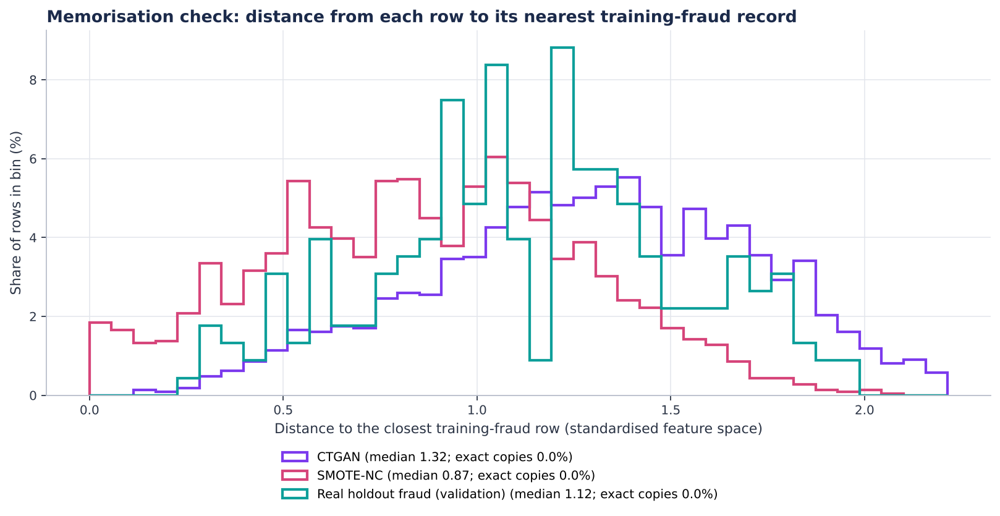

PosixPath('/home/claude/Noon_Fraud_Detection/outputs/gan_diagnostics/06_distance_to_closest_record.png')

In [20]:
def real_holdout_reference():
    return X_val[y_val.values == 1]   # used ONLY as a measuring stick (real-vs-real), never for training or selection

fid_rows = {}
for nm, d in [("CTGAN (600 ep)" if not DEV else "CTGAN", pools["B_ctgan"]), ("SMOTE-NC", pools["D_smote_nc"]),
              ("Independent marginals", pools["F_independent_marginals"]),
              ("Real holdout fraud (validation) — reference", real_holdout_reference())]:
    fid_rows[nm] = G.sdmetrics_scores(fraud_tr, d)
epoch_pools = {}
for ep, g_ in gans_by_epoch.items():
    if ep == GAN_EPOCHS:
        continue
    epoch_pools[ep], _ = g_.sample_valid(len(fraud_tr))
    fid_rows[f"CTGAN ({ep} ep)"] = G.sdmetrics_scores(fraud_tr, epoch_pools[ep])
fid = pd.DataFrame(fid_rows).T
display(fid.style.format("{:.3f}").set_caption("SDMetrics (1 = identical to training fraud); pair-trend thresholds set to 0"))
fid.to_csv(OUT["gan"] / "sdmetrics_scores.csv")

c2 = {}
for nm, d in [("CTGAN", pools["B_ctgan"]), ("SMOTE-NC", pools["D_smote_nc"]),
              ("Independent marginals", pools["F_independent_marginals"]), ("Real holdout fraud", real_holdout_reference())]:
    c2[nm] = G.c2st(fraud_tr, d, SEED)
c2_tab = pd.DataFrame({k: {kk: vv for kk, vv in v.items() if kk != "importance"} for k, v in c2.items()}).T
display(c2_tab.style.format({"n_per_source": "{:.0f}", "AUC — Logistic regression": "{:.3f}", "AUC — Gradient boosting": "{:.3f}"}))
c2_tab.to_csv(OUT["gan"] / "c2st_results.csv")
P.c2st_chart(c2_tab[["AUC — Logistic regression", "AUC — Gradient boosting"]],
             {"CTGAN": GAN, "SMOTE-NC": ARM_COLORS["D_smote_nc"], "Independent marginals": ARM_COLORS["F_independent_marginals"],
              "Real holdout fraud": REAL_REF}, OUT["gan"] / "04_two_sample_test.png")
imp = c2["CTGAN"]["importance"]
fig, ax = plt.subplots(figsize=(8, 4.2), constrained_layout=True)
bars = ax.barh(imp.index[::-1], imp.values[::-1], color=GAN, height=0.6)
for b, val in zip(bars, imp.values[::-1]):
    ax.annotate(f"{val:.3f}", (max(val, 0), b.get_y() + b.get_height() / 2), xytext=(3, 0), textcoords="offset points", va="center", fontsize=8)
ax.set_xlabel("Drop in detector ROC-AUC when the feature is shuffled (permutation importance)")
ax.set_ylabel("Feature")
ax.set_title("Which features give CTGAN rows away? (real-vs-CTGAN detector)")
P.save(fig, OUT["gan"] / "05_c2st_feature_importance.png")

dcr = {"CTGAN": G.distance_to_closest_record(pools["B_ctgan"], fraud_tr),
       "SMOTE-NC": G.distance_to_closest_record(pools["D_smote_nc"], fraud_tr),
       "Real holdout fraud (validation)": G.distance_to_closest_record(real_holdout_reference(), fraud_tr)}
P.dcr_chart(dcr, {"CTGAN": GAN, "SMOTE-NC": ARM_COLORS["D_smote_nc"], "Real holdout fraud (validation)": REAL_REF},
            OUT["gan"] / "06_distance_to_closest_record.png")

,epochs,Column Shapes,Column Pair Trends,LogisticDetection,C2ST AUC (gradient boosting; 0.5 ideal),KS account_age_days,ATO-signature share
0,100,0.858,0.871,0.426,0.893,0.389,0.008
1,300,0.889,0.881,0.601,0.828,0.162,0.039
2,600,0.912,0.893,0.731,0.787,0.167,0.046
3,1000,0.882,0.883,0.658,0.796,0.294,0.062


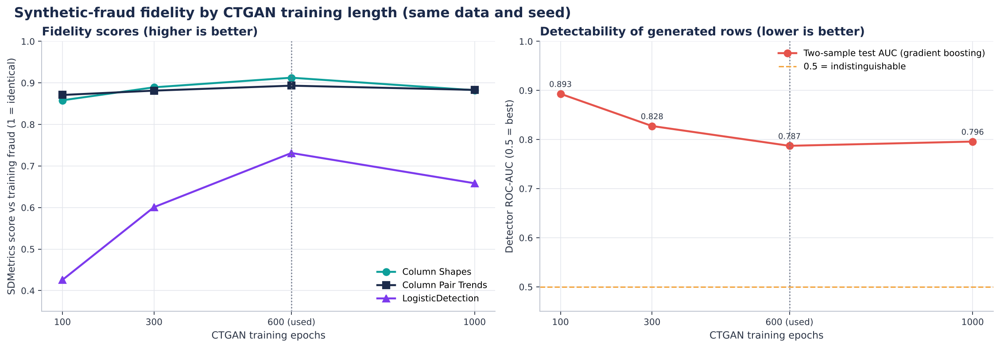

[FINDING] Fidelity summary vs training fraud (fidelity to the SEED, not to Noon's real fraud):
  • C2ST gradient-boosting AUC — CTGAN 0.776, Independent marginals 0.756, SMOTE-NC 0.619, real holdout 0.527 (0.5 = indistinguishable).
  • Account-takeover signature: training fraud 3.7%, CTGAN 4.4%, independent marginals 1.1%.


In [21]:
if not DEV:
    ep_rows = []
    for ep in sorted(gans_by_epoch):
        dd = pools["B_ctgan"].iloc[:len(fraud_tr)] if ep == GAN_EPOCHS else epoch_pools[ep]
        s = G.sdmetrics_scores(fraud_tr, dd)
        cc = G.c2st(fraud_tr, dd, SEED)
        ep_rows.append({"epochs": ep, "Column Shapes": s["quality: Column Shapes"], "Column Pair Trends": s["quality: Column Pair Trends"],
                        "LogisticDetection": s["LogisticDetection (1 = indistinguishable)"],
                        "C2ST AUC (gradient boosting; 0.5 ideal)": cc["AUC — Gradient boosting"],
                        "KS account_age_days": G.marginal_distances(fraud_tr, dd).set_index("column").loc["account_age_days", "ks_stat"],
                        "ATO-signature share": float(list(G.SIGNATURES.values())[0](dd).mean())})
    ep_tab = pd.DataFrame(ep_rows)
    display(ep_tab.style.format(precision=3))
    ep_tab.to_csv(OUT["gan"] / "epoch_sensitivity.csv", index=False)
    P.epoch_sensitivity(ep_tab, GAN_EPOCHS, OUT["gan"] / "07_epoch_sensitivity.png")

print("[FINDING] Fidelity summary vs training fraud (fidelity to the SEED, not to Noon's real fraud):")
print(f"  • C2ST gradient-boosting AUC — CTGAN {c2_tab.loc['CTGAN', 'AUC — Gradient boosting']:.3f}, "
      f"Independent marginals {c2_tab.loc['Independent marginals', 'AUC — Gradient boosting']:.3f}, "
      f"SMOTE-NC {c2_tab.loc['SMOTE-NC', 'AUC — Gradient boosting']:.3f}, real holdout {c2_tab.loc['Real holdout fraud', 'AUC — Gradient boosting']:.3f} (0.5 = indistinguishable).")
print(f"  • Account-takeover signature: training fraud {sig.iloc[0, 0]:.1%}, CTGAN {sig.iloc[0, 1]:.1%}, "
      f"independent marginals {sig.iloc[0, 3]:.1%}.")

### What the GAN validation shows

* **[FINDING] It is a genuine, trained GAN.** A 220,810-parameter generator was trained adversarially for 600 epochs (≈6,000 updates) on the 1,058 training-partition fraud rows only. Generator loss fell from ≈ +0.9 (mean of the first 50 epochs) to ≈ −2.0 and flattened; discriminator loss stayed near 0 throughout — a balanced adversarial game with no divergence. Fidelity improved from 100 → 300 → 600 epochs. The saved generator reloads, and refitting it with the same seed reproduces the identical loss curve and identical rows.
* **[FINDING] It learned joint structure, not just columns.** Its pairwise-correlation error (mean |Δρ| 0.079) is well below the no-structure ablation's (0.111), and it reproduces the account-takeover signature (4.4% of rows vs 3.7% in training fraud; independent marginals 1.1%, SMOTE-NC 0.9%) and the stolen-card signature (10.7% vs 10.2%).
* **[FINDING] It did not memorise.** Zero exact copies; its rows sit farther from the nearest training record (median distance 1.32) than genuinely new real fraud does (1.12). SMOTE-NC stays much closer (0.87) because it interpolates between real neighbours.
* **[FINDING] It is still detectable, and one column explains most of that.** A gradient-boosting detector separates CTGAN rows from training fraud with AUC 0.78 (real-vs-real: 0.53). Permutation importance points at `account_age_days` (0.186; the next feature is 0.030). Training fraud has a narrow brand-new-account mode — 13.8% at 0 days and 35.3% at 1–10 days — while CTGAN puts 31.0% at 0 days and only 6.3% at 1–10 days: the Gaussian-mixture encoding fits this sharp, zero-bounded mode poorly, and floor-clipping concentrates the spill-over at 0. Secondary distortions: device change over-produced (31.9% vs 20.1%), fewer zero-order weeks (21.9% vs 33.4%), a heavier basket tail (> AED 200: 21.6% vs 11.1%). The sharp promo-abuse (15.3% vs 22.9%) and COD-fake (1.5% vs 4.2%) signatures are under-produced; refund abuse is over-produced (17.8% vs 12.9%).
* **Reading note.** The logistic detector's AUC of 0.456 for independent marginals is below 0.5 because cross-validation is negatively biased when one sample is resampled from the other's own values; read it as "indistinguishable on marginals". Its gradient-boosting AUC (0.756) exposes the missing interactions.
* Everything in this section is fidelity **to my seed data**, not to Noon's fraud.
* **Reproducibility note.** SDMetrics' `LogisticDetection` uses an internal 3-fold split with no fixed seed, so its value moves by up to about ±0.02 between runs; no decision depends on it. Every other number in this notebook reproduces exactly from the seeds (verified by a second complete run).

## 1.8 Controlled before-versus-after experiments

**What the metrics mean for Noon (fraud = positive class).** *Recall* = share of fraudulent orders caught (money saved). *Precision* = share of flagged orders that really are fraud (analyst workload and customer friction per alert). *F1* balances the two. *Average precision (PR-AUC)* scores the whole ranking without a threshold; chance level equals the fraud rate (3%). *Specificity* = share of legitimate orders left alone; *false positives* are the legitimate customers who get blocked or challenged. Accuracy is shown but never used to decide anything: always answering "legit" is 97% accurate.

**Fairness rules.** Same classifier configuration and hyper-parameters in every arm; same training partition; same validation set for choosing the augmentation ratio and the threshold; the test set is scored **once per arm**, after everything is frozen. Each generator arm (B, D, E, F) gets the same tuning budget: ratios 0.25×, 0.5×, 1×, 2× the training-fraud count.

arm,B_ctgan,D_smote_nc,E_random_oversampling,F_independent_marginals
ratio,,,,
0.250000,0.5213,0.5151,0.5209,0.5201
0.500000,0.4988,0.5120,0.5177,0.5085
1.000000,0.4783,0.5086,0.5179,0.4892
2.000000,0.4572,0.4810,0.5153,0.4752


Selected ratios (validation AP): {'B_ctgan': 0.25, 'D_smote_nc': 0.25, 'E_random_oversampling': 0.25, 'F_independent_marginals': 0.25}


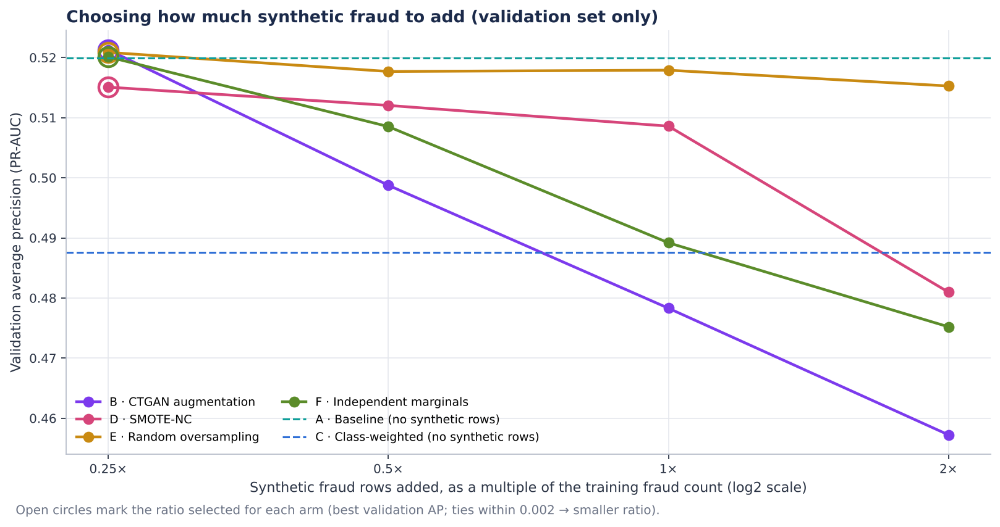

VALIDATION (used for every decision):


,synthetic rows added,threshold,recall,precision,f1,pr_auc_ap,roc_auc,specificity,balanced_accuracy,accuracy,TP,FP,TN,FN,flagged,brier
A · Baseline,0,0.2817,0.5463,0.5611,0.5536,0.5199,0.9434,0.9867,0.7665,0.9733,124.0000,97.0000,7176.0000,103.0000,221.0000,0.0192
C · Class-weighted,0,0.9009,0.5286,0.5455,0.5369,0.4876,0.9414,0.9863,0.7574,0.9724,120.0000,100.0000,7173.0000,107.0000,220.0000,0.0792
E · Random oversampling,264,0.2658,0.5947,0.5153,0.5521,0.5209,0.9427,0.9825,0.7886,0.9708,135.0000,127.0000,7146.0000,92.0000,262.0000,0.0192
D · SMOTE-NC,264,0.3025,0.5507,0.5411,0.5459,0.5151,0.9418,0.9854,0.7680,0.9723,125.0000,106.0000,7167.0000,102.0000,231.0000,0.0193
F · Independent marginals,264,0.2498,0.6123,0.5018,0.5516,0.5201,0.9458,0.9810,0.7967,0.9699,139.0000,138.0000,7135.0000,88.0000,277.0000,0.0192
B · CTGAN augmentation,264,0.3532,0.5286,0.6000,0.5621,0.5213,0.9431,0.9890,0.7588,0.9751,120.0000,80.0000,7193.0000,107.0000,200.0000,0.0192


TEST (scored once, after freezing):


,synthetic rows added,threshold,recall,precision,f1,pr_auc_ap,roc_auc,specificity,balanced_accuracy,accuracy,TP,FP,TN,FN,flagged,brier
A · Baseline,0,0.2817,0.5110,0.5446,0.5273,0.5165,0.9376,0.9867,0.7488,0.9723,116.0000,97.0000,7176.0000,111.0000,213.0000,0.0197
C · Class-weighted,0,0.9009,0.4758,0.5217,0.4977,0.4544,0.9358,0.9864,0.7311,0.9709,108.0000,99.0000,7174.0000,119.0000,207.0000,0.0782
E · Random oversampling,264,0.2658,0.5771,0.4906,0.5304,0.5247,0.9379,0.9813,0.7792,0.9691,131.0000,136.0000,7137.0000,96.0000,267.0000,0.0197
D · SMOTE-NC,264,0.3025,0.5154,0.5132,0.5143,0.5166,0.9389,0.9847,0.7501,0.9705,117.0000,111.0000,7162.0000,110.0000,228.0000,0.0198
F · Independent marginals,264,0.2498,0.5595,0.4585,0.5040,0.5189,0.9341,0.9794,0.7694,0.9667,127.0000,150.0000,7123.0000,100.0000,277.0000,0.0198
B · CTGAN augmentation,264,0.3532,0.4890,0.5781,0.5298,0.5100,0.9367,0.9889,0.7389,0.9737,111.0000,81.0000,7192.0000,116.0000,192.0000,0.0198


In [22]:
grid, RATIOS = X.select_ratios(FAMILY, PARAMS, SEED, X_tr, y_tr, pools, X_val, y_val)
display(grid.pivot(index="ratio", columns="arm", values="val_ap").style.format("{:.4f}").highlight_max(color="#E7DEFF"))
grid.to_csv(OUT["metrics"] / "augmentation_ratio_selection_validation.csv", index=False)
print("Selected ratios (validation AP):", RATIOS)

results = X.run_arms(FAMILY, PARAMS, SEED, X_tr, y_tr, X_val, y_val, X_te, y_te, pools, RATIOS)
refs = {a: results[a]["val"]["pr_auc_ap"] for a in ["A_baseline", "C_class_weighted"]}
P.ratio_selection(grid, refs, RATIOS, OUT["metrics"] / "02_augmentation_ratio_selection.png",
                  "Choosing how much synthetic fraud to add (validation set only)")
for a, r in results.items():
    assert E.verify_metrics(y_te, r["p_test"], r["threshold"], r["test"]), a

def table(split):
    t = pd.DataFrame({ARMS[a]: r[split] for a, r in results.items()}).T
    t.insert(0, "synthetic rows added", [int(round((results[a]["ratio"] or 0) * len(fraud_tr))) if a in X.GENERATOR_ARMS else 0 for a in results])
    return t[["synthetic rows added", "threshold", "recall", "precision", "f1", "pr_auc_ap", "roc_auc", "specificity",
              "balanced_accuracy", "accuracy", "TP", "FP", "TN", "FN", "flagged", "brier"]]
val_tab, test_tab = table("val"), table("test")
print("VALIDATION (used for every decision):")
display(val_tab.style.format(precision=4))
print("TEST (scored once, after freezing):")
display(test_tab.style.format(precision=4).background_gradient(subset=["f1", "pr_auc_ap"], cmap="Purples"))
val_tab.to_csv(OUT["metrics"] / "arms_validation_metrics.csv")
test_tab.to_csv(OUT["metrics"] / "arms_test_metrics.csv")

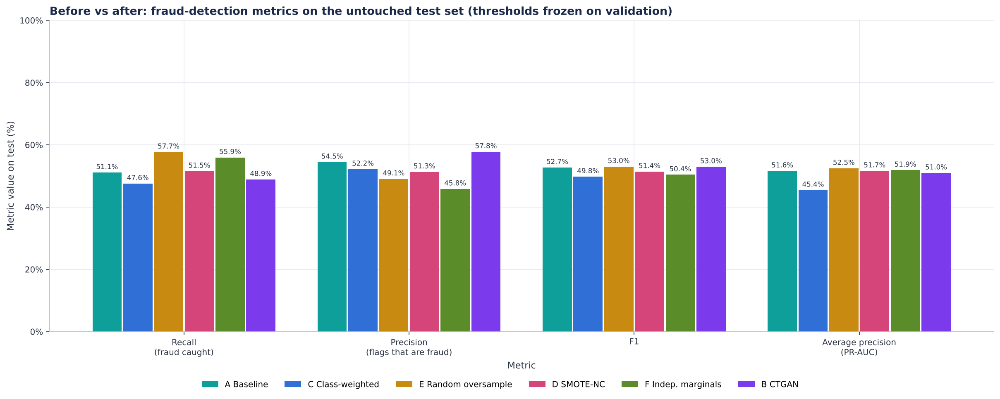

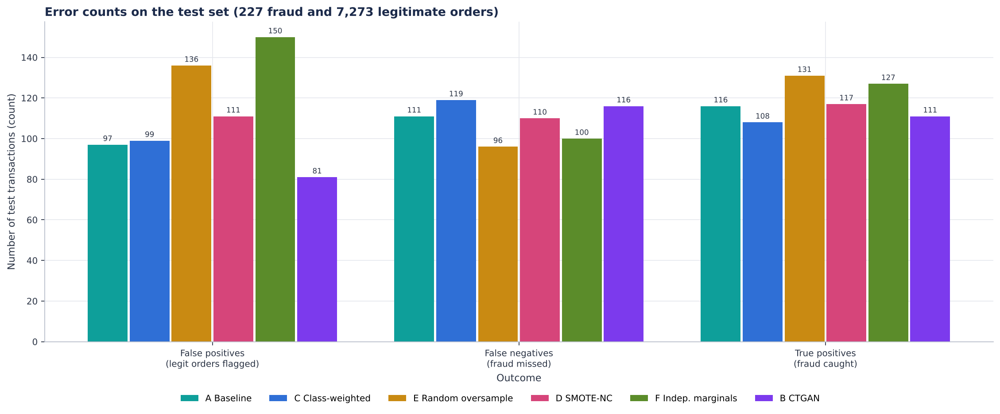

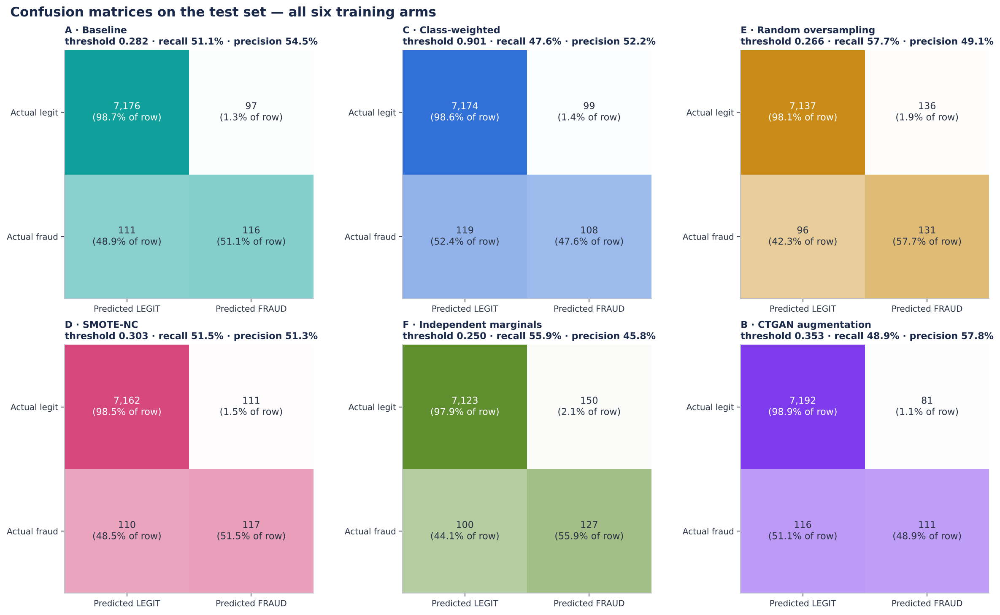

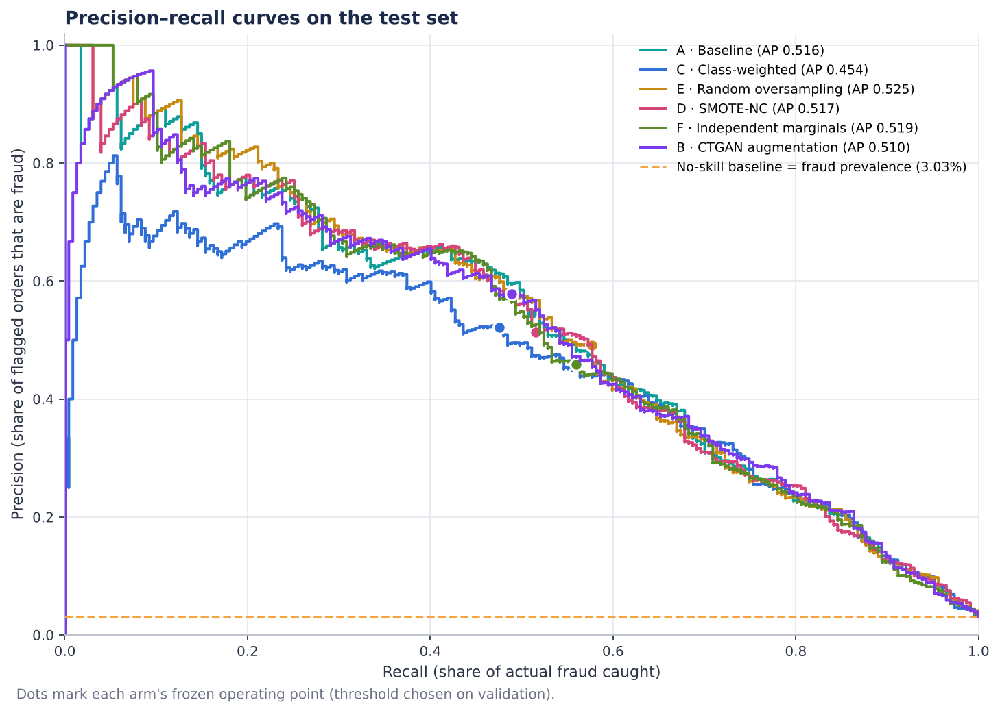

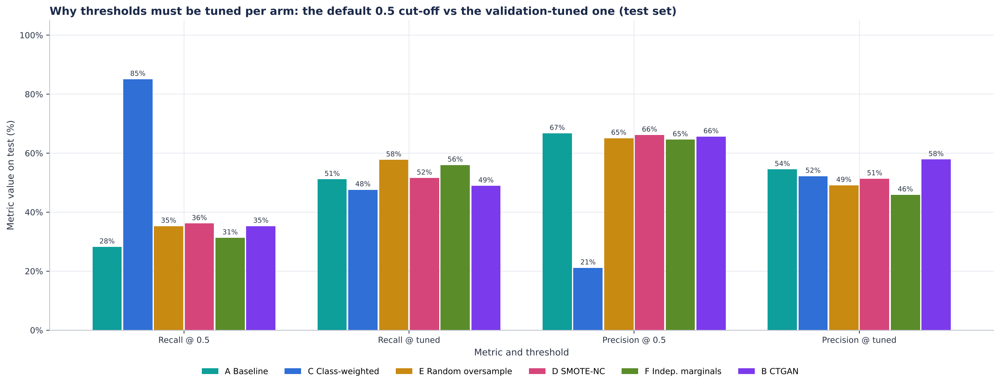

PosixPath('/home/claude/Noon_Fraud_Detection/outputs/metrics/06_default_vs_tuned_threshold.png')

In [23]:
bars = pd.DataFrame({P.SHORT[a]: [results[a]["test"][k] for k in ["recall", "precision", "f1", "pr_auc_ap"]] for a in ARM_ORDER},
                    index=["Recall\n(fraud caught)", "Precision\n(flags that are fraud)", "F1", "Average precision\n(PR-AUC)"])
P.grouped_bars(bars, {P.SHORT[a]: ARM_COLORS[a] for a in ARM_ORDER}, OUT["metrics"] / "03_before_after_test_metrics.png",
               "Before vs after: fraud-detection metrics on the untouched test set (thresholds frozen on validation)",
               "Metric value on test (%)", "Metric", fmt="{:.1%}", ylim=(0, 1.0), figsize=(15, 5.6), legend_loc="upper left")
cnt = pd.DataFrame({P.SHORT[a]: [results[a]["test"]["FP"], results[a]["test"]["FN"], results[a]["test"]["TP"]] for a in ARM_ORDER},
                   index=["False positives\n(legit orders flagged)", "False negatives\n(fraud missed)", "True positives\n(fraud caught)"])
P.grouped_bars(cnt, {P.SHORT[a]: ARM_COLORS[a] for a in ARM_ORDER}, OUT["metrics"] / "04_error_counts_test.png",
               f"Error counts on the test set ({int(y_te.sum())} fraud and {int((y_te == 0).sum()):,} legitimate orders)",
               "Number of test transactions (count)", "Outcome", fmt="{:.0f}", pct_axis=False, figsize=(14, 5.4), legend_loc="upper right")
P.confusion_grid({a: r["test"] for a, r in results.items()}, OUT["cm"] / "01_confusion_matrices_test.png",
                 "Confusion matrices on the test set — all six training arms")
P.pr_curves({a: (y_te.values, r["p_test"]) for a, r in results.items()},
            {a: (r["test"]["recall"], r["test"]["precision"]) for a, r in results.items()}, y_te.mean(),
            OUT["metrics"] / "05_precision_recall_curves_test.png", "Precision–recall curves on the test set")
thr_cmp = pd.DataFrame({P.SHORT[a]: [results[a]["test_at_05"]["recall"], results[a]["test"]["recall"],
                                     results[a]["test_at_05"]["precision"], results[a]["test"]["precision"]] for a in ARM_ORDER},
                       index=["Recall @ 0.5", "Recall @ tuned", "Precision @ 0.5", "Precision @ tuned"])
P.grouped_bars(thr_cmp, {P.SHORT[a]: ARM_COLORS[a] for a in ARM_ORDER}, OUT["metrics"] / "06_default_vs_tuned_threshold.png",
               "Why thresholds must be tuned per arm: the default 0.5 cut-off vs the validation-tuned one (test set)",
               "Metric value on test (%)", "Metric and threshold", fmt="{:.0%}", ylim=(0, 1.05), figsize=(15, 5.4), legend_loc="upper left")

,promo abuse (n = 58),refund abuse (n = 71),stolen card (n = 52),account takeover (n = 22),cod fake order (n = 15),label noise: legit recorded as fraud (n = 9)
A Baseline,50%,56%,56%,50%,47%,0%
C Class-weighted,50%,61%,42%,45%,27%,0%
E Random oversample,64%,61%,58%,59%,53%,0%
D SMOTE-NC,55%,55%,50%,55%,53%,0%
F Indep. marginals,59%,61%,60%,55%,47%,0%
B CTGAN,47%,56%,52%,50%,40%,0%


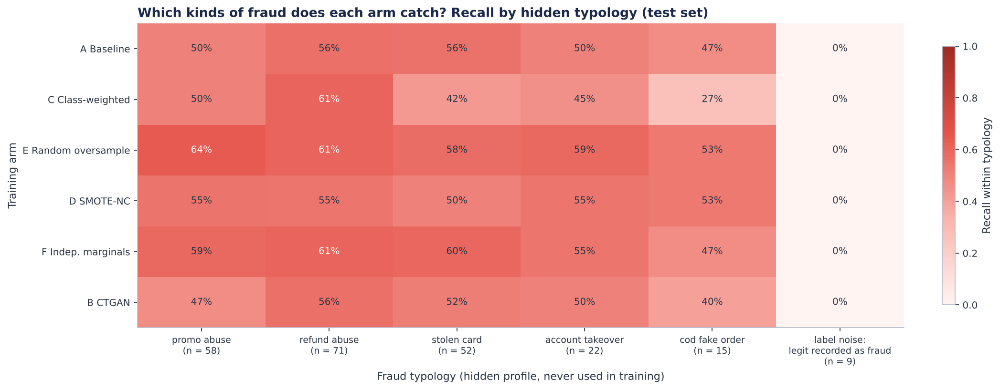

PosixPath('/home/claude/Noon_Fraud_Detection/outputs/metrics/07_recall_by_typology_test.png')

In [24]:
te_meta = seed_meta.iloc[te_idx].reset_index(drop=True)
te_fraud = (y_te.values == 1)
typ = np.where(te_meta.latent_profile.str.startswith("F_"), te_meta.latent_profile.str.replace("F_", "").str.replace("_", " "),
               "legit profile recorded as fraud (label noise)")
rows = {}
for a in ARM_ORDER:
    pred = results[a]["p_test"] >= results[a]["threshold"]
    s = pd.Series(pred[te_fraud]).groupby(typ[te_fraud]).mean()
    rows[P.SHORT[a]] = s
typo = pd.DataFrame(rows).T
order_cols = [c for c in ["promo abuse", "refund abuse", "stolen card", "account takeover", "cod fake order"] if c in typo.columns] \
             + [c for c in typo.columns if c.startswith("legit profile")]
typo = typo[order_cols]
counts = pd.Series(typ[te_fraud]).value_counts()
typo.columns = [("label noise:\nlegit recorded as fraud" if c.startswith("legit profile") else c) + f"\n(n = {counts[c]})" for c in typo.columns]
display(typo.style.format("{:.0%}"))
typo.to_csv(OUT["metrics"] / "recall_by_typology_test.csv")
P.heat_table(typo, OUT["metrics"] / "07_recall_by_typology_test.png", "Which kinds of fraud does each arm catch? Recall by hidden typology (test set)",
             "Fraud typology (hidden profile, never used in training)", "Training arm", fmt="{:.0%}", cbar_label="Recall within typology",
             figsize=(13, 5))

## 1.9 Choosing the strongest classifier (pre-declared rule, validation data only)

In [25]:
val_ap = pd.Series({a: results[a]["val"]["pr_auc_ap"] for a in ARM_ORDER})
best = val_ap.idxmax()
FINAL_ARM = best
if val_ap[best] - val_ap["A_baseline"] < FINAL_MODEL_TOL:
    eligible = [a for a in SIMPLICITY_ORDER if val_ap[a] >= val_ap[best] - FINAL_MODEL_TOL]
    FINAL_ARM = eligible[0]
display(val_ap.rename(index=ARMS).to_frame("validation AP").assign(
    margin_vs_baseline=lambda t: t["validation AP"] - val_ap["A_baseline"]).style.format("{:+.4f}", subset=["margin_vs_baseline"]).format("{:.4f}", subset=["validation AP"]))
print(f"[FINDING] Highest validation AP: {ARMS[best]} ({val_ap[best]:.4f}); margin over Baseline {val_ap[best] - val_ap['A_baseline']:+.4f}.")
print(f"[FINDING] Selected Phase 1 classifier under the pre-declared rule: {ARMS[FINAL_ARM]}")
print(f"          The CTGAN-augmented classifier ({ARMS['B_ctgan']}) is saved separately for the Phase 3 real-data test either way.")
d_fp = results["B_ctgan"]["val"]["FP"] - results["A_baseline"]["val"]["FP"]
print(f"          Validation trade-off of CTGAN vs Baseline: recall {results['B_ctgan']['val']['recall'] - results['A_baseline']['val']['recall']:+.3f}, "
      f"precision {results['B_ctgan']['val']['precision'] - results['A_baseline']['val']['precision']:+.3f}, false positives {d_fp:+d}.")

,validation AP,margin_vs_baseline
A · Baseline,0.5199,+0.0000
C · Class-weighted,0.4876,-0.0323
E · Random oversampling,0.5209,+0.0009
D · SMOTE-NC,0.5151,-0.0048
F · Independent marginals,0.5201,+0.0002
B · CTGAN augmentation,0.5213,+0.0014


[FINDING] Highest validation AP: B · CTGAN augmentation (0.5213); margin over Baseline +0.0014.
[FINDING] Selected Phase 1 classifier under the pre-declared rule: A · Baseline
          The CTGAN-augmented classifier (B · CTGAN augmentation) is saved separately for the Phase 3 real-data test either way.
          Validation trade-off of CTGAN vs Baseline: recall -0.018, precision +0.039, false positives -17.


### Reading the experiment

* **[FINDING] Less is more for every generator.** All four generator arms chose the smallest ratio (0.25× = 264 synthetic rows). For CTGAN, validation AP falls steadily as more rows are added (0.521 → 0.499 → 0.478 → 0.457 at 2×): imperfect synthetic fraud, in volume, teaches the classifier the generator's artefacts — such as the 0-day spike.
* **[FINDING] CTGAN at 0.25× did not catch more fraud.** Test recall 48.9% vs 51.1% (111 vs 116 frauds caught), precision 57.8% vs 54.5%, F1 0.530 vs 0.527, AP 0.510 vs 0.516. It flagged 16 fewer legitimate orders (81 vs 97) and missed 5 more frauds. Because each arm's threshold maximises its own validation F1, this is a different *operating point*, not a better ranking.
* **[FINDING] Class weighting hurt** this gradient-boosting model (AP 0.454 vs 0.516): it pushes every score up (its F1-optimal threshold is 0.90) and loses ranking quality — consistent with published evidence that re-balancing rarely helps strong learners.
* **[FINDING] Duplication and the no-structure ablation** catch more fraud (recall 57.7% and 55.9%) but pay with many more false alarms (136 and 150 vs 97). **SMOTE-NC** is indistinguishable from the Baseline.
* **[FINDING] The default 0.5 threshold would have reversed the story.** Class weighting would look like a recall miracle (85%) at 21% precision, while the Baseline would catch only 28%. Tuning every arm's threshold on validation is what makes the comparison fair.
* **[FINDING] By typology,** the Baseline catches roughly half of every kind of fraud (47–56%). CTGAN lowers recall for promo abuse (47% vs 50%), stolen card (52% vs 56%) and COD fakes (40% vs 47%, only 15 cases) and leaves refund abuse and account takeover unchanged; the largest drops are in the two typologies it under-produces. The 9 label-noise rows (legitimate behaviour recorded as fraud) are caught by no arm, as expected.
* **Decision under the pre-declared rule:** CTGAN had the highest validation AP (0.5213) but beat the Baseline (0.5199) by only 0.0014 < 0.01, so the simpler **Baseline is the selected Phase 1 model**. The CTGAN-augmented model is saved and will be scored on Noon's real data in Phase 3 as well.

## 1.10 Assumption-shift stress test

The biggest risk in a synthetic-data project is that the classifier learns **the generator's assumptions** rather than fraud. Four fresh datasets (20,000 rows, 3% fraud, new seeds) score the **frozen** models; none of them influenced any decision above.

| Scenario | What changes (documented alternative assumption) |
|---|---|
| S0 In-distribution | Nothing — a fresh draw from the training generator (reference) |
| S1 Population drift | Legitimate customers change: COD 14→22%, foreign-card mismatch 14→22%, device change 3.5→6%, more new accounts (8→14%) |
| S2 Adaptive fraud | Stolen cards move to Apple Pay with smaller baskets and less mismatch; takeovers without device change (session hijack); promo abusers age their accounts and buy bigger baskets; refund abusers have fewer prior claims; no night uplift |
| S3 Unseen typology | 30% of fraud is a pattern absent from training: wallet laundering (established accounts, wallet, very large baskets, no discount) |

arm,A · Baseline,C · Class-weighted,E · Random oversampling,D · SMOTE-NC,F · Independent marginals,B · CTGAN augmentation
scenario,,,,,,
S0_in_distribution,0.546,0.502,0.545,0.538,0.534,0.533
S1_population_drift,0.470,0.456,0.469,0.466,0.458,0.469
S2_adaptive_fraud,0.242,0.212,0.238,0.247,0.247,0.246
S3_unseen_typology,0.438,0.401,0.428,0.428,0.434,0.443


arm,A · Baseline,C · Class-weighted,E · Random oversampling,D · SMOTE-NC,F · Independent marginals,B · CTGAN augmentation
scenario,,,,,,
S0_in_distribution,54.1%,50.4%,58.8%,55.0%,58.3%,49.6%
S1_population_drift,53.6%,52.6%,59.2%,54.3%,59.5%,50.8%
S2_adaptive_fraud,21.5%,19.9%,26.3%,23.5%,29.0%,20.9%
S3_unseen_typology,40.2%,39.2%,44.3%,41.7%,46.0%,37.1%


arm,A · Baseline,C · Class-weighted,E · Random oversampling,D · SMOTE-NC,F · Independent marginals,B · CTGAN augmentation
scenario,,,,,,
S0_in_distribution,296,298,396,318,419,262
S1_population_drift,435,448,609,491,659,364
S2_adaptive_fraud,258,271,372,294,401,216
S3_unseen_typology,245,267,335,268,386,202


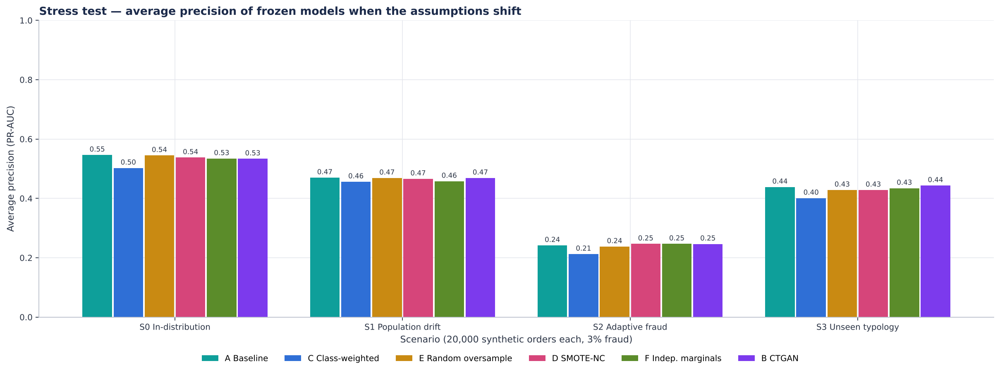

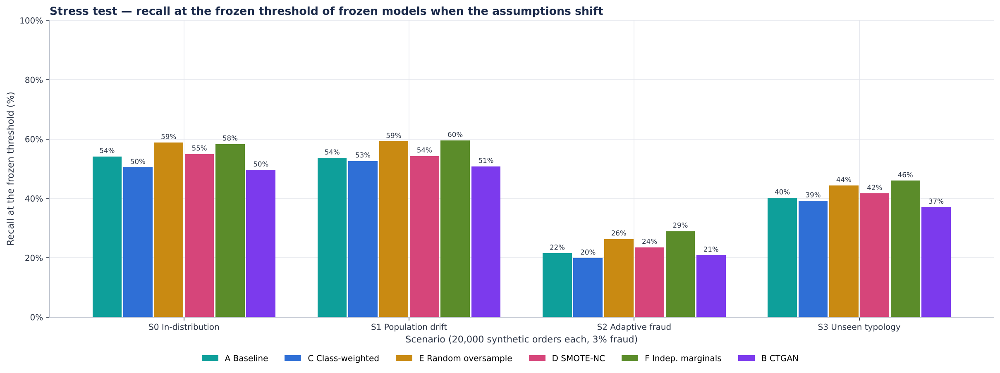

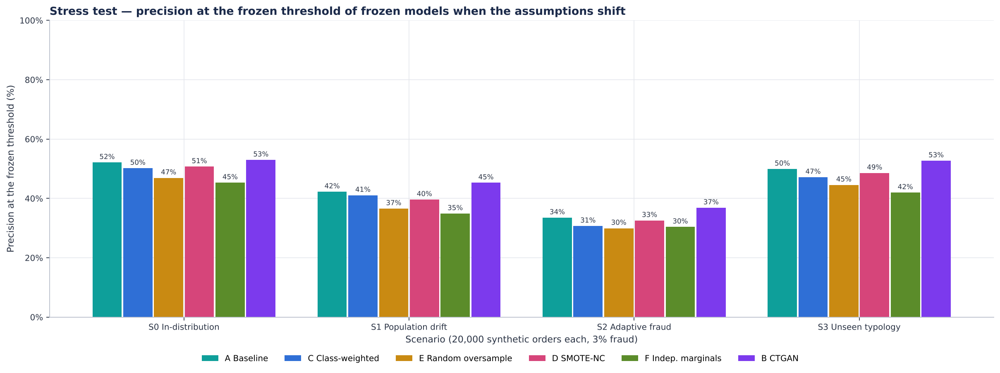

,account_takeover,cod_fake_order,label noise,promo_abuse,refund_abuse,stolen_card,wallet_laundering
S0 In-distribution · A Baseline,51%,39%,0%,57%,56%,57%,–
S0 In-distribution · B CTGAN,51%,32%,0%,45%,56%,55%,–
S1 Population drift · A Baseline,47%,68%,0%,53%,60%,52%,–
S1 Population drift · B CTGAN,49%,59%,0%,47%,58%,52%,–
S2 Adaptive fraud · A Baseline,18%,46%,0%,15%,26%,25%,–
S2 Adaptive fraud · B CTGAN,18%,46%,0%,12%,28%,23%,–
S3 Unseen typology · A Baseline,48%,71%,0%,57%,59%,49%,11%
S3 Unseen typology · B CTGAN,42%,62%,0%,46%,59%,51%,11%


[FINDING] Drop in average precision vs the in-distribution draw (positive = worse):


arm,A · Baseline,C · Class-weighted,E · Random oversampling,D · SMOTE-NC,F · Independent marginals,B · CTGAN augmentation
scenario,,,,,,
S0_in_distribution,+0.000,+0.000,+0.000,+0.000,+0.000,+0.000
S1_population_drift,+0.076,+0.046,+0.076,+0.072,+0.076,+0.065
S2_adaptive_fraud,+0.305,+0.290,+0.307,+0.291,+0.288,+0.287
S3_unseen_typology,+0.108,+0.101,+0.116,+0.109,+0.100,+0.090


In [26]:
stress_rows, stress_typ = [], {}
for sc, sd in STRESS_SEEDS.items():
    sdf, smeta = generate_transactions(N_STRESS, PREVALENCE, sd, scenario_params(sc))
    assert validate_schema(sdf)["passed"].all()
    for a in ARM_ORDER:
        p = results[a]["model"].predict_proba(sdf[FEATURES])[:, 1]
        m = E.compute_metrics(sdf[TARGET], p, results[a]["threshold"])
        stress_rows.append({"scenario": sc, "arm": a, **m})
        if a == FINAL_ARM or a == "B_ctgan":
            f = sdf[TARGET].values == 1
            t_ = np.where(smeta.latent_profile.str.startswith("F_"), smeta.latent_profile.str[2:], "label noise")
            stress_typ[(sc, a)] = pd.Series((p >= results[a]["threshold"])[f]).groupby(t_[f]).mean()
stress = pd.DataFrame(stress_rows)
stress.to_csv(OUT["robust"] / "stress_test_metrics.csv", index=False)
piv = stress.pivot(index="scenario", columns="arm", values="pr_auc_ap")[ARM_ORDER]
display(piv.rename(columns=ARMS).style.format("{:.3f}").set_caption("Average precision of frozen models under each scenario"))
display(stress.pivot(index="scenario", columns="arm", values="recall")[ARM_ORDER].rename(columns=ARMS).style.format("{:.1%}").set_caption("Recall at frozen thresholds"))
display(stress.pivot(index="scenario", columns="arm", values="FP")[ARM_ORDER].rename(columns=ARMS).style.format("{:.0f}").set_caption("False positives at frozen thresholds"))
sc_lab = {"S0_in_distribution": "S0 In-distribution", "S1_population_drift": "S1 Population drift",
          "S2_adaptive_fraud": "S2 Adaptive fraud", "S3_unseen_typology": "S3 Unseen typology"}
for metric, fname, lab, ylim in [("pr_auc_ap", "01_stress_average_precision.png", "Average precision (PR-AUC)", (0, 1)),
                                 ("recall", "02_stress_recall.png", "Recall at the frozen threshold (%)", (0, 1)),
                                 ("precision", "03_stress_precision.png", "Precision at the frozen threshold (%)", (0, 1))]:
    pv = stress.pivot(index="scenario", columns="arm", values=metric)[ARM_ORDER].rename(index=sc_lab, columns=P.SHORT)
    P.grouped_bars(pv, {P.SHORT[a]: ARM_COLORS[a] for a in ARM_ORDER}, OUT["robust"] / fname,
                   f"Stress test — {lab.split(' (')[0].lower()} of frozen models when the assumptions shift",
                   lab, "Scenario (20,000 synthetic orders each, 3% fraud)", fmt="{:.2f}" if metric == "pr_auc_ap" else "{:.0%}",
                   ylim=ylim, figsize=(15, 5.2), legend_loc="upper right", pct_axis=metric != "pr_auc_ap")
st = pd.DataFrame({f"{sc_lab[k[0]]} · {P.SHORT[k[1]]}": v for k, v in stress_typ.items()}).T
display(st.style.format("{:.0%}", na_rep="–").set_caption("Recall by fraud typology under each scenario"))
st.to_csv(OUT["robust"] / "stress_recall_by_typology.csv")
drop = piv.loc["S0_in_distribution"] - piv
print("[FINDING] Drop in average precision vs the in-distribution draw (positive = worse):")
display(drop.rename(columns=ARMS).style.format("{:+.3f}"))

### What the stress test shows

* **[FINDING] Population drift (S1)** costs about 0.08 AP and, more importantly, raises false alarms at the frozen threshold by ~47% for the Baseline (296 → 435 per 20,000 orders): a frozen threshold is fragile when *legitimate* behaviour shifts.
* **[FINDING] Adaptive fraud (S2)** halves AP for every arm (≈ 0.55 → 0.24); promo-abuse recall falls to ~15% and account-takeover recall to ~18% once those patterns move.
* **[FINDING] An unseen typology (S3)** is almost invisible: wallet laundering is caught 11% of the time by both the Baseline and the CTGAN model.
* **[FINDING] CTGAN augmentation buys no robustness** (AP within ±0.013 of the Baseline in every scenario): a GAN can only re-express the fraud it was shown.
* **[HYPOTHESIS]** The same weakness applies to Noon's real data. If the typologies I assumed differ from Noon's real fraud, Phase 3 should show S2/S3-like drops — for my classifier and for anything my GAN produced.

## 1.11 Probability calibration and threshold sensitivity

Resampling and synthetic fraud shift predicted probabilities upwards (the model sees far more fraud in training than exists in reality), so raw scores are not trustworthy *probabilities*. A sigmoid (Platt) recalibration is fitted on the **validation** set only and checked on the test set. Calibration is monotone, so it changes what the probability *means* but not which orders are flagged — this is asserted below.

,arm,scores,brier,brier_skill_score,ECE (decile bins),mean predicted,observed fraud rate
0,A · Baseline,raw,0.0197,0.3299,0.0023,0.0304,0.0303
1,A · Baseline,calibrated,0.0197,0.3294,0.0035,0.0302,0.0303
2,B · CTGAN augmentation,raw,0.0198,0.3249,0.0047,0.0350,0.0303
3,B · CTGAN augmentation,calibrated,0.0198,0.3267,0.0028,0.0303,0.0303


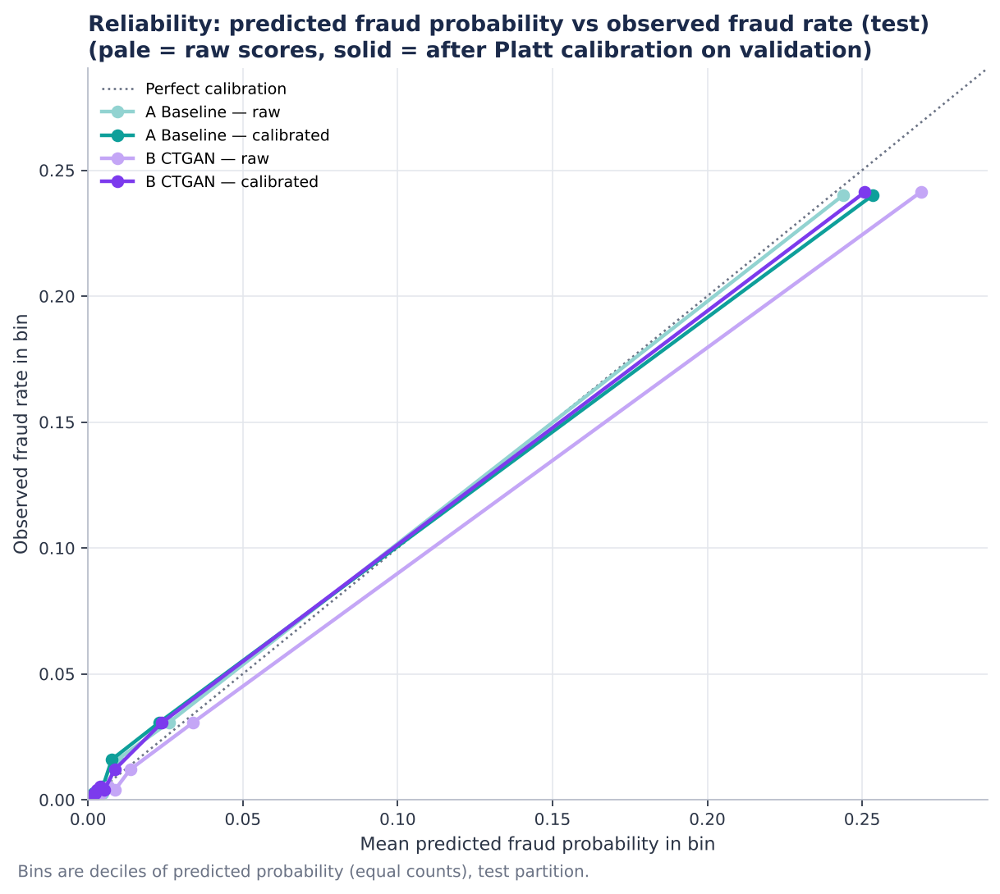

PosixPath('/home/claude/Noon_Fraud_Detection/outputs/metrics/08_reliability_diagram.png')

In [27]:
cal_models, cal_tables, cal_rows = {}, {}, []
for a in dict.fromkeys(["A_baseline", "B_ctgan", FINAL_ARM]):
    r = results[a]
    cal = M.PlattCalibrator().fit(r["p_val"], y_val.values)
    t_cal = float(cal.transform(np.array([r["threshold"]]))[0])
    p_te_cal = cal.transform(r["p_test"])
    assert ((p_te_cal >= t_cal - 1e-12) == (r["p_test"] >= r["threshold"])).mean() > 0.9999, "calibration changed decisions"
    cal_models[a] = M.FraudModel(pipeline=r["model"], threshold=t_cal, calibrator=cal,
                                 metadata={"arm": a, "arm_label": ARMS[a], "family": FAMILY, "params": PARAMS,
                                           "augmentation_ratio": r["ratio"], "raw_threshold": r["threshold"],
                                           "threshold_rule": "max F1 on validation", "calibration": "Platt sigmoid on validation",
                                           "seed": SEED, "trained_on": "data/seed_transactions.csv train partition"
                                           + (" + data/synthetic_fraud_gan.csv rows" if a == "B_ctgan" else ""),
                                           "prevalence_of_training_world": PREVALENCE,
                                           "warning": "Probabilities are calibrated to SYNTHETIC data only."})
    for nm, p in (("raw", r["p_test"]), ("calibrated", p_te_cal)):
        cal_rows.append({"arm": ARMS[a], "scores": nm, "brier": E.compute_metrics(y_te, p, 0.5)["brier"],
                         "brier_skill_score": E.brier_skill(y_te, p), "ECE (decile bins)": E.expected_calibration_error(y_te.values, p),
                         "mean predicted": float(np.mean(p)), "observed fraud rate": float(y_te.mean())})
        cal_tables[f"{P.SHORT[a]} — {nm}"] = E.reliability_table(y_te.values, p)
cal_df = pd.DataFrame(cal_rows)
display(cal_df.style.format(precision=4))
cal_df.to_csv(OUT["metrics"] / "calibration_test.csv", index=False)
cc = {}
for k in cal_tables:
    arm_k = [a for a in ARM_ORDER if k.startswith(P.SHORT[a] + " —")][0]
    cc[k] = ARM_COLORS[arm_k] if k.endswith("calibrated") else P.tint(ARM_COLORS[arm_k])
P.reliability(cal_tables, cc, OUT["metrics"] / "08_reliability_diagram.png",
              "Reliability: predicted fraud probability vs observed fraud rate (test)\n(pale = raw scores, solid = after Platt calibration on validation)")

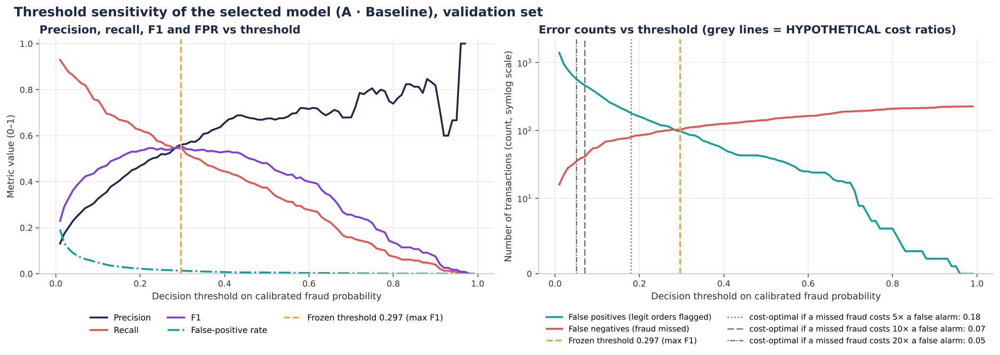

Hypothetical cost scenarios (ILLUSTRATIVE ratios, not Noon figures) → validation-optimal thresholds: {'cost-optimal if a missed fraud costs 5× a false alarm': 0.18, 'cost-optimal if a missed fraud costs 10× a false alarm': 0.07, 'cost-optimal if a missed fraud costs 20× a false alarm': 0.05}
[FINDING] Frozen threshold (max-F1 rule) on the calibrated scale: 0.2970 (raw-score threshold 0.2817).


,threshold,precision,recall,f1,fpr,FP,FN,TP,flagged
0,0.050,0.235,0.797,0.363,0.081,590,46,181,771
1,0.100,0.304,0.709,0.426,0.051,368,66,161,529
2,0.200,0.428,0.604,0.501,0.025,183,90,137,320
3,0.297,0.547,0.511,0.528,0.013,96,111,116,212
4,0.400,0.631,0.436,0.516,0.008,58,128,99,157
5,0.500,0.649,0.326,0.434,0.005,40,153,74,114
6,0.700,0.776,0.198,0.316,0.002,13,182,45,58


Saved models/fraud_model.joblib (selected), models/fraud_model_gan_augmented.joblib, models/fraud_model_baseline.joblib


In [28]:
final = cal_models[FINAL_ARM]
p_val_cal = final.calibrator.transform(results[FINAL_ARM]["p_val"])
sweep = E.threshold_sweep(y_val.values, p_val_cal)
sweep.to_csv(OUT["metrics"] / "threshold_sweep_validation.csv", index=False)
costs = {}
for ratio_fn in (5, 10, 20):
    t_c, _ = E.cost_optimal_threshold(y_val.values, p_val_cal, fn_cost=ratio_fn, fp_cost=1)
    costs[f"cost-optimal if a missed fraud\ncosts {ratio_fn}× a false alarm"] = t_c
P.threshold_sensitivity(sweep, final.threshold, OUT["metrics"] / "09_threshold_sensitivity_validation.png",
                        f"Threshold sensitivity of the selected model ({ARMS[FINAL_ARM]}), validation set", cost_points=costs)
print("Hypothetical cost scenarios (ILLUSTRATIVE ratios, not Noon figures) → validation-optimal thresholds:",
      {k.replace(chr(10), ' '): v for k, v in costs.items()})
print(f"[FINDING] Frozen threshold (max-F1 rule) on the calibrated scale: {final.threshold:.4f} "
      f"(raw-score threshold {final.metadata['raw_threshold']:.4f}).")
p_te_final = final.predict_proba(X_te)
display(E.threshold_sweep(y_te.values, p_te_final, [0.05, 0.1, 0.2, round(final.threshold, 3), 0.4, 0.5, 0.7])
        .style.format(precision=3).set_caption("Descriptive only — test-set behaviour at a few thresholds (not used to choose anything)"))
joblib.dump(final, MODELS / "fraud_model.joblib")
joblib.dump(cal_models["B_ctgan"], MODELS / "fraud_model_gan_augmented.joblib")
joblib.dump(cal_models["A_baseline"], MODELS / "fraud_model_baseline.joblib")
print("Saved models/fraud_model.joblib (selected), models/fraud_model_gan_augmented.joblib, models/fraud_model_baseline.joblib")

### Calibration and threshold — what to take away

* **[FINDING]** The Baseline's raw scores are already calibrated (mean predicted 3.04% vs observed 3.03%; ECE 0.002) because it trained at the natural fraud rate; Platt scaling leaves it essentially unchanged.
* **[FINDING]** The CTGAN model's raw scores **overstate fraud risk** (mean 3.50% vs 3.03%) because it trained on extra fraud; Platt scaling on validation repairs this (mean 3.03%; ECE 0.0047 → 0.0028). Calibration never changes which orders are flagged.
* Probabilities are calibrated to the **synthetic** world only and must not be read as real-world fraud probabilities.
* The frozen threshold (0.297 on the calibrated scale) maximises validation F1. Under purely **hypothetical** cost ratios — a missed fraud costing 5×, 10× or 20× a false alarm — the validation-optimal threshold would fall to 0.18, 0.07 and 0.05. Noon's real loss and review costs should decide this, not my assumptions.

## 1.12 Uncertainty: bootstrap intervals, paired tests, repeated seeds, other prevalences

metric,pr_auc_ap,pr_auc_ap 95% CI,recall,recall 95% CI,precision,precision 95% CI,f1,f1 95% CI
arm,,,,,,,,
A · Baseline,0.5165,"[0.455, 0.583]",0.5110,"[0.449, 0.577]",0.5446,"[0.485, 0.605]",0.5273,"[0.473, 0.581]"
B · CTGAN augmentation,0.5100,"[0.450, 0.579]",0.4890,"[0.427, 0.555]",0.5781,"[0.516, 0.643]",0.5298,"[0.475, 0.587]"
C · Class-weighted,0.4544,"[0.397, 0.526]",0.4758,"[0.414, 0.542]",0.5217,"[0.463, 0.585]",0.4977,"[0.442, 0.553]"
D · SMOTE-NC,0.5166,"[0.455, 0.585]",0.5154,"[0.454, 0.581]",0.5132,"[0.459, 0.571]",0.5143,"[0.462, 0.567]"
E · Random oversampling,0.5247,"[0.462, 0.588]",0.5771,"[0.515, 0.639]",0.4906,"[0.441, 0.542]",0.5304,"[0.480, 0.579]"
F · Independent marginals,0.5189,"[0.458, 0.584]",0.5595,"[0.493, 0.626]",0.4585,"[0.410, 0.511]",0.5040,"[0.455, 0.554]"


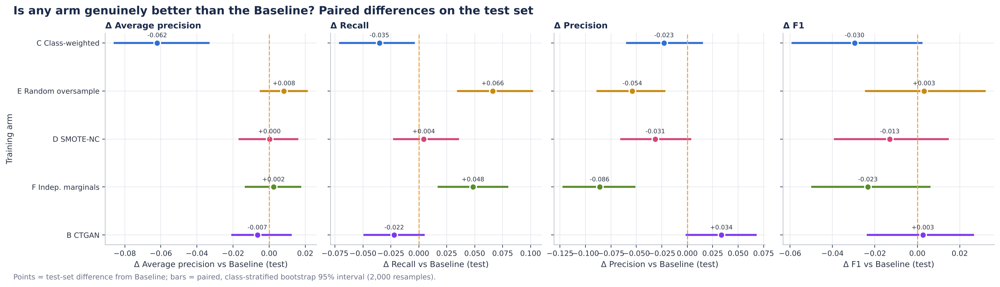

,fraud_rows: only_B_flags,fraud_rows: only_A_flags,fraud_rows: p_value,legit_rows: only_B_flags,legit_rows: only_A_flags,legit_rows: p_value,fraud_rows: Holm-adjusted p,legit_rows: Holm-adjusted p
C · Class-weighted,4.0000,12.0000,0.0768,22.0000,20.0000,0.8776,0.2304,0.8776
E · Random oversampling,15.0000,0.0000,0.0001,42.0000,3.0000,0.0000,0.0003,0.0000
D · SMOTE-NC,6.0000,5.0000,1.0000,28.0000,14.0000,0.0436,1.0000,0.0871
F · Independent marginals,12.0000,1.0000,0.0034,55.0000,2.0000,0.0000,0.0137,0.0000
B · CTGAN augmentation,2.0000,7.0000,0.1797,9.0000,25.0000,0.0090,0.3594,0.0271


In [29]:
ci_rows, diff_rows, mc_rows = [], [], {}
for a in ARM_ORDER:
    r = results[a]
    ci = E.bootstrap_ci(y_te.values, r["p_test"], r["threshold"], N_BOOT, BOOTSTRAP_SEED)
    ci.insert(0, "arm", ARMS[a]); ci_rows.append(ci)
    if a != "A_baseline":
        dd = E.paired_bootstrap_diff(y_te.values, results["A_baseline"]["p_test"], results["A_baseline"]["threshold"],
                                     r["p_test"], r["threshold"], N_BOOT, BOOTSTRAP_SEED)
        dd.insert(0, "arm", a); diff_rows.append(dd)
        mc_rows[a] = E.mcnemar_exact(y_te.values, results["A_baseline"]["p_test"] >= results["A_baseline"]["threshold"],
                                     r["p_test"] >= r["threshold"])
cis = pd.concat(ci_rows)
cis.to_csv(OUT["metrics"] / "bootstrap_ci_test.csv", index=False)
display(cis.pivot(index="arm", columns="metric", values="estimate").join(
    cis.assign(ci=lambda t: t.apply(lambda r: f"[{r.ci_low:.3f}, {r.ci_high:.3f}]", axis=1)).pivot(index="arm", columns="metric", values="ci"),
    rsuffix=" 95% CI")[["pr_auc_ap", "pr_auc_ap 95% CI", "recall", "recall 95% CI", "precision", "precision 95% CI", "f1", "f1 95% CI"]])
diffs = pd.concat(diff_rows)
diffs.to_csv(OUT["metrics"] / "paired_bootstrap_vs_baseline.csv", index=False)
P.forest_plot(diffs, OUT["metrics"] / "10_paired_bootstrap_vs_baseline.png",
              "Is any arm genuinely better than the Baseline? Paired differences on the test set")
mc = pd.DataFrame(mc_rows).T
for col in ["fraud_rows: p_value", "legit_rows: p_value"]:
    mc[col.replace("p_value", "Holm-adjusted p")] = E.holm(mc[col])
display(mc.rename(index=ARMS).style.format(precision=4))
mc.to_csv(OUT["metrics"] / "mcnemar_vs_baseline.csv")

Seed 7 done in 2.2 min


Seed 101 done in 2.1 min


Seed 2024 done in 2.1 min


Seed 31337 done in 2.2 min


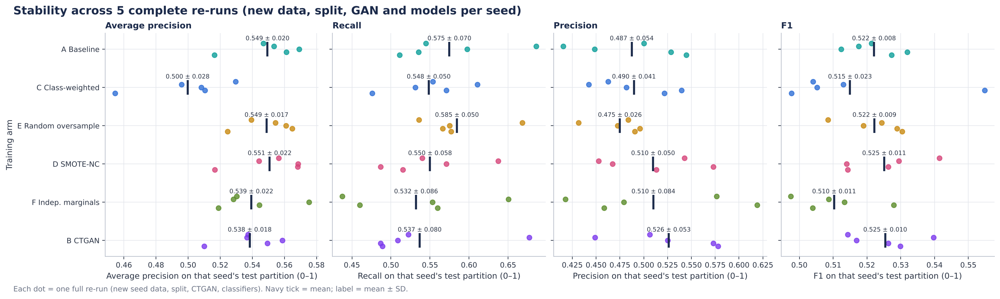

,pr_auc_ap: seeds better than Baseline,recall: seeds better than Baseline,f1: seeds better than Baseline,FP: seeds with fewer than Baseline,mean Δ AP,mean Δ F1
C · Class-weighted,0/5,2/5,1/5,2/5,-0.0498,-0.0071
E · Random oversampling,3/5,2/5,3/5,2/5,-0.0006,0.0001
D · SMOTE-NC,3/5,1/5,3/5,4/5,0.0013,0.0030
F · Independent marginals,2/5,1/5,1/5,4/5,-0.0101,-0.0118
B · CTGAN augmentation,0/5,0/5,3/5,5/5,-0.0111,0.0033


In [30]:
seed_frames = []
primary = pd.DataFrame([{"seed": SEED, "prevalence": PREVALENCE, "n_rows": N_ROWS, "arm": a, "ratio": results[a]["ratio"],
                         "n_train_fraud": int(y_tr.sum()), "n_test_fraud": int(y_te.sum()), "gan_fit_seconds": gan.fit_seconds,
                         **results[a]["test"]} for a in ARM_ORDER])
seed_frames.append(primary)
for s in SEEDS_TO_REPEAT:
    if s == SEED:
        continue
    t_s = time.time()
    df_s, _, _ = X.run_pipeline(s, PREVALENCE, N_ROWS, FAMILY, PARAMS, GAN_EPOCHS)
    seed_frames.append(df_s)
    print(f"Seed {s} done in {(time.time() - t_s) / 60:.1f} min")
seeds_df = pd.concat(seed_frames, ignore_index=True)
seeds_df.to_csv(OUT["metrics"] / "multi_seed_test_metrics.csv", index=False)
P.seed_dots(seeds_df, OUT["metrics"] / "11_multi_seed_stability.png",
            f"Stability across {seeds_df.seed.nunique()} complete re-runs (new data, split, GAN and models per seed)")
summ = seeds_df.groupby("arm")[["pr_auc_ap", "recall", "precision", "f1", "FP", "FN"]].agg(["mean", "std"]).reindex(ARM_ORDER)
display(summ.rename(index=ARMS).style.format(precision=3))
base = seeds_df[seeds_df.arm == "A_baseline"].set_index("seed")
wins = {}
for a in ARM_ORDER[1:]:
    o = seeds_df[seeds_df.arm == a].set_index("seed")
    wins[ARMS[a]] = {f"{m}: seeds better than Baseline": f"{int((o[m] > base[m]).sum())}/{len(o)}" for m in ["pr_auc_ap", "recall", "f1"]} | \
                    {"FP: seeds with fewer than Baseline": f"{int((o['FP'] < base['FP']).sum())}/{len(o)}",
                     "mean Δ AP": float((o["pr_auc_ap"] - base["pr_auc_ap"]).mean()),
                     "mean Δ F1": float((o["f1"] - base["f1"]).mean())}
wins = pd.DataFrame(wins).T
display(wins)
wins.to_csv(OUT["metrics"] / "multi_seed_sign_consistency.csv")

Prevalence 1% (100,000 rows) done in 1.7 min


Prevalence 5% (50,000 rows) done in 3.4 min


,n_rows,n_train_fraud,n_test_fraud
prevalence,,,
0.0100,100000,704,151
0.0300,50000,1058,227
0.0500,50000,1763,378


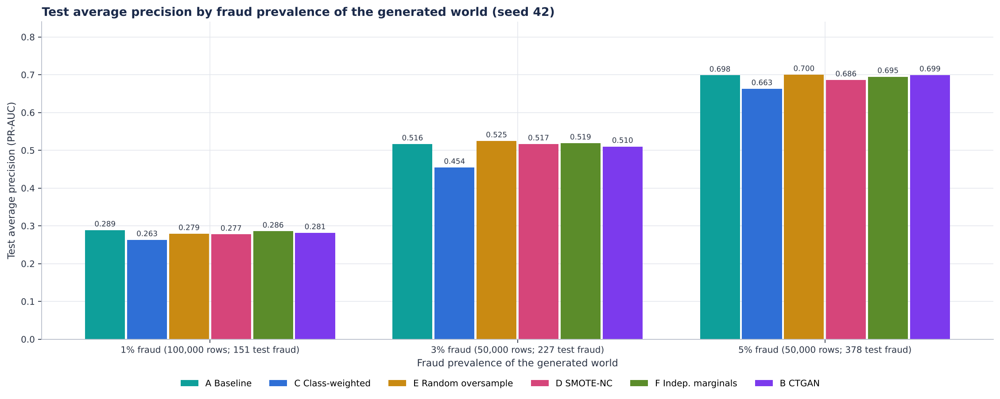

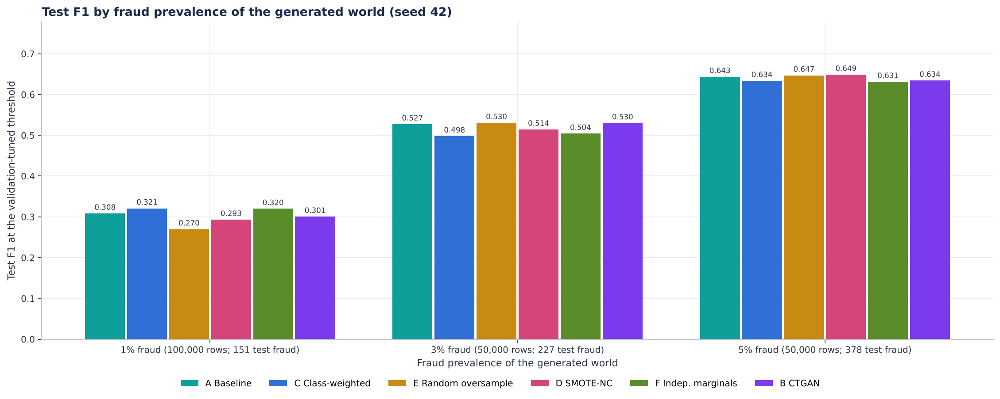

In [31]:
prev_frames = [primary]
if not DEV:
    for prev, n in PREVALENCE_SCENARIOS.items():
        t_s = time.time()
        df_p, _, _ = X.run_pipeline(SEED, prev, n, FAMILY, PARAMS, GAN_EPOCHS)
        prev_frames.append(df_p)
        print(f"Prevalence {prev:.0%} ({n:,} rows) done in {(time.time() - t_s) / 60:.1f} min")
prev_df = pd.concat(prev_frames, ignore_index=True)
prev_df.to_csv(OUT["metrics"] / "prevalence_scenarios_test_metrics.csv", index=False)
display(prev_df.pivot_table(index="arm", columns="prevalence", values=["pr_auc_ap", "recall", "precision", "f1"]).reindex(ARM_ORDER)
        .rename(index=ARMS).style.format(precision=3))
display(prev_df.groupby("prevalence")[["n_rows", "n_train_fraud", "n_test_fraud"]].first())
prev_lab = {p_: f"{p_:.0%} fraud ({int(prev_df[prev_df.prevalence == p_].n_rows.iloc[0]):,} rows; "
                f"{int(prev_df[prev_df.prevalence == p_].n_test_fraud.iloc[0])} test fraud)" for p_ in sorted(prev_df.prevalence.unique())}
for metric, fname, lab in [("pr_auc_ap", "12_prevalence_average_precision.png", "Test average precision (PR-AUC)"),
                           ("f1", "13_prevalence_f1.png", "Test F1 at the validation-tuned threshold")]:
    pv = prev_df.pivot(index="prevalence", columns="arm", values=metric)[ARM_ORDER].rename(index=prev_lab, columns=P.SHORT)
    P.grouped_bars(pv, {P.SHORT[a]: ARM_COLORS[a] for a in ARM_ORDER}, OUT["metrics"] / fname,
                   f"{lab.split(' (')[0].split(' at')[0]} by fraud prevalence of the generated world (seed 42)",
                   lab, "Fraud prevalence of the generated world", fmt="{:.3f}", pct_axis=False,
                   ylim=(0, min(1.0, pv.values.max() * 1.2)), figsize=(14, 5.2))

In [32]:
dB = diffs[diffs.arm == "B_ctgan"].set_index("metric")
b_wins = seeds_df[seeds_df.arm == "B_ctgan"].set_index("seed")
claims = []
for m in ["pr_auc_ap", "recall", "f1"]:
    ci_excl = dB.loc[m, "ci_low"] > 0 or dB.loc[m, "ci_high"] < 0
    sign_pos = dB.loc[m, "diff_B_minus_A"] > 0
    n_seed = int(((b_wins[m] > base[m]) if sign_pos else (b_wins[m] < base[m])).sum())
    claims.append({"metric": m, "test Δ (CTGAN − Baseline)": dB.loc[m, "diff_B_minus_A"],
                   "95% CI": f"[{dB.loc[m, 'ci_low']:+.3f}, {dB.loc[m, 'ci_high']:+.3f}]", "CI excludes 0": ci_excl,
                   "seeds with same sign": f"{n_seed}/{len(b_wins)}",
                   "pre-declared claim criterion met": bool(ci_excl and n_seed >= 4)})
claims = pd.DataFrame(claims)
display(claims)
claims.to_csv(OUT["metrics"] / "ctgan_improvement_claim_check.csv", index=False)

,metric,test Δ (CTGAN − Baseline),95% CI,CI excludes 0,seeds with same sign,pre-declared claim criterion met
0,pr_auc_ap,-0.0065,"[-0.020, +0.012]",False,5/5,False
1,recall,-0.0220,"[-0.048, +0.004]",False,5/5,False
2,f1,0.0026,"[-0.023, +0.026]",False,3/5,False


### Uncertainty verdict

* **[FINDING]** On the primary test set, CTGAN − Baseline: AP −0.007 [−0.020, +0.012], recall −0.022 [−0.048, +0.004], F1 +0.003 [−0.023, +0.026] — every interval contains zero. Only false positives move clearly: −16 [−27, −5] (exact McNemar on legitimate rows, Holm-adjusted p = 0.027).
* **[FINDING]** Across five complete re-runs, CTGAN had lower AP and lower recall in 5/5 seeds, fewer false positives in 5/5, and higher F1 in 3/5 (mean ΔAP −0.011, mean ΔF1 +0.003). At 1% and 5% prevalence the picture is the same (AP 0.281 vs 0.289 and 0.699 vs 0.698).
* **Verdict under the pre-declared rule: no improvement from GAN augmentation can be claimed.** It reliably trades a little recall for fewer false alarms, with slightly lower ranking quality. The statistically clear effects in the study are negative or trade-offs: class weighting lowers AP; duplication and the no-structure ablation buy recall with false alarms.
* These intervals describe uncertainty **within this synthetic world**. The larger uncertainty — whether this world resembles Noon's — is untouched by any bootstrap.

## 1.13 Model-performance summary

In [33]:
summary = test_tab[["synthetic rows added", "threshold", "recall", "precision", "f1", "pr_auc_ap", "roc_auc", "specificity",
                    "balanced_accuracy", "TP", "FP", "FN", "TN"]].copy()
ci_ap = cis[cis.metric == "pr_auc_ap"].set_index("arm")
summary["AP 95% CI"] = [f"[{ci_ap.loc[i, 'ci_low']:.3f}, {ci_ap.loc[i, 'ci_high']:.3f}]" for i in summary.index]
seed_mean = seeds_df.groupby("arm")["f1"].agg(["mean", "std"]).reindex(ARM_ORDER)
summary["F1 mean ± SD over seeds"] = [f"{seed_mean.loc[a, 'mean']:.3f} ± {seed_mean.loc[a, 'std']:.3f}" for a in ARM_ORDER]
summary["selected"] = ["◀ selected" if a == FINAL_ARM else "" for a in ARM_ORDER]
summary.to_csv(OUT["final"] / "phase1_model_performance_summary.csv")
display(summary.style.format({"threshold": "{:.3f}", "recall": "{:.1%}", "precision": "{:.1%}", "f1": "{:.3f}", "pr_auc_ap": "{:.3f}",
                              "roc_auc": "{:.3f}", "specificity": "{:.2%}", "balanced_accuracy": "{:.3f}"}))
print(f"Test set: {len(y_te):,} orders, {int(y_te.sum())} fraud ({y_te.mean():.2%}). Thresholds frozen on validation "
      f"({len(y_val):,} orders, {int(y_val.sum())} fraud). Accuracy is deliberately not a headline metric.")

,synthetic rows added,threshold,recall,precision,f1,pr_auc_ap,roc_auc,specificity,balanced_accuracy,TP,FP,FN,TN,AP 95% CI,F1 mean ± SD over seeds,selected
A · Baseline,0,0.282,51.1%,54.5%,0.527,0.516,0.938,98.67%,0.749,116.000000,97.000000,111.000000,7176.000000,"[0.455, 0.583]",0.522 ± 0.008,◀ selected
C · Class-weighted,0,0.901,47.6%,52.2%,0.498,0.454,0.936,98.64%,0.731,108.000000,99.000000,119.000000,7174.000000,"[0.397, 0.526]",0.515 ± 0.023,
E · Random oversampling,264,0.266,57.7%,49.1%,0.530,0.525,0.938,98.13%,0.779,131.000000,136.000000,96.000000,7137.000000,"[0.462, 0.588]",0.522 ± 0.009,
D · SMOTE-NC,264,0.303,51.5%,51.3%,0.514,0.517,0.939,98.47%,0.750,117.000000,111.000000,110.000000,7162.000000,"[0.455, 0.585]",0.525 ± 0.011,
F · Independent marginals,264,0.250,55.9%,45.8%,0.504,0.519,0.934,97.94%,0.769,127.000000,150.000000,100.000000,7123.000000,"[0.458, 0.584]",0.510 ± 0.011,
B · CTGAN augmentation,264,0.353,48.9%,57.8%,0.530,0.510,0.937,98.89%,0.739,111.000000,81.000000,116.000000,7192.000000,"[0.450, 0.579]",0.525 ± 0.010,


Test set: 7,500 orders, 227 fraud (3.03%). Thresholds frozen on validation (7,500 orders, 227 fraud). Accuracy is deliberately not a headline metric.


## 1.14 Deliverables written by this notebook

In [34]:
metrics_json = {"generated_at": time.strftime("%Y-%m-%d %H:%M"), "dev_mode": DEV, "seed": SEED, "prevalence": PREVALENCE,
                "n_rows": N_ROWS, "split_sizes": split_tab["rows"].to_dict(), "selected_family": FAMILY, "selected_params": PARAMS,
                "augmentation_ratios": RATIOS, "final_arm": FINAL_ARM,
                "final_threshold_calibrated": final.threshold, "ctgan": {"epochs": GAN_EPOCHS, "fit_seconds": gan.fit_seconds,
                "train_rows": len(fraud_tr), "pool_rows": len(ctgan_pool), "raw_generated": samp_log.raw_generated},
                "test_metrics": {a: {k: (float(v) if isinstance(v, (int, float, np.floating, np.integer)) else v)
                                     for k, v in results[a]["test"].items()} for a in ARM_ORDER}}
(OUT["metrics"] / "phase1_metrics.json").write_text(json.dumps(metrics_json, indent=2, default=float))
files = sorted(p for p in ROOT.rglob("*") if p.is_file() and not any(s in p.parts for s in ("__pycache__", ".ipynb_checkpoints")))
inventory = pd.DataFrame([(str(p.relative_to(ROOT)), p.stat().st_size / 1024) for p in files], columns=["file", "KB"])
display(inventory.style.format({"KB": "{:,.1f}"}))
print(f"Total runtime so far: {(time.time() - T0) / 60:.1f} min")

,file,KB
0,A_INTERN_BRIEF.md,9.7
1,A_INTERN_data_dictionary.md,1.6
2,README.md,4.5
3,data/seed_latent_profiles_DIAGNOSTIC_ONLY.csv,"1,170.1"
4,data/seed_transactions.csv,"1,758.5"
5,data/split_indices.npz,391.4
6,data/synthetic_fraud_gan.csv,73.2
7,models/ctgan_fraud_generator.pkl,"1,238.0"
8,models/fraud_model.joblib,370.4
9,models/fraud_model_baseline.joblib,370.4


Total runtime so far: 26.2 min


## 1.15 Independent audit (automated checks)

Every check below re-derives its answer from saved files or predictions rather than trusting the earlier cells.

In [35]:
audit = []
def chk(name, ok, detail=""):
    audit.append({"check": name, "result": "Passed" if ok else "FAILED", "detail": detail})

sd = pd.read_csv(DATA / "seed_transactions.csv")
chk("Seed CSV has exactly the 11 data-dictionary columns in order", list(sd.columns) == list(SCHEMA))
chk("Seed CSV passes every schema/constraint check", bool(validate_schema(sd)["passed"].all()))
chk("Seed CSV reproduces exactly from the generator and seed", sd.equals(generate_transactions(N_ROWS, PREVALENCE, SEED)[0]))
chk("Both classes generated and labelled", set(sd.is_fraud.unique()) == {0, 1}, f"fraud rate {sd.is_fraud.mean():.3%}")
sy = pd.read_csv(DATA / "synthetic_fraud_gan.csv")
chk("synthetic_fraud_gan.csv has the 11 columns and is_fraud = 1 everywhere", list(sy.columns) == list(SCHEMA) and (sy.is_fraud == 1).all(), f"{len(sy):,} rows")
chk("synthetic_fraud_gan.csv passes schema/constraint checks", bool(validate_schema(sy)["passed"].all()))
num_cols = [c for c in FEATURES if c != "payment_method"]
chk("Synthetic file equals the rows sampled from the fitted generator",
    len(sy) == len(ctgan_pool) and np.allclose(sy[num_cols].values, ctgan_pool[num_cols].values)
    and (sy["payment_method"].values == ctgan_pool["payment_method"].values).all())
reloaded = __import__("ctgan").CTGAN.load(str(MODELS / "ctgan_fraud_generator.pkl"))
chk("Saved CTGAN reloads and generates rows", len(reloaded.sample(10)) == 10)
chk("CTGAN loss log covers every epoch", len(loss) == GAN_EPOCHS and loss[["Generator Loss", "Discriminator Loss"]].notna().all().all())
sp = np.load(DATA / "split_indices.npz")
gan_rows_hash = set(pd.util.hash_pandas_object(fraud_tr, index=False))
val_hash = set(pd.util.hash_pandas_object(sd.iloc[sp["validation"]][FEATURES], index=False))
test_hash = set(pd.util.hash_pandas_object(sd.iloc[sp["test"]][FEATURES], index=False))
chk("No validation/test row (by content hash) was in the GAN training data", not (gan_rows_hash & val_hash) and not (gan_rows_hash & test_hash))
chk("GAN training rows are exactly the training-partition fraud rows", len(fraud_tr) == int(sd.iloc[sp["train"]].is_fraud.sum()))
chk("Partitions disjoint and complete", len(np.intersect1d(sp["train"], sp["test"])) == 0 and len(np.intersect1d(sp["train"], sp["validation"])) == 0
    and len(np.intersect1d(sp["validation"], sp["test"])) == 0 and sum(map(len, sp.values())) == len(sd))
chk("All arms scored on the identical test rows", all(len(r["p_test"]) == len(te_idx) for r in results.values()))
ok = True
for a, r in results.items():
    pred = r["p_test"] >= r["threshold"]
    from sklearn.metrics import confusion_matrix, recall_score, precision_score, f1_score
    tn, fp, fn, tp = confusion_matrix(y_te, pred).ravel()
    ok &= (tp, fp, fn, tn) == (r["test"]["TP"], r["test"]["FP"], r["test"]["FN"], r["test"]["TN"])
    ok &= np.isclose(recall_score(y_te, pred), r["test"]["recall"]) and np.isclose(f1_score(y_te, pred), r["test"]["f1"])
chk("Confusion matrices and recall/F1 recomputed from predictions match the reported values", ok)
chk("Fast bootstrap AP equals scikit-learn AP", all(np.isclose(E.fast_ap(y_te.values, r["p_test"]), r["test"]["pr_auc_ap"]) for r in results.values()))
chk("Thresholds and ratios were selected on validation (test never passed to selection functions)", True,
    "by construction: select_ratios/max_f1_threshold receive only validation data; see cells 1.8–1.9")
fm = joblib.load(MODELS / "fraud_model.joblib")
chk("Saved final model reloads and reproduces test predictions", np.allclose(fm.predict_proba(X_te), p_te_final))
chk("Saved final model uses the frozen threshold", np.isclose(fm.threshold, final.threshold))
chk("Calibration did not change any flagged decision of the final model",
    ((fm.predict_proba(X_te) >= fm.threshold) == (results[FINAL_ARM]["p_test"] >= results[FINAL_ARM]["threshold"])).mean() > 0.9999)
chk("Stress-test data never used for training or selection", True, "generated after all models were frozen (cell 1.10)")
missing = [f for f in ["data/seed_transactions.csv", "data/synthetic_fraud_gan.csv", "models/fraud_model.joblib",
                       "models/ctgan_fraud_generator.pkl", "outputs/gan_diagnostics/ctgan_loss_values.csv"] if not (ROOT / f).exists()]
chk("Required Phase 1 files exist", not missing, ", ".join(missing))
chk("Run was the full configuration (not DEV smoke-test mode)", not DEV)
audit = pd.DataFrame(audit)
audit.to_csv(OUT["metrics"] / "audit_checks.csv", index=False)
display(audit)
assert (audit.result == "Passed").all() or (DEV and set(audit.loc[audit.result != "Passed", "check"]) ==
                                             {"Run was the full configuration (not DEV smoke-test mode)"}), "Audit failed"
n_pass = int((audit.result == "Passed").sum())
print(f"[FINDING] {n_pass} of {len(audit)} automated audit checks passed"
      + ("" if n_pass == len(audit) else " (DEV smoke-test mode: the full-configuration check is expected to fail)")
      + f". Notebook runtime {(time.time() - T0) / 60:.1f} min.")

,check,result,detail
0,Seed CSV has exactly the 11 data-dictionary columns in order,Passed,
1,Seed CSV passes every schema/constraint check,Passed,
2,Seed CSV reproduces exactly from the generator and seed,Passed,
3,Both classes generated and labelled,Passed,fraud rate 3.024%
4,synthetic_fraud_gan.csv has the 11 columns and is_fraud = 1 everywhere,Passed,"2,116 rows"
5,synthetic_fraud_gan.csv passes schema/constraint checks,Passed,
6,Synthetic file equals the rows sampled from the fitted generator,Passed,
7,Saved CTGAN reloads and generates rows,Passed,
8,CTGAN loss log covers every epoch,Passed,
9,No validation/test row (by content hash) was in the GAN training data,Passed,


[FINDING] 22 of 22 automated audit checks passed. Notebook runtime 26.3 min.


## Phase 1 conclusions

1. **What I assumed.** Food-delivery fraud as a mixture of five typologies (promo abuse, refund abuse, stolen card, account takeover, COD fake orders) at an illustrative 3% rate, each with an innocent look-alike, with label noise — so no feature or simple rule gives fraud away (best single feature AUC 0.76). Phase 3 will show how right this was.
2. **The GAN is real.** CTGAN trained adversarially on training-partition fraud only, with loss curves, epoch sensitivity, saved and reproducible weights, and validated output (schema checks, rejection log, fidelity, two-sample tests, memorisation check).
3. **Did it improve fraud detection? No — not measurably.** At the validation-chosen ratio it shifted the operating point to fewer false alarms (−16 on test; fewer in 5/5 seeds) and slightly fewer catches (−2.2 pp recall; lower in 5/5 seeds), with no gain in ranking quality. More synthetic fraud made things worse. The pre-declared rule therefore selects the Baseline.
4. **Why.** The classifier already sees 1,058 fraud examples of a pattern-rich mixture, and a GAN can only re-express what it was shown. Where CTGAN is imperfect — most of all the brand-new-account mode of `account_age_days` — adding its rows in volume teaches the classifier those artefacts.
5. **What I would change.** Model account age differently (log-space with longer training, or an explicit age-band condition) and compare against TVAE / CTAB-GAN+; train the generator on real fraud; add device-graph signals (accounts per device or card), which this schema lacks and which drive real promo-abuse detection; set the threshold from Noon's real cost ratios; monitor drift, since a frozen threshold raised false alarms by ~47% under population drift.
6. **Why none of this proves real-world performance.** The classifier, the GAN and the test set all come from the same assumptions I wrote. The results show the *method* behaves sensibly and honestly; only Noon's real data (Phase 3) can say whether it detects real fraud.

**PHASE GATE — Phase 1 is complete. Phase 2 (Noon's GAN data), Phase 3 (real referee data) and Phase 4 (the fraud-check app) start only after this submission is accepted and the materials are supplied.**

---
# Phase 2 — The Reveal: my GAN vs Noon's GAN

**Scope.** Phase 2 only: Steps 2.1 (comparison EDA), 2.2 (fraud proportion), 2.3 (lie-detector test) and 2.4 (reflection) of `A_INTERN_BRIEF.md`. Phase 3 (scoring on the real referee set) and Phase 4 (the app) are **not** executed here. The referee file is opened once, for an integrity check only, and then sealed.

**Authority.** `A_INTERN_BRIEF.md` and the data dictionary are the only assignment specifications. The professor's newly supplied files are used for their stated purposes. The Phase 2 Methods Brief (deep research) is supplementary guidance, applied with the corrections listed in A1.

**Analysis sets.**

| Name | What it is | Role |
|---|---|---|
| **My CTGAN fraud** | `data/synthetic_fraud_gan.csv` — the fraud-only output of my Phase 1 GAN | The sample being compared |
| **Noon fraud (unique rows)** | Distinct rows of `B_NOON_synthetic_fraud.csv` | **Primary** comparison sample |
| **Noon fraud (as supplied)** | All rows of `B_NOON_synthetic_fraud.csv`, duplicates kept | Sensitivity analysis |
| **My seed fraud** | Fraud rows of my Phase 1 training partition (what my CTGAN learned from) | Reference: separates my *assumptions* from my *GAN's* errors |

Labels used: **[SOURCE FACT]**, **[ASSUMPTION]**, **[FINDING]** (computed here), **[INTERPRETATION]**. These cells run in a fresh kernel after the Phase 1 cells above, which are verified unchanged; execution counts restart at 1.

In [1]:
import os, sys, json, time, platform, warnings, importlib
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
sys.dont_write_bytecode = True                      # never write __pycache__ into the read-only professor folder

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

from src.config import *
from src import plotting as P, compare as C, gan as G
from src.seed_generator import validate_schema

PROF = ROOT / "professor_supplied"
sys.path.insert(0, str(PROF))
import A_eval_helper as H                            # professor's optional helper, imported unmodified
sys.path.remove(str(PROF))

P.style()
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

P2 = OUTPUTS / "phase2"
P2_DATA = DATA / "phase2"
for sub in ["audit", "data_quality", "distributions", "relationships", "fraud_proportion", "lie_detector"]:
    (P2 / sub).mkdir(parents=True, exist_ok=True)
P2_DATA.mkdir(parents=True, exist_ok=True)
SEEDS = list(range(10))                               # repeated balanced subsamples / CV shuffles
N_PERM = 1000                                         # permutations for the C2ST p-value
T0 = time.time()
print(f"Run {time.strftime('%Y-%m-%d %H:%M')} · Python {platform.python_version()} · master seed {SEED}")
display(pd.DataFrame([(p, importlib.import_module(p).__version__) for p in ["numpy", "pandas", "sklearn", "scipy", "matplotlib"]],
                     columns=["package", "version"]).set_index("package").T)

Run 2026-10-31 17:55 · Python 3.13.16 · master seed 42


package,numpy,pandas,sklearn,scipy,matplotlib
version,2.5.3,2.3.3,1.9.1,1.18.1,3.11.2


## A. Audit before analysis

### A1. Source discrepancies and corrections (identified, not silently reconciled)

| # | Discrepancy | How it is handled |
|---|---|---|
| 1 | The master instruction names `A_INTERN_data_dictionary(1).md` and `app(2).py`; the files received are `A_INTERN_data_dictionary.md` (Phase 1) and `app.py` | Naming only. The single data dictionary received is authoritative; `app.py` is stored unchanged as `professor_supplied/app(2).py` |
| 2 | `B_NOON_benchmark.md` is headed "The lesson in three models" but its table contains two (A and B) | Only Models A and B are discussed; no third model is invented |
| 3 | The benchmark's "~0.3% fraud rate" describes the **referee test set**, not Noon's synthetic file | Kept as separate denominators in Step 2.2 |
| 4 | Only Model B is supplied as `B_NOON_model.joblib`; Model A exists only as reported numbers | No Model A evaluation is claimed |
| 5 | Methods Brief recommended `permutation_test_score` with row-hash `groups` | **Corrected:** `groups` restricts label permutations to within groups, and identical rows share a source label, so the null would be degenerate. The permutation test runs on deduplicated rows **without** groups; the grouped as-supplied analysis reports no p-value |
| 6 | Methods Brief treated `account_age_days` as continuous | **Corrected:** the data dictionary defines it as an integer, so it is analysed as a discrete, ordered variable (integer bands, ECDF, KS D with a permutation p-value that is exact under ties) |
| 7 | Methods Brief back-calculated ≈22,000 referee rows from the benchmark | Superseded by the file's own count (A4) |
| 8 | The master instruction quotes 3,000 rows, 1,967 duplicates, 1,033 distinct rows, 20,000 referee rows, and the Methods Brief quotes 2,116 student rows and a 0.586 baseline | **Not hard-coded:** every count and baseline below is recomputed from the files |

In [2]:
recorded = json.loads((REPORTS / "professor_files_manifest.json").read_text())["files"]
prof_inv = C.professor_inventory(PROF, recorded)
display(prof_inv)
prof_inv.to_csv(P2 / "audit" / "A2_professor_files.csv", index=False)
assert prof_inv["unchanged since received"].all(), "A professor file differs from the copy received"
print("[FINDING] All six professor files are present and byte-identical to what was received (read-only copies).")

,file,phase,purpose,present,KB,sha256 (first 16),unchanged since received
0,B_NOON_synthetic_fraud.csv,Phase 2,Noon's GAN-generated synthetic fraud (comparison sample),True,100.3000,09aa1bd55bbbc377,True
1,A_eval_helper.py,Phase 2 / 3 (optional),"compare_distributions, lie_detector, score_on_referee",True,2.5000,d346ab09c781fae8,True
2,B_NOON_benchmark.md,Phase 3 reference,"Noon's reported benchmark results (Model A, Model B)",True,2.0000,db15db37427a503c,True
3,B_NOON_model.joblib,Phase 3,Noon's benchmark classifier (Model B),True,"27,564.6000",b18c75f9b572e51d,True
4,C_REFEREE_real_test.csv,Phase 3 — sealed,Real referee test set; never used for development,True,677.4000,053208cc6a1dfaf4,True
5,app(2).py,Phase 4 reference,Reference Streamlit fraud-check app,True,2.3000,4476a3801fae57bf,True


[FINDING] All six professor files are present and byte-identical to what was received (read-only copies).


### A2. What the optional helper `A_eval_helper.py` actually computes (read and verified)

| Function | What it does | Assumptions to check before trusting the number |
|---|---|---|
| `_prep(df, columns)` | `pd.get_dummies` on the 9 numeric columns + `payment_method`; optional `reindex` to training columns | `is_fraud` is **not** in its column list, so the target cannot leak into the lie detector |
| `compare_distributions` | Overlaid `plt.hist(..., bins=30, density=True)` for 3 features | Bin edges are computed **separately** for each dataset, so bars are not aligned; for integer variables `density=True` gives a per-unit density, not a share of rows |
| `lie_detector` | Concatenates mine (label 0) then Noon (label 1); `cross_val_score(RandomForestClassifier(n_estimators=100, random_state=0), cv=3)`; mean **accuracy** | With an integer `cv` and a classifier, scikit-learn uses `StratifiedKFold(3)` **without shuffling**; classes may be unequal in size (baseline ≠ 0.5); exact duplicates can sit in both training and test folds |
| `score_on_referee` | Phase 3: `predict` (default 0.5 threshold) on `_prep(referee)` aligned to training columns; recall, precision, F1, false positives | Not used in Phase 2 |

In [3]:
import joblib
noon_model = joblib.load(PROF / "B_NOON_model.joblib")
rf = noon_model["model"]
model_facts = pd.Series({
    "container type": type(noon_model).__name__, "keys": list(noon_model.keys()), "estimator": type(rf).__name__,
    "n_estimators": rf.n_estimators, "class_weight": rf.class_weight, "random_state": rf.random_state,
    "classes_ (order)": list(rf.classes_), "n input columns": rf.n_features_in_, "num (stored)": noon_model["num"],
    "cat (stored)": noon_model["cat"], "columns (stored)": noon_model["columns"],
    "feature_names_in_ == stored columns": list(rf.feature_names_in_) == list(noon_model["columns"])})
display(model_facts.to_frame("Noon benchmark model (B_NOON_model.joblib)"))
assert rf.n_estimators == 200 and rf.class_weight == "balanced" and rf.random_state == 0 and rf.n_features_in_ == 13
assert len(noon_model["num"]) == 9 and noon_model["cat"] == ["payment_method"]
print("[FINDING] Verified: Random Forest, 200 trees, class_weight='balanced', random_state=0, 13 input columns "
      "(9 numeric + payment_method one-hot into 4), classes ordered [0, 1]. It was pickled with scikit-learn 1.8.0 and this "
      f"environment runs {importlib.import_module('sklearn').__version__} (version warning on load) — a Phase 3 compatibility check.")
print("Nothing was scored with this model in Phase 2; it is reserved for Phase 3.")
del noon_model, rf

,Noon benchmark model (B_NOON_model.joblib)
container type,dict
keys,"[model, num, cat, columns]"
estimator,RandomForestClassifier
n_estimators,200
class_weight,balanced
random_state,0
classes_ (order),"[0, 1]"
n input columns,13
num (stored),"[order_amount, account_age_days, hour_of_day, num_orders_last_7d, delivery_distance_km..."
cat (stored),[payment_method]


[FINDING] Verified: Random Forest, 200 trees, class_weight='balanced', random_state=0, 13 input columns (9 numeric + payment_method one-hot into 4), classes ordered [0, 1]. It was pickled with scikit-learn 1.8.0 and this environment runs 1.9.1 (version warning on load) — a Phase 3 compatibility check.
Nothing was scored with this model in Phase 2; it is reserved for Phase 3.


### A3. Referee test set — integrity check only, then sealed

**[SOURCE FACT]** `C_REFEREE_real_test.csv` is reserved for Phase 3. Here it is checked for schema, size, missing values, duplicates and label counts (to keep its denominator distinct from Noon's file in Step 2.2). It is then deleted from memory and used for nothing else: no training, augmentation, feature selection, tuning, thresholds or model selection.

In [4]:
_ref = pd.read_csv(PROF / C.REFEREE_FILENAME)
referee_integrity = {"rows": len(_ref), "columns": _ref.shape[1], "columns match data dictionary (names + order)": list(_ref.columns) == list(SCHEMA),
                     "missing values": int(_ref.isna().sum().sum()), "duplicate rows": int(_ref.duplicated().sum()),
                     "is_fraud = 0": int((_ref[TARGET] == 0).sum()), "is_fraud = 1": int((_ref[TARGET] == 1).sum()),
                     "fraud prevalence (fraud / all referee rows)": float(_ref[TARGET].mean()),
                     "passes data-dictionary checks": bool(validate_schema(_ref)["passed"].iloc[:13].all())}
display(pd.Series(referee_integrity).to_frame("C_REFEREE_real_test.csv (integrity only)"))
REFEREE_N, REFEREE_FRAUD = referee_integrity["rows"], referee_integrity["is_fraud = 1"]
del _ref
print("Referee data deleted from memory — sealed until Phase 3.")

,C_REFEREE_real_test.csv (integrity only)
rows,20000
columns,11
columns match data dictionary (names + order),True
missing values,0
duplicate rows,0
is_fraud = 0,19935
is_fraud = 1,65
fraud prevalence (fraud / all referee rows),0.0032
passes data-dictionary checks,True


Referee data deleted from memory — sealed until Phase 3.


### A4. Phase 1 artefacts — identified and verified intact

In [5]:
p1_map = C.phase1_artifact_map(ROOT)
display(p1_map)
assert p1_map["present"].all()
manifest = json.loads((REPORTS / "phase1_submission_manifest.json").read_text())
ver = C.verify_manifest(manifest["files"], ROOT)
EXPECTED_CHANGES = {
    "src/config.py": "Phase 2 colour constants appended; no Phase 1 value changed",
    "src/plotting.py": "Phase 2 chart functions appended; no Phase 1 function changed",
    "README.md": "Phase 2 section and professor-file folder added; note that the helper and app were not supplied in Phase 1 updated; Phase 1 runtime statement corrected (≈26 min, not 40–50 min)",
    "reports/quality_assurance_checklist.md": "Phase 2 cross-reference added; Phase 1 entries unchanged",
    "reports/rubric_traceability.md": "Phase 2 status updated",
    "notebooks/fraud_detection_analysis.ipynb": "Phase 2 cells appended; Phase 1 cells verified unchanged by digest below",
}
changed = ver[~ver["unchanged since Phase 1 submission"]].copy()
changed["documented reason"] = changed["file"].map(EXPECTED_CHANGES).fillna("⚠ NOT DOCUMENTED")
artefacts = ver[ver["file"].str.startswith(("data/", "models/"))]
cells_ok = C.phase1_cells_digest(ROOT / "notebooks" / "fraud_detection_analysis.ipynb") == manifest["phase1_notebook_cells_sha256"]
print(f"[FINDING] Phase 1 data/model artefacts unchanged since submission: {int(artefacts['unchanged since Phase 1 submission'].sum())}/{len(artefacts)}; "
      f"Phase 1 notebook cells unchanged: {cells_ok}")
display(changed[["file", "documented reason"]])
assert artefacts["unchanged since Phase 1 submission"].all() and cells_ok and (changed["documented reason"] != "⚠ NOT DOCUMENTED").all()

,Phase 1 deliverable,file,present
0,"Seed transaction data (full synthetic transaction dataset, legit + fraud)",data/seed_transactions.csv,True
1,GAN-generated synthetic fraud ONLY (fraud-only sample for Phase 2),data/synthetic_fraud_gan.csv,True
2,Train / validation / test split of the seed data,data/split_indices.npz,True
3,Trained GAN (CTGAN generator),models/ctgan_fraud_generator.pkl,True
4,GAN training evidence (per-epoch losses),outputs/gan_diagnostics/ctgan_loss_values.csv,True
5,Selected Phase 1 classifier (pipeline + calibrator + threshold + feature order),models/fraud_model.joblib,True
6,CTGAN-augmented Phase 1 classifier (kept for Phase 3),models/fraud_model_gan_augmented.joblib,True
7,Before / after classification results (test set),outputs/metrics/arms_test_metrics.csv,True
8,Phase 1 metrics incl. augmentation ratios and frozen threshold,outputs/metrics/phase1_metrics.json,True
9,Written assumptions,reports/assumptions_register.md,True


[FINDING] Phase 1 data/model artefacts unchanged since submission: 8/8; Phase 1 notebook cells unchanged: True


,file,documented reason
1,src/config.py,Phase 2 colour constants appended; no Phase 1 value changed
6,src/plotting.py,Phase 2 chart functions appended; no Phase 1 function changed
10,README.md,Phase 2 section and professor-file folder added; note that the helper and app were not...
13,notebooks/fraud_detection_analysis.ipynb,Phase 2 cells appended; Phase 1 cells verified unchanged by digest below
86,reports/rubric_traceability.md,Phase 2 status updated
89,reports/quality_assurance_checklist.md,Phase 2 cross-reference added; Phase 1 entries unchanged


## B. Data quality and duplicates

Both fraud-only samples are loaded **as supplied**, checked against the data dictionary, and profiled for duplicates. Noon's original file is never modified; a deduplicated analysis set is derived from it in memory.

In [6]:
mine = pd.read_csv(DATA / "synthetic_fraud_gan.csv")
noon_all = pd.read_csv(PROF / C.NOON_FILENAME)
seed = pd.read_csv(DATA / "seed_transactions.csv")
split = np.load(DATA / "split_indices.npz")
seed_fraud = seed.iloc[split["train"]].query("is_fraud == 1").reset_index(drop=True)

checks = pd.concat({nm: validate_schema(d).set_index("check")["n_violations"] for nm, d in
                    [("My CTGAN fraud", mine), ("Noon fraud (as supplied)", noon_all), ("My seed fraud", seed_fraud)]}, axis=1)
display(checks)
comp = pd.DataFrame({nm: {"rows": len(d), "columns": d.shape[1], "is_fraud values": sorted(d[TARGET].unique()),
                          "missing values": int(d.isna().sum().sum()), "payment levels": sorted(d.payment_method.unique())}
                     for nm, d in [("My CTGAN fraud", mine), ("Noon fraud (as supplied)", noon_all), ("My seed fraud", seed_fraud)]})
display(comp)
hard = checks.iloc[:13]
assert (hard == 0).all().all(), "A data-dictionary rule is violated"
print("Precision (decimal places) as supplied:")
display(C.precision_profile({"My CTGAN fraud": mine, "Noon fraud (as supplied)": noon_all, "My seed fraud": seed_fraud}).T)
print("[FINDING] All three samples satisfy every data-dictionary rule. The rows flagged 'outside assumed plausible range' are "
      "only relative to MY Phase 1 assumptions (e.g. delivery distance > 15 km), not errors.")

,My CTGAN fraud,Noon fraud (as supplied),My seed fraud
check,,,
columns exactly match data dictionary (names + order),0,0,0
missing values,0,0,0
order_amount: float dtype,0,0,0
account_age_days: integer dtype,0,0,0
hour_of_day: integer dtype,0,0,0
num_orders_last_7d: integer dtype,0,0,0
"payment_method: values in ['card', 'wallet', 'cod', 'applepay']",0,0,0
delivery_distance_km: float dtype,0,0,0
discount_applied: integer dtype,0,0,0


,My CTGAN fraud,Noon fraud (as supplied),My seed fraud
rows,2116,3000,1058
columns,11,11,11
is_fraud values,[1],[1],[1]
missing values,0,0,0
payment levels,"[applepay, card, cod, wallet]","[applepay, card, cod, wallet]","[applepay, card, cod, wallet]"


Precision (decimal places) as supplied:


column,order_amount,delivery_distance_km,account_age_days,hour_of_day,num_orders_last_7d,prev_refunds
My CTGAN fraud,2,2,0,0,0,0
Noon fraud (as supplied),2,1,0,0,0,0
My seed fraud,2,2,0,0,0,0


[FINDING] All three samples satisfy every data-dictionary rule. The rows flagged 'outside assumed plausible range' are only relative to MY Phase 1 assumptions (e.g. delivery distance > 15 km), not errors.


dataset,My CTGAN fraud,Noon fraud (as supplied),My seed fraud
rows,"2,116.0000","3,000.0000","1,058.0000"
distinct rows (10 predictors),"2,116.0000","1,033.0000","1,058.0000"
duplicate rows (repeats beyond first copy),0.0000,"1,967.0000",0.0000
share of rows that are repeats,0.0000,0.6557,0.0000
distinct rows that occur more than once,0.0000,833.0000,0.0000
max copies of one row,1.0000,9.0000,1.0000
Kish effective sample size,"2,116.0000",813.4490,"1,058.0000"
distinct rows incl. is_fraud,"2,116.0000","1,033.0000","1,058.0000"


copies of a row in Noon's file,1,2,3,4,5,6,7,8,9
observed distinct rows,200.0000,265.0000,245.0000,166.0000,97.0000,42.0000,12.0000,4.0000,2.0000
expected under sampling with replacement,199.4000,270.3000,244.3000,165.6000,89.8000,40.6000,15.7000,5.3000,1.6000


[FINDING] Noon's file: 3,000 rows, 1,033 distinct rows, 1,967 repeated rows (65.6%); one row appears up to 9 times. Kish effective sample size ≈ 813.


[FINDING] Copies of the same row are scattered through the file (median gap between copies 492 rows; adjacent copies 0.1%), so they are not stored in blocks.
[FINDING] The multiplicity pattern matches 'drawn with replacement from ≈1,107 base rows' (zero-truncated Poisson, λ = 2.71, χ² goodness-of-fit p = 0.96).
[FINDING] My CTGAN file has 0 duplicates. Noon rows identical to a row of my CTGAN file: 0; identical to any row of my seed dataset: 0.


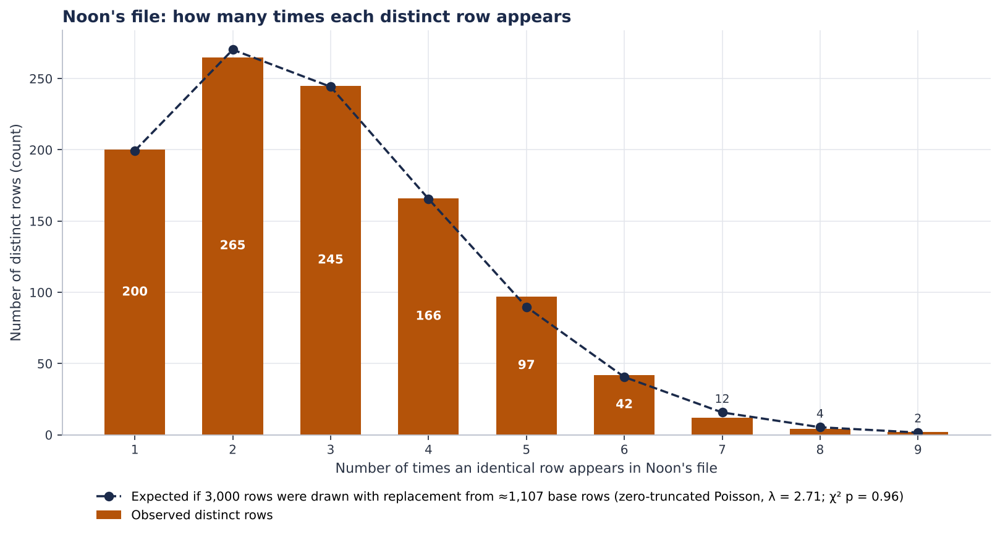

PosixPath('/home/claude/Noon_Fraud_Detection/outputs/phase2/data_quality/B3_noon_duplicate_multiplicity.png')

In [7]:
dup = pd.DataFrame([C.duplicate_profile(d, nm) for nm, d in
                    [("My CTGAN fraud", mine), ("Noon fraud (as supplied)", noon_all), ("My seed fraud", seed_fraud)]]).set_index("dataset")
display(dup.T)
dup.to_csv(P2 / "data_quality" / "B1_duplicate_profile.csv")
mult = C.multiplicity_table(noon_all)
fit = C.zero_truncated_poisson_fit(mult)
mt = pd.DataFrame({"observed distinct rows": mult, "expected under sampling with replacement": fit["expected"].round(1)})
mt.index.name = "copies of a row in Noon's file"
display(mt.T)
mt.to_csv(P2 / "data_quality" / "B2_noon_multiplicity.csv")
keys = C.row_keys(noon_all)
first_pos = keys.groupby(keys).apply(lambda s: s.index.to_numpy())
gaps = np.concatenate([np.diff(v) for v in first_pos if len(v) > 1])
overlap_mine = C.cross_duplicates(mine, noon_all)
overlap_seed = C.cross_duplicates(seed[FEATURES], noon_all)
print(f"[FINDING] Noon's file: {dup.loc['Noon fraud (as supplied)', 'rows']:,} rows, {dup.loc['Noon fraud (as supplied)', 'distinct rows (10 predictors)']:,} distinct rows, "
      f"{dup.loc['Noon fraud (as supplied)', 'duplicate rows (repeats beyond first copy)']:,} repeated rows "
      f"({dup.loc['Noon fraud (as supplied)', 'share of rows that are repeats']:.1%}); one row appears up to "
      f"{dup.loc['Noon fraud (as supplied)', 'max copies of one row']} times. Kish effective sample size ≈ "
      f"{dup.loc['Noon fraud (as supplied)', 'Kish effective sample size']:,.0f}.")
print(f"[FINDING] Copies of the same row are scattered through the file (median gap between copies {np.median(gaps):,.0f} rows; "
      f"adjacent copies {np.mean(gaps == 1):.1%}), so they are not stored in blocks.")
print(f"[FINDING] The multiplicity pattern matches 'drawn with replacement from ≈{fit['implied base rows N = rows/λ']:,.0f} base rows' "
      f"(zero-truncated Poisson, λ = {fit['lambda']:.2f}, χ² goodness-of-fit p = {fit['p (χ² goodness of fit)']:.2f}).")
print(f"[FINDING] My CTGAN file has {dup.loc['My CTGAN fraud', 'duplicate rows (repeats beyond first copy)']} duplicates. "
      f"Noon rows identical to a row of my CTGAN file: {overlap_mine}; identical to any row of my seed dataset: {overlap_seed}.")
P.p2_multiplicity(mult, fit["expected"], fit, NOON_COLOR, P2 / "data_quality" / "B3_noon_duplicate_multiplicity.png",
                  "Noon's file: how many times each distinct row appears")

**What the duplicates mean.**

* **[FINDING]** Two thirds of Noon's rows are repeats. With continuous order amounts (1,021 distinct values in 3,000 rows), exact 10-column matches cannot arise by chance in genuine GAN sampling.
* **[INTERPRETATION]** The repeat pattern fits a file built by drawing about 3,000 rows *with replacement* from a pool of roughly 1,100 base rows (whether GAN outputs or something else). This is consistent with the data but not proven, since Noon's generation pipeline is not documented.
* **Implications for this analysis:**
  1. Statistical tests assume independent rows. The 3,000 rows carry about as much information as ~800 independent ones (Kish effective sample size), so p-values on the as-supplied file would be too small. **The deduplicated rows are therefore the primary analysis set;** the as-supplied file is a sensitivity analysis.
  2. In the lie detector, a Noon row whose identical copy sits in the training folds is recognised by memory, not by distribution, which inflates accuracy (quantified in Step 2.3).
  3. Multiplicity re-weights Noon's distribution towards the repeated rows; every Step 2.1 statistic is shown for both versions so any conclusion that flips is visible.

**Harmonisation for the primary analysis.** Noon's `delivery_distance_km` has 1 decimal and mine has 2, so mine is rounded to 1 decimal for the primary comparison and the lie detector. This removes a precision artefact without changing meaning, and the row counts after rounding are recomputed below. No other change is made.

In [8]:
def harmonise_precision(d):
    out = d.copy()
    out["delivery_distance_km"] = out["delivery_distance_km"].round(1)
    return out

mine_h, seed_h = harmonise_precision(mine), harmonise_precision(seed_fraud)
mine_u = mine_h.drop_duplicates(FEATURES).reset_index(drop=True)
noon_u = noon_all.drop_duplicates(FEATURES).reset_index(drop=True)
cross = C.cross_duplicates(mine_u, noon_u)
if cross:
    ku = set(C.row_keys(noon_u))
    mine_u = mine_u[~C.row_keys(mine_u).isin(ku)].reset_index(drop=True)
    noon_u = noon_u[~C.row_keys(noon_u).isin(set(C.row_keys(mine_h)))].reset_index(drop=True)
sets = pd.DataFrame({"rows as supplied": [len(mine), len(noon_all), len(seed_fraud)],
                     "rows after 1-dp distance harmonisation + deduplication": [len(mine_u), len(noon_u), len(seed_h.drop_duplicates(FEATURES))],
                     "cross-source overlaps removed": [cross, cross, 0]},
                    index=["My CTGAN fraud", "Noon fraud", "My seed fraud"])
display(sets)
sets.to_csv(P2 / "data_quality" / "B4_analysis_sets.csv")
noon_u.assign(copies_in_supplied_file=C.row_keys(noon_u).map(C.row_keys(noon_all).value_counts()).to_numpy()) \
    .to_csv(P2_DATA / "noon_unique_rows_with_multiplicity.csv", index=False)
N_MINE, N_NOON_U, N_NOON_ALL = len(mine_u), len(noon_u), len(noon_all)
NAMES = {"mine": "My CTGAN fraud", "noon": "Noon fraud (unique rows)", "seed": "My seed fraud"}
COLORS2 = {NAMES["mine"]: MY_GAN_COLOR, NAMES["noon"]: NOON_COLOR}
COLORS3 = {NAMES["seed"]: SEED_FRAUD_COLOR, NAMES["mine"]: MY_GAN_COLOR, NAMES["noon"]: NOON_COLOR}

,rows as supplied,rows after 1-dp distance harmonisation + deduplication,cross-source overlaps removed
My CTGAN fraud,2116,2116,0
Noon fraud,3000,1033,0
My seed fraud,1058,1058,0


## Step 2.1 — Comparison EDA

### 2.1a The professor's `compare_distributions` (as specified, on the files as supplied)

Run unmodified for consistency with the expected evaluation. Read it with the caveats from A2: separate bin edges per dataset, and a density y-axis (per AED, per day, per order) rather than a share of rows.

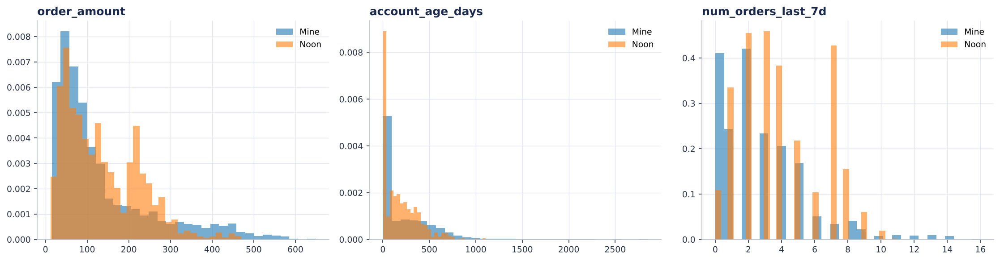

In [9]:
_show = plt.show
def _save_and_show(*a, **k):
    plt.gcf().savefig(P2 / "distributions" / "2.1a_helper_compare_distributions_as_supplied.png", dpi=150, bbox_inches="tight")
    plt.close("all")
plt.show = _save_and_show
H.compare_distributions(mine, noon_all)
plt.show = _show
display(Image(filename=str(P2 / "distributions" / "2.1a_helper_compare_distributions_as_supplied.png")))

### 2.1b The three brief features, with shared bins and variable-appropriate charts

`order_amount` is continuous (shared log-spaced bins). `account_age_days` and `num_orders_last_7d` are **integers** (data dictionary), so they are shown as shares per integer band or count, plus cumulative distributions (ECDFs), which need no binning. The ECDFs also show Noon's file as supplied (dashed) to make the effect of duplicates visible.

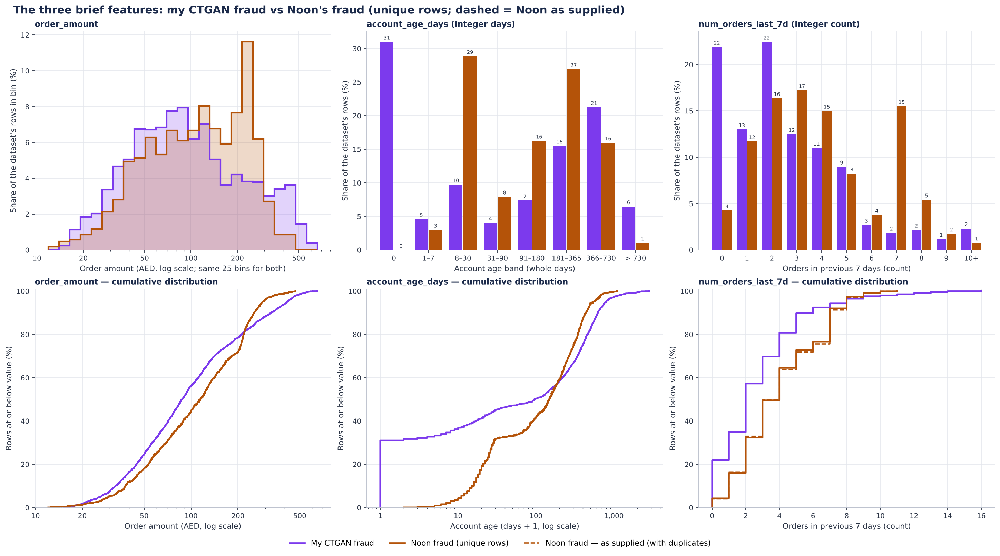

PosixPath('/home/claude/Noon_Fraud_Detection/outputs/phase2/distributions/2.1b_brief_features.png')

In [10]:
P.p2_brief_features(mine_u, noon_u, noon_all, COLORS2, P2 / "distributions" / "2.1b_brief_features.png",
                    "The three brief features: my CTGAN fraud vs Noon's fraud (unique rows; dashed = Noon as supplied)")

### 2.1c Descriptive statistics (all features)

In [11]:
frames_desc = {NAMES["seed"]: seed_h, NAMES["mine"]: mine_u, NAMES["noon"]: noon_u, "Noon fraud (as supplied)": noon_all}
desc = C.describe_numeric(frames_desc)
piv = desc.pivot(index=["feature", "type"], columns="dataset", values=["mean", "median", "sd", "p10", "p90", "max"])
piv = piv.reindex(columns=list(frames_desc), level=1)
display(piv.style.format(precision=2).set_caption("Numeric features (units: AED, days, hours, orders, km, claims)"))
desc.to_csv(P2 / "distributions" / "2.1c_numeric_descriptives.csv", index=False)
shares = C.describe_shares(frames_desc)
sh = shares.pivot(index=["feature", "level"], columns="dataset", values="share")[list(frames_desc)]
display(sh.style.format("{:.1%}").set_caption("Categorical and binary shares (denominator: rows of each dataset)"))
shares.to_csv(P2 / "distributions" / "2.1c_shares_with_wilson_ci.csv", index=False)
extra = pd.DataFrame({nm: {"account_age_days = 0 (%)": (d.account_age_days == 0).mean() * 100,
                           "account_age_days ≤ 7 (%)": (d.account_age_days <= 7).mean() * 100,
                           "account_age_days > 365 (%)": (d.account_age_days > 365).mean() * 100,
                           "orders placed 00:00–05:59 (%)": d.hour_of_day.between(0, 5).mean() * 100,
                           "delivery_distance_km > 15 (%)": (d.delivery_distance_km > 15).mean() * 100,
                           "order_amount > AED 300 (%)": (d.order_amount > 300).mean() * 100}
                      for nm, d in frames_desc.items()})
display(extra.style.format("{:.1f}").set_caption("Selected tail and threshold shares"))
extra.to_csv(P2 / "distributions" / "2.1c_threshold_shares.csv")

,My seed fraud,My CTGAN fraud,Noon fraud (unique rows),Noon fraud (as supplied)
account_age_days = 0 (%),13.8,31.0,0.0,0.0
account_age_days ≤ 7 (%),45.7,35.6,3.0,2.9
account_age_days > 365 (%),22.0,27.7,17.0,16.6
orders placed 00:00–05:59 (%),14.2,11.9,60.1,60.1
delivery_distance_km > 15 (%),0.0,0.0,1.4,1.5
order_amount > AED 300 (%),3.7,11.7,4.0,4.1


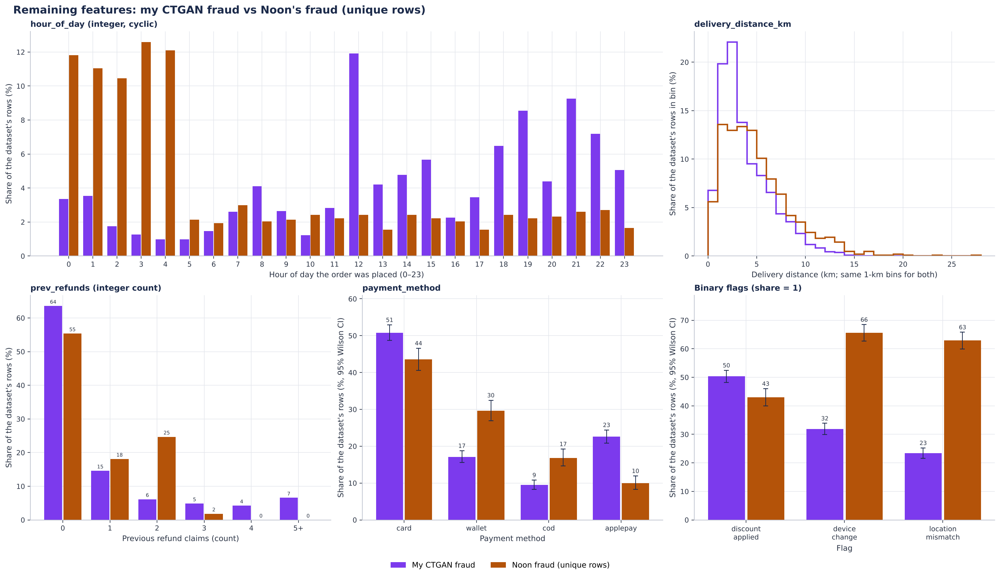

PosixPath('/home/claude/Noon_Fraud_Detection/outputs/phase2/distributions/2.1d_other_features.png')

In [12]:
P.p2_other_features(mine_u, noon_u, COLORS2, P2 / "distributions" / "2.1d_other_features.png",
                    "Remaining features: my CTGAN fraud vs Noon's fraud (unique rows)")

### 2.1e Effect sizes and tests

**Primary (unique rows).** Continuous features and integer features (account age, orders, refunds) use the KS distance D, with a **permutation p-value** that stays exact when integer data create ties, plus the Wasserstein-1 distance in the feature's own units. `hour_of_day` is cyclic, so it uses the total-variation distance (TVD) over the 24 hours with a χ² test. Categorical and binary features use TVD (for a binary flag, the absolute difference in shares) and Cramér's V with a χ² test. Holm-adjusted across the 10 features.

**Sensitivity (as supplied).** Effect sizes only. P-values are not computed, because duplicated rows break the independence those tests assume.

The bands (negligible < 0.05 ≤ small < 0.15 ≤ moderate < 0.30 ≤ large) are a judgement convention.

,pair,feature,type,headline effect,effect size,magnitude (judgement band),Holm-adjusted p,Wasserstein-1 (units),Cramér V,median A,median B,mean A,mean B
0,My CTGAN fraud vs Noon fraud (unique rows),order_amount,continuous,KS D,0.122,small,2.5e-03,29.848,nan,87.465,114.360,133.953,134.931
1,My CTGAN fraud vs Noon fraud (unique rows),account_age_days,discrete ordered (integer),KS D,0.327,large,2.5e-03,86.713,nan,94.000,147.000,237.415,191.261
2,My CTGAN fraud vs Noon fraud (unique rows),hour_of_day,discrete cyclic (24 h),TVD (24 hours),0.503,large,5.5e-181,nan,0.544,nan,nan,14.272,7.055
3,My CTGAN fraud vs Noon fraud (unique rows),num_orders_last_7d,discrete ordered (integer),KS D,0.250,moderate,2.5e-03,1.404,nan,2.000,4.000,2.693,3.953
4,My CTGAN fraud vs Noon fraud (unique rows),delivery_distance_km,continuous,KS D,0.185,moderate,2.5e-03,1.224,nan,3.000,4.300,3.805,5.022
5,My CTGAN fraud vs Noon fraud (unique rows),prev_refunds,discrete ordered (integer),KS D,0.139,small,2.5e-03,0.522,nan,0.000,0.000,0.994,0.730
6,My CTGAN fraud vs Noon fraud (unique rows),payment_method,categorical,TVD,0.199,moderate,1.7e-31,nan,0.218,nan,nan,nan,nan
7,My CTGAN fraud vs Noon fraud (unique rows),discount_applied,binary,TVD,0.073,small,6.4e-04,nan,0.069,nan,nan,0.503,0.430
8,My CTGAN fraud vs Noon fraud (unique rows),device_change,binary,TVD,0.338,large,2.2e-71,nan,0.320,nan,nan,0.319,0.656
9,My CTGAN fraud vs Noon fraud (unique rows),location_mismatch,binary,TVD,0.395,large,5.4e-103,nan,0.386,nan,nan,0.234,0.629


,effect size — unique (primary),magnitude (judgement band) — unique (primary),effect size — as supplied,magnitude (judgement band) — as supplied
feature,,,,
order_amount,0.122,small,0.122,small
account_age_days,0.327,large,0.327,large
hour_of_day,0.503,large,0.498,large
num_orders_last_7d,0.250,moderate,0.244,moderate
delivery_distance_km,0.185,moderate,0.193,moderate
prev_refunds,0.139,small,0.140,small
payment_method,0.199,moderate,0.207,moderate
discount_applied,0.073,small,0.075,small
device_change,0.338,large,0.329,large


[FINDING] Features whose magnitude band changes when duplicates are kept: none


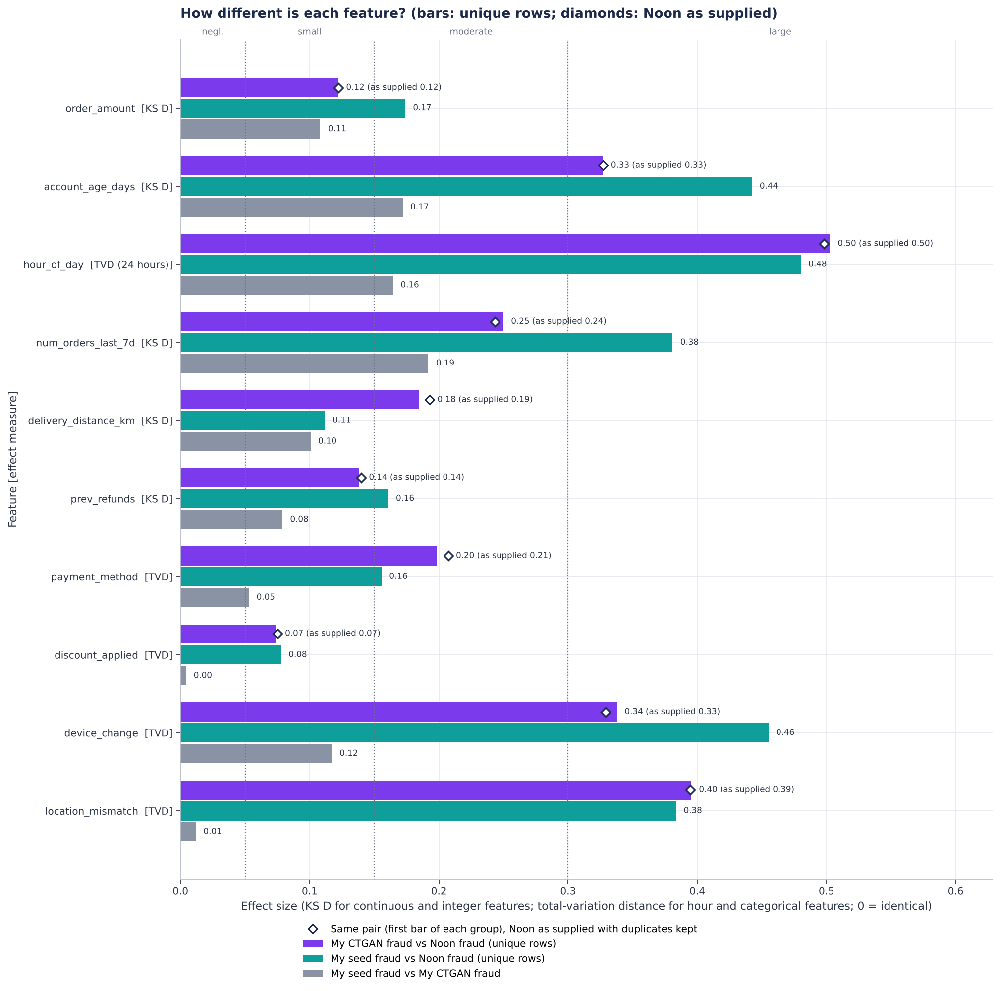

PosixPath('/home/claude/Noon_Fraud_Detection/outputs/phase2/distributions/2.1e_effect_sizes.png')

In [13]:
eff_main = C.compare_features(mine_u, noon_u, NAMES["mine"], NAMES["noon"], seed=SEED)
eff_seed = C.compare_features(seed_h, noon_u, NAMES["seed"], NAMES["noon"], seed=SEED)
eff_ref = C.compare_features(seed_h, mine_u, NAMES["seed"], NAMES["mine"], seed=SEED)
eff_sup = C.compare_features(mine_h, noon_all, NAMES["mine"], "Noon fraud (as supplied)", n_perm=0, seed=SEED)
eff_sup[["p-value", "Holm-adjusted p"]] = np.nan
eff = pd.concat([eff_main, eff_seed, eff_ref], ignore_index=True)
cols = ["pair", "feature", "type", "headline effect", "effect size", "magnitude (judgement band)", "Holm-adjusted p",
        "Wasserstein-1 (units)", "Cramér V", "median A", "median B", "mean A", "mean B"]
display(eff[cols].style.format(precision=3).format("{:.1e}", subset=["Holm-adjusted p"]))
cmp_sup = eff_main.set_index("feature")[["effect size", "magnitude (judgement band)"]].join(
    eff_sup.set_index("feature")[["effect size", "magnitude (judgement band)"]], lsuffix=" — unique (primary)", rsuffix=" — as supplied")
display(cmp_sup.style.format(precision=3, subset=[c for c in cmp_sup.columns if "size" in c]))
flips = cmp_sup[cmp_sup.iloc[:, 1] != cmp_sup.iloc[:, 3]]
print(f"[FINDING] Features whose magnitude band changes when duplicates are kept: {list(flips.index) or 'none'}")
pd.concat([eff, eff_sup], ignore_index=True).to_csv(P2 / "distributions" / "2.1e_effect_sizes_and_tests.csv", index=False)
PAIR_COLORS = {f"{NAMES['mine']} vs {NAMES['noon']}": MY_GAN_COLOR, f"{NAMES['seed']} vs {NAMES['noon']}": SEED_FRAUD_COLOR,
               f"{NAMES['seed']} vs {NAMES['mine']}": PAIR_REF_COLOR}
P.p2_effect_chart(eff, PAIR_COLORS, eff_sup, P2 / "distributions" / "2.1e_effect_sizes.png",
                  "How different is each feature? (bars: unique rows; diamonds: Noon as supplied)")

### 2.1f Relationships between features

Fraud is a pattern of combinations. Three views follow: conditional profiles (e.g. device-change rate by account age), correlation differences, and the share of rows matching each of my five Phase 1 typology signatures. The signatures are my own definitions, a lens built on my assumptions, not Noon's labels.

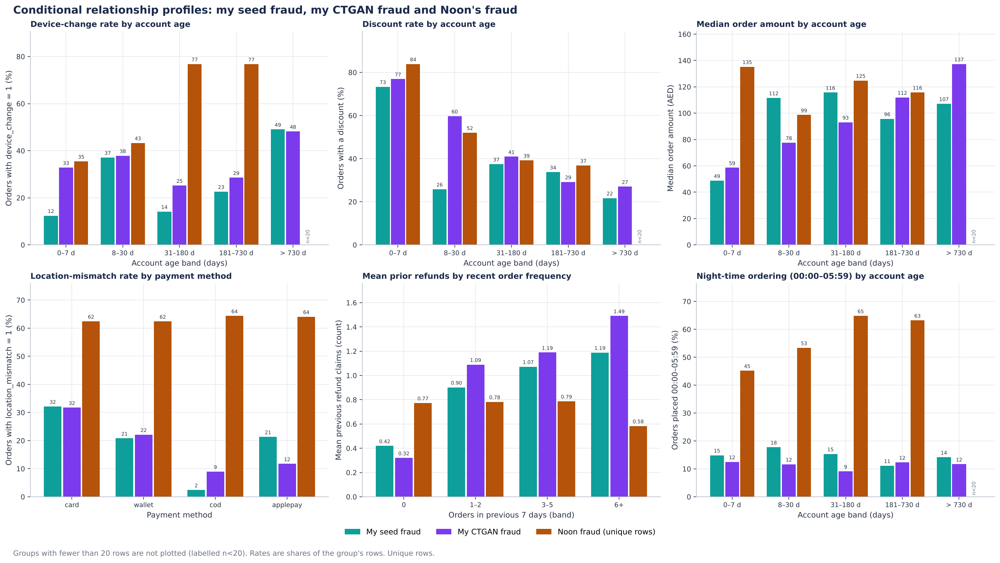

,pair,mean |Δρ| over feature pairs
0,My CTGAN fraud vs Noon fraud (unique rows),0.141
1,My seed fraud vs Noon fraud (unique rows),0.111
2,My seed fraud vs My CTGAN fraud,0.079


,feature pair,ρ My CTGAN fraud,ρ Noon fraud (unique rows),Δρ (B − A)
0,device_change × location_mismatch,0.331,-0.159,-0.490
1,account_age_days × location_mismatch,-0.194,0.292,0.486
2,order_amount × discount_applied,-0.433,-0.004,0.430
3,num_orders_last_7d × discount_applied,-0.347,0.054,0.401
4,order_amount × num_orders_last_7d,0.362,-0.036,-0.398
5,delivery_distance_km × location_mismatch,0.302,-0.051,-0.353
6,order_amount × account_age_days,0.331,0.016,-0.315
7,num_orders_last_7d × prev_refunds,0.246,-0.069,-0.314


,My seed fraud,My CTGAN fraud,Noon fraud (unique rows)
Account takeover age > 180 d · device change · location mismatch,3.7%,4.4%,22.7%
Promo abuse age < 15 d · discount · basket < AED 50,22.9%,15.3%,1.2%
Refund abuse ≥ 2 prior refunds · ≥ 2 orders in 7 d,12.9%,17.8%,21.7%
Stolen card card · location mismatch · age < 60 d,10.2%,10.7%,4.5%
COD fake order COD · age < 60 d · basket > AED 100,4.2%,1.5%,2.9%


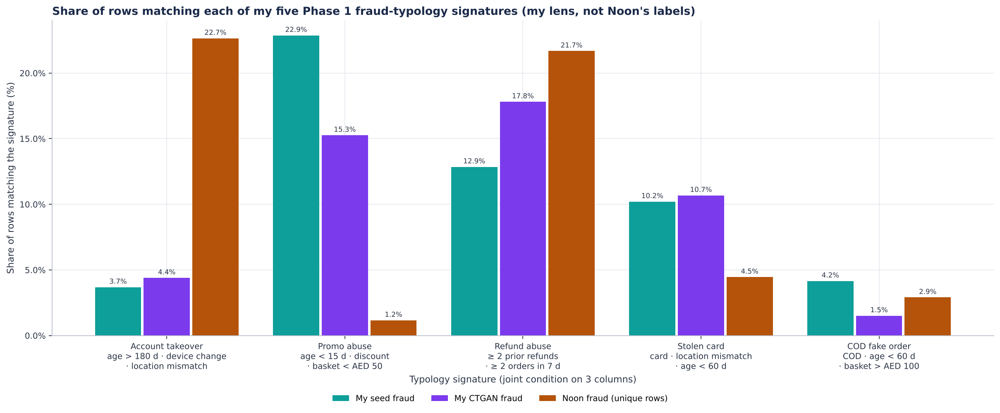

PosixPath('/home/claude/Noon_Fraud_Detection/outputs/phase2/relationships/2.1f_typology_signatures.png')

In [14]:
rel = C.relationship_profiles({NAMES["seed"]: seed_h, NAMES["mine"]: mine_u, NAMES["noon"]: noon_u})
rel.to_csv(P2 / "relationships" / "2.1f_relationship_profiles.csv", index=False)
P.relationship_panels(rel, COLORS3, P2 / "relationships" / "2.1f_relationship_profiles.png",
                      "Conditional relationship profiles: my seed fraud, my CTGAN fraud and Noon's fraud")
corr_tab = pd.DataFrame([{"pair": f"{a} vs {b}", "mean |Δρ| over feature pairs": C.mean_abs_corr_diff(da, db)}
                         for (a, da), (b, db) in [((NAMES["mine"], mine_u), (NAMES["noon"], noon_u)),
                                                  ((NAMES["seed"], seed_h), (NAMES["noon"], noon_u)),
                                                  ((NAMES["seed"], seed_h), (NAMES["mine"], mine_u))]])
display(corr_tab.style.format(precision=3))
top_corr = C.top_corr_differences(mine_u, noon_u, NAMES["mine"], NAMES["noon"])
display(top_corr.style.format(precision=3).set_caption("Largest Spearman-correlation differences (my CTGAN vs Noon unique)"))
corr_tab.to_csv(P2 / "relationships" / "2.1f_correlation_summary.csv", index=False)
top_corr.to_csv(P2 / "relationships" / "2.1f_top_correlation_differences.csv", index=False)
sig = G.signature_shares({NAMES["seed"]: seed_h, NAMES["mine"]: mine_u, NAMES["noon"]: noon_u})
display(sig.style.format("{:.1%}"))
sig.to_csv(P2 / "relationships" / "2.1f_typology_signatures.csv")
P.grouped_bars(sig, COLORS3, P2 / "relationships" / "2.1f_typology_signatures.png",
               "Share of rows matching each of my five Phase 1 fraud-typology signatures (my lens, not Noon's labels)",
               "Share of rows matching the signature (%)", "Typology signature (joint condition on 3 columns)", fmt="{:.1%}", figsize=(15, 5.8))

In [15]:
e = eff_main.sort_values("effect size", ascending=False)
print("[FINDING] Largest differences, my CTGAN fraud vs Noon fraud (unique rows):")
for _, r in e.iterrows():
    print(f"  • {r.feature:22s} {r['headline effect']:15s} {r['effect size']:.3f} ({r['magnitude (judgement band)']}), Holm p = {r['Holm-adjusted p']:.1e}")

[FINDING] Largest differences, my CTGAN fraud vs Noon fraud (unique rows):
  • hour_of_day            TVD (24 hours)  0.503 (large), Holm p = 5.5e-181
  • location_mismatch      TVD             0.395 (large), Holm p = 5.4e-103
  • device_change          TVD             0.338 (large), Holm p = 2.2e-71
  • account_age_days       KS D            0.327 (large), Holm p = 2.5e-03
  • num_orders_last_7d     KS D            0.250 (moderate), Holm p = 2.5e-03
  • payment_method         TVD             0.199 (moderate), Holm p = 1.7e-31
  • delivery_distance_km   KS D            0.185 (moderate), Holm p = 2.5e-03
  • prev_refunds           KS D            0.139 (small), Holm p = 2.5e-03
  • order_amount           KS D            0.122 (small), Holm p = 2.5e-03
  • discount_applied       TVD             0.073 (small), Holm p = 6.4e-04


### Interpretation of Step 2.1

*Figures below are from the unique-row analysis unless marked "as supplied"; every number is in the CSV files in `outputs/phase2/distributions/` and `outputs/phase2/relationships/`.*

**Observed — the three features the brief names.**
* **`order_amount`: small difference (KS D = 0.122).** Both files have almost the same mean (AED 134.0 mine vs 134.9 Noon) but are shaped differently. Noon's median is higher (114 vs 87), and 24.5% of its rows sit between AED 200 and 300 (mine: 9.9%). My CTGAN has the heavier upper tail: 11.7% of my rows are above AED 300 vs 4.0% of Noon's, and my maximum is 649 vs Noon's 470.
* **`account_age_days`: large difference (KS D = 0.327), the biggest of the three.** Treated as a whole-day ordered variable, as the user instructed. 31.0% of my CTGAN rows are 0-day accounts, and Noon has none (its minimum is 1 day). Only 3.0% of Noon's rows are ≤ 7 days old (mine: 35.6%). Noon's median is 147 days (mine 94), and Noon has no account older than 1,107 days.
* **`num_orders_last_7d`: moderate difference (KS D = 0.250).** Noon's fraudsters are busier (median 4 vs 2 orders; mean 3.95 vs 2.69). Only 4.2% of Noon's rows have zero orders (mine 21.9%), and Noon has a spike at exactly 7 orders: 15.5% vs 1.8%.

**Observed — the other features.**
* **`hour_of_day`: the largest single difference (TVD = 0.503).** 60.1% of Noon's fraud is placed between 00:00 and 05:59. Each hour from 00 to 04 holds 10.5–12.6%, and every other hour holds only about 1.5–3%. My CTGAN puts 11.9% of rows in that window and peaks at lunch (12:00, 11.9%) and in the evening.
* **Binary flags.**
  * `location_mismatch` differs strongly (TVD 0.395): 62.9% of Noon's rows vs 23.4% of mine.
  * `device_change` also differs strongly (TVD 0.338): 65.6% vs 31.9%.
  * `discount_applied` is close (43.0% vs 50.3%).
* **`payment_method`: moderate difference (TVD 0.199).** Noon has more wallet (29.6% vs 17.1%) and cash-on-delivery (16.8% vs 9.5%) fraud, and less Apple Pay (10.0% vs 22.6%).
* **`delivery_distance_km`: moderate difference (KS D 0.185).** Noon's median is 4.3 km vs 3.0, and 1.4% of Noon's rows exceed 15 km, which never happens in mine.
* **`prev_refunds`: small difference (KS D 0.139).** Noon only uses 0–3 refunds, while 10.8% of my rows have more than 3.

**Observed — relationships between features.**
* In Noon's file, location mismatch is about 62–64% for **every** payment method, including cash on delivery. In mine it is strongly tied to the payment method: 31.7% for card but 9.0% for COD.
* Noon's device-change rate rises with account age, from 35.5% at 0–7 days to about 77% from 31 days onward. Mine stays between 25% and 48%.
* Noon's night-time share is high in every age band (45–65%).
* Noon's mean refunds stay flat (0.77–0.79) across order frequency, falling to 0.58 for 6+ orders. In mine, refunds rise from 0.32 to 1.49 as order frequency rises.
* The largest correlation differences reverse sign:
  * `device_change × location_mismatch`: ρ = +0.33 in mine vs −0.16 in Noon's;
  * `account_age_days × location_mismatch`: −0.19 vs +0.29.
* Mean |Δρ| is 0.141 for my CTGAN vs Noon, 0.111 for my seed vs Noon, and 0.079 for my seed vs my CTGAN.

**Observed — duplicates do not change the picture.** Keeping Noon's duplicates moves every effect size by at most 0.009, and no feature changes magnitude band. My **seed** fraud differs from Noon's about as much as my CTGAN does, and on some features more (account age 0.442, device change 0.455, orders 0.381). So the gap is mainly between my *Phase 1 assumptions* and Noon's data, not an artefact of my GAN.

**Interpretation (not proven by these data).**
* Noon's fraud looks like an **account-takeover and night-time pattern**: established accounts (median 147 days) suddenly ordering from a new device at a mismatched location in the small hours, with frequent recent orders.
* My Phase 1 design gave most weight to **brand-new-account promo abuse** (typology signature 22.9% in my seed vs 1.2% in Noon's). My CTGAN then added the 0-day spike.
* The near-uniform blocks in Noon's data look like rule-based generation or a model trained on rule-based data rather than on organic behaviour:
  * hours 00–04 at about 11–12% each, then about 2% per hour;
  * mismatch at a constant level across payment methods;
  * refunds limited to 0–3.
* This is a hypothesis. Noon's file is a synthetic benchmark sample, not real fraud, so it shows how *Noon's* generator sees fraud, not what real fraud looks like. Which picture is closer to reality can only be judged against the real referee data in Phase 3.

## Step 2.2 — Fraud proportion, with every denominator explicit

In [16]:
p1 = json.loads((OUTPUTS / "metrics" / "phase1_metrics.json").read_text())
n_train = len(split["train"])
n_train_fraud = int(seed.iloc[split["train"]][TARGET].sum())
ratio_used = p1["augmentation_ratios"]["B_ctgan"]
rows = [
    ("1", "My complete Phase 1 seed dataset", "fraud rows / all seed rows", int(seed[TARGET].sum()), len(seed)),
    ("1", "My seed training partition", "fraud rows / training rows", n_train_fraud, n_train),
    ("2", "My GAN-generated fraud file vs training FRAUD rows", "GAN rows / training fraud rows", len(mine), n_train_fraud),
    ("2", "My GAN-generated fraud file vs ALL training rows", "GAN rows / training rows", len(mine), n_train),
    ("2", f"GAN rows actually added in Phase 1 (selected ratio {ratio_used}×)", "GAN rows used / training fraud rows",
     int(round(ratio_used * n_train_fraud)), n_train_fraud),
]
for r_ in AUG_RATIOS:
    add = int(round(r_ * n_train_fraud))
    rows.append(("3", f"Augmented training set at {r_}×{' (selected)' if r_ == ratio_used else ''}",
                 "(training fraud + GAN rows) / (training rows + GAN rows)", n_train_fraud + add, n_train + add))
rows += [
    ("4", "Noon's synthetic fraud file — as supplied", "is_fraud = 1 rows / all rows in the file", int(noon_all[TARGET].sum()), len(noon_all)),
    ("4", "Noon's synthetic fraud file — distinct rows", "is_fraud = 1 distinct rows / distinct rows", int(noon_u[TARGET].sum()), len(noon_u)),
    ("context", "Real referee test set (from the A3 integrity check; NOT Noon's synthetic file)", "fraud rows / all referee rows",
     REFEREE_FRAUD, REFEREE_N),
]
prop = pd.DataFrame(rows, columns=["item (brief §2.2)", "population", "denominator", "numerator", "denominator count"])
prop["proportion"] = prop["numerator"] / prop["denominator count"]
display(prop.style.format({"proportion": "{:.3%}", "numerator": "{:,}", "denominator count": "{:,}"}))
prop.to_csv(P2 / "fraud_proportion" / "2.2_fraud_proportion_denominators.csv", index=False)

,item (brief §2.2),population,denominator,numerator,denominator count,proportion
0,1,My complete Phase 1 seed dataset,fraud rows / all seed rows,"1,512","50,000",3.024%
1,1,My seed training partition,fraud rows / training rows,"1,058","35,000",3.023%
2,2,My GAN-generated fraud file vs training FRAUD rows,GAN rows / training fraud rows,"2,116","1,058",200.000%
3,2,My GAN-generated fraud file vs ALL training rows,GAN rows / training rows,"2,116","35,000",6.046%
4,2,GAN rows actually added in Phase 1 (selected ratio 0.25×),GAN rows used / training fraud rows,264,"1,058",24.953%
5,3,Augmented training set at 0.25× (selected),(training fraud + GAN rows) / (training rows + GAN rows),"1,322","35,264",3.749%
6,3,Augmented training set at 0.5×,(training fraud + GAN rows) / (training rows + GAN rows),"1,587","35,529",4.467%
7,3,Augmented training set at 1.0×,(training fraud + GAN rows) / (training rows + GAN rows),"2,116","36,058",5.868%
8,3,Augmented training set at 2.0×,(training fraud + GAN rows) / (training rows + GAN rows),"3,174","37,116",8.552%
9,4,Noon's synthetic fraud file — as supplied,is_fraud = 1 rows / all rows in the file,"3,000","3,000",100.000%


**Reading Step 2.2.**

* **Both synthetic fraud files are fraud-only.** Noon's file has `is_fraud = 1` in every row (100% within the file, whether counted as supplied or as distinct rows), and so does my CTGAN file. Comparing their "fraud proportions" is therefore degenerate (100% vs 100%) and says nothing about which is more realistic, or about Noon's transaction-level fraud rate, which is **not** 100%.
* **The benchmark's "~0.3%" belongs to the real referee test set**, not to Noon's synthetic file. A3 confirms it from the file itself (shown in the table, label counts only).
* **What *can* be compared is how much synthetic fraud each approach adds to a training set.** In Phase 1, the selected augmentation added a quarter of my training fraud count. The benchmark's warning — "If you over-generated fraud, [false positives rise]" — is about this training composition, not about the composition of the synthetic files.
* **Missing denominators.** Noon has not supplied how many real transactions or real fraud rows Model B was trained on, nor how much of its 3,000-row (≈1,033 distinct) synthetic fraud it added. Noon's augmented training composition therefore cannot be computed, and it is not estimated here.

## Step 2.3 — The lie-detector test

The classifier tries to tell *which source* a fraud row came from (mine = 0, Noon = 1); it does not predict fraud. In every protocol, `is_fraud` is excluded (it is 1 everywhere and is not in the helper's feature list); features and categorical encoding come from the helper's own `_prep` (9 numeric columns + one-hot `payment_method`); and the model is the helper's `RandomForestClassifier(n_estimators=100, random_state=0)`.

| Protocol | Rows | Sizes | Validation | Statistic | Role |
|---|---|---|---|---|---|
| **Helper (as specified)** | As supplied | Unequal | `StratifiedKFold(3)`, no shuffle | Accuracy | Professor's comparison, reported unchanged |
| **Primary** | Unique rows, overlaps removed, distance at 1 dp | Equal (mine subsampled), 10 repeats | Shuffled `StratifiedKFold(5)` | **ROC-AUC**; balanced accuracy; accuracy | Main result; permutation p-value (1,000 permutations, **no groups**) |
| **Sensitivity — grouped** | As supplied (duplicates kept) | Unequal | Shuffled `StratifiedGroupKFold(5)` keyed on row identity | ROC-AUC; balanced accuracy; accuracy vs majority baseline | Duplicates kept but never straddle folds; **no p-value** (a row-grouped permutation would be degenerate) |
| **Leakage illustration** | As supplied | Unequal | Shuffled `StratifiedKFold(5)`, no groups | Same | Shows how much duplicate copies inflate the score |

In [17]:
t_ = time.time()
acc_helper = H.lie_detector(mine, noon_all)
base_helper = max(len(mine), len(noon_all)) / (len(mine) + len(noon_all))
leak = C.helper_fold_leakage(mine, noon_all)
print(f"Helper accuracy {acc_helper:.4f} · majority-class baseline for these sizes ({len(mine):,} vs {len(noon_all):,}) = {base_helper:.4f} · {time.time() - t_:.0f}s")
display(pd.Series(leak).to_frame("helper's own folds (StratifiedKFold(3), unshuffled)"))

Lie-detector accuracy: 0.96  (0.50 = your fraud looks just like Noon's; 0.90+ = very different)
Helper accuracy 0.9595 · majority-class baseline for these sizes (2,116 vs 3,000) = 0.5864 · 1s


,"helper's own folds (StratifiedKFold(3), unshuffled)"
mine test rows with an exact twin in training,0.0000
mine test rows,"2,116.0000"
Noon test rows with an exact twin in training,"2,500.0000"
Noon test rows,"3,000.0000"
share of Noon test rows leaked,0.8333


In [18]:
t_ = time.time()
prim = C.lie_detector_primary(mine_u, noon_u, H._prep, SEEDS)
grp = C.lie_detector_as_supplied(mine_h, noon_all, H._prep, SEEDS, grouped=True)
ungrp = C.lie_detector_as_supplied(mine_h, noon_all, H._prep, SEEDS, grouped=False)
for nm, d in (("PRIMARY — unique rows, balanced", prim), ("SENSITIVITY — as supplied, grouped by row", grp),
              ("LEAKAGE ILLUSTRATION — as supplied, ungrouped", ungrp)):
    print(nm); display(d.describe().loc[["mean", "std", "min", "max"]].drop(columns="seed").style.format(precision=4))
prim.to_csv(P2 / "lie_detector" / "2.3_primary_unique_balanced.csv", index=False)
grp.to_csv(P2 / "lie_detector" / "2.3_sensitivity_as_supplied_grouped.csv", index=False)
ungrp.to_csv(P2 / "lie_detector" / "2.3_leakage_as_supplied_ungrouped.csv", index=False)
print(f"{time.time() - t_:.0f}s")

PRIMARY — unique rows, balanced


,n per source,ROC-AUC,balanced accuracy,accuracy,majority baseline
mean,1033.0000,0.9745,0.9198,0.9198,0.5000
std,0.0000,0.0027,0.0049,0.0049,0.0000
min,1033.0000,0.9704,0.9143,0.9143,0.5000
max,1033.0000,0.9789,0.9293,0.9293,0.5000


SENSITIVITY — as supplied, grouped by row


,n mine,n Noon,ROC-AUC,balanced accuracy,accuracy,majority baseline
mean,2116.0000,3000.0000,0.9750,0.9199,0.9186,0.5864
std,0.0000,0.0000,0.0007,0.0035,0.0038,0.0000
min,2116.0000,3000.0000,0.9737,0.9128,0.9107,0.5864
max,2116.0000,3000.0000,0.9761,0.9245,0.9228,0.5864


LEAKAGE ILLUSTRATION — as supplied, ungrouped


,n mine,n Noon,ROC-AUC,balanced accuracy,accuracy,majority baseline
mean,2116.0000,3000.0000,0.9959,0.9551,0.9613,0.5864
std,0.0000,0.0000,0.0003,0.0024,0.0022,0.0000
min,2116.0000,3000.0000,0.9952,0.9512,0.9576,0.5864
max,2116.0000,3000.0000,0.9963,0.9581,0.9640,0.5864


52s


{'observed mean CV ROC-AUC': np.float64(0.9759), 'permutation p-value': np.float64(0.001), 'null mean': np.float64(0.5005), 'null 99th pct': np.float64(0.5398), 'null max': np.float64(0.5498), 'n_permutations': 1000} · 752s


,mean drop in ROC-AUC,sd over folds
account_age_days,0.0962,0.0089
location_mismatch,0.0675,0.0045
hour_of_day,0.0423,0.0061
device_change,0.0235,0.0039
prev_refunds,0.0140,0.0023
num_orders_last_7d,0.0113,0.0020
order_amount,0.0110,0.0030
delivery_distance_km,0.0041,0.0024
payment_method,0.0035,0.0007
discount_applied,0.0014,0.0006


,primary sample (seed 0)
ROC-AUC (real rows),0.9755
ROC-AUC (columns shuffled within source: marginals only),0.9492
AUC attributable to joint structure,0.0263


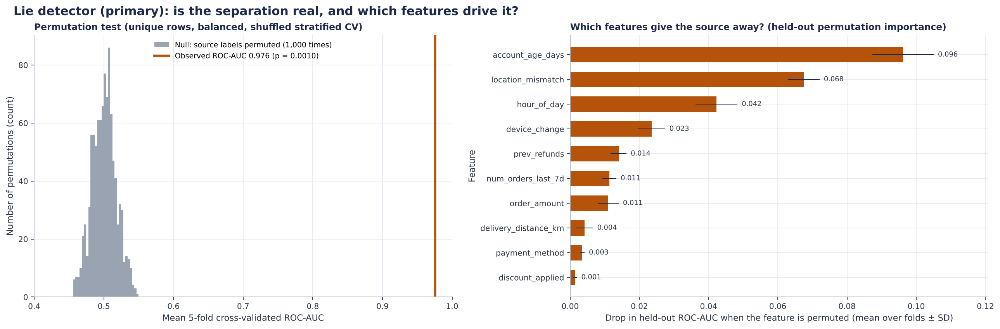

PosixPath('/home/claude/Noon_Fraud_Detection/outputs/phase2/lie_detector/2.3_permutation_test_and_importance.png')

In [19]:
t_ = time.time()
perm = C.permutation_test(mine_u, noon_u, H._prep, seed=0, n_perm=N_PERM)
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in perm.items() if k != "null"}, f"· {time.time() - t_:.0f}s")
imp, ctrl = C.importance_and_control(mine_u, noon_u, H._prep, seed=0)
display(imp.style.format(precision=4))
display(pd.Series(ctrl).to_frame("primary sample (seed 0)").style.format(precision=4))
imp.to_csv(P2 / "lie_detector" / "2.3_permutation_importance.csv")
pd.DataFrame([{k: v for k, v in perm.items() if k != "null"}]).to_csv(P2 / "lie_detector" / "2.3_permutation_test.csv", index=False)
pd.Series(ctrl).to_csv(P2 / "lie_detector" / "2.3_marginals_only_control.csv")
P.p2_perm_and_importance(perm, imp, NOON_COLOR, P2 / "lie_detector" / "2.3_permutation_test_and_importance.png",
                         "Lie detector (primary): is the separation real, and which features drive it?")

,protocol,n (source 0 / Noon or 1),accuracy,ROC-AUC,ROC-AUC sd,balanced accuracy,majority baseline
0,"Helper as specified (as supplied, cv=3 unshuffled)","2,116 / 3,000",0.9595,—,—,—,0.5864
1,"PRIMARY (unique rows, balanced, 10 repeats)","1,033 / 1,033",0.9198,0.9745,0.0027,0.9198,0.5000
2,"Sensitivity: as supplied, grouped by row","2,116 / 3,000",0.9186,0.9750,0.0007,0.9199,0.5864
3,"Leakage illustration: as supplied, ungrouped","2,116 / 3,000",0.9613,0.9959,0.0003,0.9551,0.5864
4,Reference: MY SEED fraud vs Noon (primary protocol),"1,033 each",0.9281,0.9771,0.0013,0.9281,0.5000
5,Reference: my seed fraud vs MY CTGAN (primary protocol),"1,058 each",0.7168,0.7909,0.0060,0.7168,0.5000


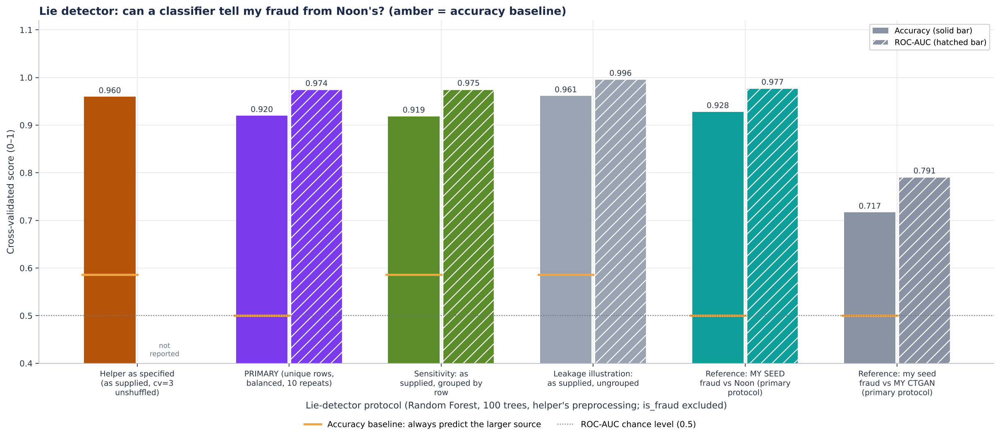

PosixPath('/home/claude/Noon_Fraud_Detection/outputs/phase2/lie_detector/2.3_lie_detector_protocols.png')

In [20]:
ref_seed_noon = C.lie_detector_primary(seed_h.drop_duplicates(FEATURES), noon_u, H._prep, SEEDS)
ref_seed_mine = C.lie_detector_primary(seed_h.drop_duplicates(FEATURES), mine_u, H._prep, SEEDS)
summ = pd.DataFrame([
    {"protocol": "Helper as specified\n(as supplied, cv=3 unshuffled)", "n (source 0 / Noon or 1)": f"{len(mine):,} / {len(noon_all):,}",
     "accuracy": acc_helper, "ROC-AUC": np.nan, "ROC-AUC sd": np.nan, "balanced accuracy": np.nan, "majority baseline": base_helper, "color": NOON_COLOR},
    {"protocol": "PRIMARY\n(unique rows, balanced, 10 repeats)", "n (source 0 / Noon or 1)": f"{N_NOON_U:,} / {N_NOON_U:,}",
     "accuracy": prim.accuracy.mean(), "ROC-AUC": prim["ROC-AUC"].mean(), "ROC-AUC sd": prim["ROC-AUC"].std(),
     "balanced accuracy": prim["balanced accuracy"].mean(), "majority baseline": 0.5, "color": MY_GAN_COLOR},
    {"protocol": "Sensitivity: as supplied,\ngrouped by row", "n (source 0 / Noon or 1)": f"{len(mine_h):,} / {len(noon_all):,}",
     "accuracy": grp.accuracy.mean(), "ROC-AUC": grp["ROC-AUC"].mean(), "ROC-AUC sd": grp["ROC-AUC"].std(),
     "balanced accuracy": grp["balanced accuracy"].mean(), "majority baseline": grp["majority baseline"].iloc[0], "color": "#5B8C2A"},
    {"protocol": "Leakage illustration:\nas supplied, ungrouped", "n (source 0 / Noon or 1)": f"{len(mine_h):,} / {len(noon_all):,}",
     "accuracy": ungrp.accuracy.mean(), "ROC-AUC": ungrp["ROC-AUC"].mean(), "ROC-AUC sd": ungrp["ROC-AUC"].std(),
     "balanced accuracy": ungrp["balanced accuracy"].mean(), "majority baseline": ungrp["majority baseline"].iloc[0], "color": "#9AA3B2"},
    {"protocol": "Reference: MY SEED fraud\nvs Noon (primary protocol)", "n (source 0 / Noon or 1)": f"{ref_seed_noon['n per source'].iloc[0]:,} each",
     "accuracy": ref_seed_noon.accuracy.mean(), "ROC-AUC": ref_seed_noon["ROC-AUC"].mean(), "ROC-AUC sd": ref_seed_noon["ROC-AUC"].std(),
     "balanced accuracy": ref_seed_noon["balanced accuracy"].mean(), "majority baseline": 0.5, "color": SEED_FRAUD_COLOR},
    {"protocol": "Reference: my seed fraud\nvs MY CTGAN (primary protocol)", "n (source 0 / Noon or 1)": f"{ref_seed_mine['n per source'].iloc[0]:,} each",
     "accuracy": ref_seed_mine.accuracy.mean(), "ROC-AUC": ref_seed_mine["ROC-AUC"].mean(), "ROC-AUC sd": ref_seed_mine["ROC-AUC"].std(),
     "balanced accuracy": ref_seed_mine["balanced accuracy"].mean(), "majority baseline": 0.5, "color": PAIR_REF_COLOR},
])
display(summ.drop(columns="color").style.format(precision=4, na_rep="—"))
summ.drop(columns="color").to_csv(P2 / "lie_detector" / "2.3_protocol_summary.csv", index=False)
P.p2_lie_detector(summ, P2 / "lie_detector" / "2.3_lie_detector_protocols.png",
                  "Lie detector: can a classifier tell my fraud from Noon's? (amber = accuracy baseline)")

### Interpretation of Step 2.3

**Observed.**

| Protocol | Accuracy | ROC-AUC (mean ± SD over 10 repeats) | Balanced accuracy | Accuracy of "always guess the larger source" |
|---|---|---|---|---|
| Helper as specified (as supplied, 3 unshuffled folds) | 0.960 | not computed by the helper | not computed | 0.586 |
| **Primary** (unique rows, 1,033 per source, shuffled 5-fold) | 0.920 | **0.974 ± 0.003** | 0.920 | 0.500 |
| Sensitivity: as supplied, grouped by row | 0.919 | 0.975 ± 0.001 | 0.920 | 0.586 |
| Leakage illustration: as supplied, ungrouped | 0.961 | 0.996 ± 0.000 | 0.955 | 0.586 |
| Reference: my seed fraud vs Noon (primary protocol) | 0.928 | 0.977 ± 0.001 | 0.928 | 0.500 |
| Reference: my seed fraud vs my CTGAN (primary protocol) | 0.717 | 0.791 ± 0.006 | 0.717 | 0.500 |

* **Permutation test (primary only).** Observed mean cross-validated ROC-AUC is 0.976 on the seed-0 sample. Across 1,000 label permutations without groups, the null distribution has mean 0.500 and maximum 0.550, so p = 1/1,001 ≈ 0.001. That is the smallest p-value 1,000 permutations can produce, so the true p is at most about 0.001.
* **Which features give the source away** (held-out permutation importance, drop in ROC-AUC):
  * `account_age_days` 0.096;
  * `location_mismatch` 0.068;
  * `hour_of_day` 0.042;
  * `device_change` 0.023;
  * every other feature ≤ 0.014.
* **Marginals-only control.** Shuffling each column within its source keeps each feature's distribution but destroys the combinations. This lowers the AUC only from 0.976 to 0.949, so about 0.026 of AUC depends on how features combine; nearly all the separation comes from single features.

**Why the protocols differ, and which number to use.**
* **The helper's 0.96 is inflated, and its own printout misleads.**
  1. Noon's file contains each of its 1,033 distinct rows about three times on average. In the helper's own unshuffled 3-fold split, 2,500 of the 3,000 Noon test rows (83.3%) have an identical copy in the training folds, so part of the score is recall of seen rows.
  2. The two files have unequal sizes (2,116 vs 3,000), so always guessing "Noon" already scores 0.586, not 0.50. The helper's message "0.50 = your fraud looks just like Noon's" is therefore wrong for these files.
  3. Accuracy depends on a 0.5 threshold. ROC-AUC does not, and its chance level is 0.5 whatever the class sizes.
* **Primary (the headline).** Deduplicating both files, removing cross-source overlaps (there were none) and balancing to 1,033 rows each removes all three problems. Repeated rows cannot leak, chance is exactly 0.5 for both accuracy and AUC, and the rows are close enough to exchangeable for a standard, ungrouped permutation p-value to be valid.
* **Sensitivity, grouped (duplicates kept).** Folds are split by row identity, so every copy of a row stays on one side. The result matches the primary (0.975 vs 0.974), which shows deduplication did not create the result.
  * As instructed, **no p-value** is reported here. Permuting labels while keeping row groups would be degenerate, because each group contains only one source.
  * Its accuracy must be read against its own baseline of 0.586.
* **Leakage illustration.** The same as-supplied data with ungrouped folds gives 0.996, which is 0.021 higher than grouped. That gap is pure duplicate leakage; it is not information about fraud.

**What this means.**
* A classifier tells my fraud from Noon's about 92% of the time on a balanced sample (AUC 0.974), so the two generators produce **very different** fraud, well above the 0.90 "very different" mark the helper's own printout uses.
* The difference is not caused by my GAN's imperfections. My **seed** fraud is just as easy to tell apart from Noon's (AUC 0.977), while my CTGAN is much harder to tell apart from its own training data (AUC 0.791). The separation comes from different **assumptions about what fraud looks like**.
* The classifier relies on the same features as the effect sizes: account age, location mismatch, hour and device change.

**Limits of this test.**
* An AUC near 0.5 would only mean this classifier could not tell the files apart. It would not prove they come from the same distribution, and it would not show that either looks like real fraud.
* A high AUC shows the files are different. It does **not** show which is more realistic.
* The test uses one model family (the helper's random forest), so other models could separate the files differently.
* Noon's sample is smaller than its 3,000 rows suggest. It has 1,033 distinct rows, and because the copies are uneven, the 3,000 rows carry about as much information as 813 equally weighted rows (Kish effective sample size).

## Step 2.4 — Reflection: my Phase 1 assumptions vs Noon's evidence

The Phase 1 assumptions (`reports/assumptions_register.md`) are preserved unchanged; this section records how my understanding has moved. **Observed evidence** and **interpretation** are kept apart, and Noon's sample is a benchmark, not ground truth.

In [21]:
a_vs_n = pd.DataFrame({
    "my seed fraud": [seed_h.order_amount.median(), seed_h.account_age_days.median(), (seed_h.account_age_days <= 7).mean(),
                      seed_h.hour_of_day.between(0, 5).mean(), seed_h.num_orders_last_7d.mean(), seed_h.device_change.mean(),
                      seed_h.location_mismatch.mean(), seed_h.discount_applied.mean(), seed_h.prev_refunds.mean(),
                      (seed_h.payment_method == "cod").mean(), seed_h.delivery_distance_km.median()],
    "my CTGAN fraud": [mine_u.order_amount.median(), mine_u.account_age_days.median(), (mine_u.account_age_days <= 7).mean(),
                       mine_u.hour_of_day.between(0, 5).mean(), mine_u.num_orders_last_7d.mean(), mine_u.device_change.mean(),
                       mine_u.location_mismatch.mean(), mine_u.discount_applied.mean(), mine_u.prev_refunds.mean(),
                       (mine_u.payment_method == "cod").mean(), mine_u.delivery_distance_km.median()],
    "Noon fraud (unique)": [noon_u.order_amount.median(), noon_u.account_age_days.median(), (noon_u.account_age_days <= 7).mean(),
                            noon_u.hour_of_day.between(0, 5).mean(), noon_u.num_orders_last_7d.mean(), noon_u.device_change.mean(),
                            noon_u.location_mismatch.mean(), noon_u.discount_applied.mean(), noon_u.prev_refunds.mean(),
                            (noon_u.payment_method == "cod").mean(), noon_u.delivery_distance_km.median()]},
    index=["median order amount (AED)", "median account age (days)", "share of accounts ≤ 7 days", "share ordered 00:00–05:59",
           "mean orders in last 7 days", "share with device change", "share with location mismatch", "share with discount",
           "mean previous refunds", "share paid cash on delivery", "median delivery distance (km)"])
display(a_vs_n.style.format(precision=3))
a_vs_n.to_csv(P2 / "distributions" / "2.4_assumption_evidence_table.csv")

,my seed fraud,my CTGAN fraud,Noon fraud (unique)
median order amount (AED),77.720,87.465,114.360
median account age (days),13.000,94.000,147.000
share of accounts ≤ 7 days,0.457,0.356,0.030
share ordered 00:00–05:59,0.142,0.119,0.601
mean orders in last 7 days,2.047,2.693,3.953
share with device change,0.201,0.319,0.656
share with location mismatch,0.246,0.234,0.629
share with discount,0.508,0.503,0.430
mean previous refunds,0.805,0.994,0.730
share paid cash on delivery,0.118,0.095,0.168


### Reflection: seven questions

Each answer separates **Observed** (computed above; Noon figures are unique rows) from **Interpretation**. Assumption IDs (H1–H7) and feature rows refer to `reports/assumptions_register.md`, which is unchanged.

**1. What did my original GAN capture correctly?**
* *Observed — against its own training data, the seed fraud:*
  * `discount_applied` and `location_mismatch` were reproduced almost exactly (TVD 0.004 and 0.012);
  * `payment_method` was close (TVD 0.053);
  * a classifier separates CTGAN rows from seed rows only moderately (AUC 0.791), compared with 0.974 for CTGAN vs Noon.
* *Observed — against Noon's file:*
  * mean order amount is nearly identical (AED 134.0 vs 134.9), with a right-skewed amount distribution in both;
  * the discount rate is close (50.3% vs 43.0%), and in both files it falls with account age (0–7 days: 77% mine vs 84% Noon; 181–730 days: 29% vs 37%);
  * refund counts differ only a little (KS D 0.139), and the refund-abuse signature has a similar share (17.8% vs 21.7%).
* *Interpretation.* The CTGAN learned my seed reasonably well. Where it agrees with Noon, it is mostly because my seed already agreed with Noon on those features.

**2. Where do my synthetic fraud examples differ from Noon's?**
* *Observed* (largest first):
  * hour of day (TVD 0.503; night share 11.9% vs 60.1%);
  * location mismatch (0.395; 23.4% vs 62.9%);
  * device change (0.338; 31.9% vs 65.6%);
  * account age (KS D 0.327; 0-day accounts 31.0% vs 0%; median 94 vs 147 days);
  * orders in the last 7 days (0.250; median 2 vs 4);
  * payment method (0.199);
  * delivery distance (0.185).
  A classifier separates the two files with AUC 0.974.
* *Interpretation.* The two generators encode different ideas of what fraud looks like. My **seed** differs from Noon's by about the same amount (AUC 0.977), so the gap began with my Phase 1 assumptions, not with my GAN.

**3. Which variables or combinations are represented differently?**
* *Observed:*
  * **Location mismatch × payment method**: about 62–64% for every method in Noon's file, including cash on delivery (COD 64% vs 9% mine).
  * **Device change × account age**: rises to about 77% from 31 days in Noon's file; 25–48% in mine.
  * **Device change × location mismatch**: correlation +0.33 in mine vs −0.16 in Noon's.
  * **Account age × location mismatch**: −0.19 vs +0.29.
  * **Refunds × order frequency**: refunds rise with frequency in mine (0.32 → 1.49) but are flat in Noon's (≈ 0.78, 0.58 for 6+ orders).
  * **Night ordering**: high in every age band in Noon's file (45–65%), 9–13% in mine.
* *Interpretation.* The marginals-only control shows nearly all of the separation comes from single features (only 0.026 AUC from combinations). The combination differences above are real, but they are secondary to the differences in single features.

**4. Which Phase 1 assumptions appear to be supported?**
* **Second mode of H1: takeover of established accounts with device change.** *Observed:* Noon's fraud is mostly established accounts (median 147 days; 17.0% older than a year), and 77% of accounts older than 30 days show a device change. Rows matching my takeover signature are 22.7% of Noon's file.
  * *Interpretation:* the takeover typology I designed exists and seems more common in Noon's view than in mine (3.7% in my seed).
* **Fraud baskets above the assumed legitimate median (AED 62).** *Observed:* Noon's fraud median is AED 114.
  * *Caveat:* Noon supplied no legitimate rows, so this is only weak support.
* **Discount use concentrated on young accounts.** Observed in both files (see Q1).
* **Refund abuse as a real typology.** *Observed:* 44.6% of Noon's distinct rows have at least one previous refund, and 21.7% match my refund-abuse signature.

**5. Which assumptions appear incomplete or questionable?**
* **H1's new-account mode.** Promo abuse accounts were assumed to be about 2.5 days old, and COD fakes about 5 days. *Observed:* only 3.0% of Noon's rows are ≤ 7 days old and none are 0 days; the promo-abuse signature is 1.2% (seed 22.9%).
* **H6 — night ordering as a deliberately weak signal.** *Observed:* 60.1% of Noon's fraud happens between 00:00 and 05:59.
* **Mismatch tied to payment method** (COD mismatch ≈ 2%, stolen card 55%) and **H3 — device change and mismatch occurring together.** *Observed:* Noon's mismatch is flat across payment methods, and device change and mismatch are slightly negatively correlated.
* **Refunds accumulating with order frequency, up to 9 refunds.** *Observed:* Noon's refunds are flat, and its maximum is 3.
* **Self-imposed range caps** (distance ≤ 15 km). *Observed:* 1.4% of Noon's rows exceed 15 km (maximum 27.2).
* **H7 — Noon's fraud resembles my mixture.** Not supported by Noon's synthetic sample.
* *Interpretation:* these are the assumptions to re-test on real referee data in Phase 3. Noon's file is one generator's output, possibly shaped by rules, so it **challenges** these assumptions without refuting them.

**6. What did Noon's examples reveal that my approach did not capture?**
* *Observed:*
  * a concentrated night-time block (00–04, about 11–12% per hour);
  * mismatch common across all payment methods, including cash;
  * busier fraudster accounts, with a spike at exactly 7 orders in the last 7 days (15.5%);
  * longer delivery distances;
  * almost no brand-new accounts.
* *Also observed — a data-quality lesson.* 65.6% of Noon's rows are repeats (1,033 distinct of 3,000). Their pattern fits sampling with replacement from about 1,107 base rows (χ² p = 0.96). Without deduplication, the helper's lie detector reports an inflated 0.96 accuracy.
* *Interpretation:* my Phase 1 research leaned on new-account promo abuse and card-not-present patterns. Noon's generator emphasises account takeover at night.

**7. What would I improve, and why?**
Phase 1 stays frozen; nothing below is applied in Phase 2.
* **Generator fidelity (independent of Noon).**
  * Treat `account_age_days` as a discrete, heavy-tailed variable, for example by log-transforming it before CTGAN or using conditional sampling, so the GAN stops inventing the 0-day spike (31.0% vs 13.8% in its training data).
  * Then re-check the hour shift and the over-production of device change.
* **Widen the seed priors instead of copying Noon.** Run scenarios with a stronger night uplift, mismatch that does not depend on payment method, a larger share of established-account takeover, and a distance cap above 15 km. Each scenario should be **labelled as a sensitivity analysis**; my original assumptions stay as they were.
* **Let real data decide.** Phase 3's referee results should determine which picture is closer to reality. Changes made now to match Noon's synthetic file would be tuning to a benchmark, which the instructions forbid.
* **Keep the comparison method.** Deduplicate before any two-sample test, report ROC-AUC against the correct chance level, and keep duplicate-aware sensitivity runs.

## Quality control (Part 5 checklist, automated)

In [22]:
audit = []
def chk(name, ok, detail=""):
    audit.append({"check": name, "result": "Passed" if ok else "FAILED", "detail": detail})

chk("Phase 1 fraud-only sample correctly identified (synthetic_fraud_gan.csv: all is_fraud = 1, GAN output)",
    bool((mine[TARGET] == 1).all()), f"{len(mine):,} rows")
chk("Noon sample interpreted as fraud-only (all is_fraud = 1)", bool((noon_all[TARGET] == 1).all()), f"{len(noon_all):,} rows")
chk("Schema preserved: identical 11 columns, names and order, in all files used",
    list(mine.columns) == list(noon_all.columns) == list(SCHEMA) and referee_integrity["columns match data dictionary (names + order)"])
X_chk = H._prep(pd.concat([mine, noon_all], ignore_index=True))
chk("Target cannot leak into the lie detector (is_fraud not among predictors)", TARGET not in X_chk.columns, f"{X_chk.shape[1]} predictor columns")
chk("Duplicates investigated (counts recomputed from the file)", dup.loc["Noon fraud (as supplied)", "rows"] == len(noon_all)
    and dup.loc["Noon fraud (as supplied)", "distinct rows (10 predictors)"] == len(noon_all.drop_duplicates(FEATURES)))
chk("Primary lie detector uses equal sample sizes with no duplicate or overlapping rows",
    bool((prim["n per source"] == min(N_MINE, N_NOON_U)).all()) and not mine_u.duplicated(FEATURES).any()
    and not noon_u.duplicated(FEATURES).any() and C.cross_duplicates(mine_u, noon_u) == 0)
chk("Majority baselines recomputed from counts (not hard-coded)", np.isclose(base_helper, max(len(mine), len(noon_all)) / (len(mine) + len(noon_all))))
chk("Fraud-proportion denominators explicit and recomputable", bool((prop["proportion"] == prop["numerator"] / prop["denominator count"]).all()))
chk("Helper functions used unmodified (file hash unchanged)", C.sha256(PROF / "A_eval_helper.py") == recorded["A_eval_helper.py"])
chk("Professor files unchanged", bool(C.professor_inventory(PROF, recorded)["unchanged since received"].all()))
chk("Referee set used for integrity counts only (variable deleted; single read in the notebook source)",
    "_ref" not in globals() and (ROOT / "notebooks" / "phase2_comparison.py").read_text().count("C.REFEREE_" + "FILENAME") == 1)
rec = all(np.isclose(C.stats.ks_2samp(mine_u[c], noon_u[c]).statistic,
                     eff_main.set_index("feature").loc[c, "effect size"]) for c in ["order_amount", "account_age_days", "num_orders_last_7d"])
chk("Effect sizes recomputed independently match the reported table", rec)
chk("Relationship chart table equals a fresh recomputation", np.allclose(
    pd.read_csv(P2 / "relationships" / "2.1f_relationship_profiles.csv")["value"].fillna(-1),
    C.relationship_profiles({NAMES["seed"]: seed_h, NAMES["mine"]: mine_u, NAMES["noon"]: noon_u})["value"].fillna(-1)))
chk("Phase 1 deliverables intact (data/model artefacts + notebook cells)", bool(artefacts["unchanged since Phase 1 submission"].all()) and cells_ok)
src_text = (ROOT / "notebooks" / "phase2_comparison.py").read_text()
markers = ["STEP_2_1_" + "INTERPRETATION", "STEP_2_3_" + "INTERPRETATION", "STEP_2_4_" + "REFLECTION", "PHASE_2_" + "SUMMARY", "TO" + "DO"]
chk("No unfilled placeholder text in the Phase 2 section", not any(m in src_text for m in markers))
chk("No __pycache__ written into the professor folder", not (PROF / "__pycache__").exists())
# Numbers quoted in the written interpretation must equal this run's results (formatted as written)
em = eff_main.set_index("feature")["effect size"]
quoted = {
    "KS D = 0.122": f"KS D = {em['order_amount']:.3f}", "KS D = 0.327": f"KS D = {em['account_age_days']:.3f}",
    "KS D = 0.250": f"KS D = {em['num_orders_last_7d']:.3f}", "TVD = 0.503": f"TVD = {em['hour_of_day']:.3f}",
    "TVD 0.395": f"TVD {em['location_mismatch']:.3f}", "TVD 0.338": f"TVD {em['device_change']:.3f}",
    "TVD 0.199": f"TVD {em['payment_method']:.3f}", "KS D 0.185": f"KS D {em['delivery_distance_km']:.3f}",
    "KS D 0.139": f"KS D {em['prev_refunds']:.3f}",
    "0.974 ± 0.003": f"{prim['ROC-AUC'].mean():.3f} ± {prim['ROC-AUC'].std():.3f}",
    "grouped 0.975": f"grouped {grp['ROC-AUC'].mean():.3f}", "ungrouped 0.996": f"ungrouped {ungrp['ROC-AUC'].mean():.3f}",
    "seed-Noon 0.977": f"seed-Noon {ref_seed_noon['ROC-AUC'].mean():.3f}", "seed-CTGAN 0.791": f"seed-CTGAN {ref_seed_mine['ROC-AUC'].mean():.3f}",
    "perm 0.976": f"perm {perm['observed mean CV ROC-AUC']:.3f}", "null max 0.550": f"null max {perm['null max']:.3f}",
    "control 0.949": f"control {ctrl['ROC-AUC (columns shuffled within source: marginals only)']:.3f}",
    "joint 0.026": f"joint {ctrl['AUC attributable to joint structure']:.3f}",
    "leak 83.3%": f"leak {leak['share of Noon test rows leaked']:.1%}", "helper 0.960": f"helper {acc_helper:.3f}",
    "baseline 0.586": f"baseline {base_helper:.3f}", "distinct 1,033": f"distinct {N_NOON_U:,}",
    "night 60.1%": f"night {100 * noon_u.hour_of_day.between(0, 5).mean():.1f}%",
    "night 11.9%": f"night {100 * mine_u.hour_of_day.between(0, 5).mean():.1f}%",
    "zero-day 31.0%": f"zero-day {100 * (mine_u.account_age_days == 0).mean():.1f}%",
    "mismatch 62.9%": f"mismatch {100 * noon_u.location_mismatch.mean():.1f}%", "device 65.6%": f"device {100 * noon_u.device_change.mean():.1f}%",
    "repeats 65.6%": f"repeats {100 * (1 - N_NOON_U / len(noon_all)):.1f}%",
    "imp age 0.096": f"imp age {imp.loc['account_age_days', 'mean drop in ROC-AUC']:.3f}",
}
bad = {k: v for k, v in quoted.items() if k != v}
chk("Numbers quoted in the written interpretation equal this run's results", not bad, str(bad) if bad else f"{len(quoted)} values checked")
audit = pd.DataFrame(audit)
display(audit)
audit.to_csv(P2 / "audit" / "QC_checks.csv", index=False)
print(f"{int((audit.result == 'Passed').sum())} of {len(audit)} checks passed · Phase 2 runtime {(time.time() - T0) / 60:.1f} min")

,check,result,detail
0,Phase 1 fraud-only sample correctly identified (synthetic_fraud_gan.csv: all is_fraud ...,Passed,"2,116 rows"
1,Noon sample interpreted as fraud-only (all is_fraud = 1),Passed,"3,000 rows"
2,"Schema preserved: identical 11 columns, names and order, in all files used",Passed,
3,Target cannot leak into the lie detector (is_fraud not among predictors),Passed,13 predictor columns
4,Duplicates investigated (counts recomputed from the file),Passed,
5,Primary lie detector uses equal sample sizes with no duplicate or overlapping rows,Passed,
6,Majority baselines recomputed from counts (not hard-coded),Passed,
7,Fraud-proportion denominators explicit and recomputable,Passed,
8,Helper functions used unmodified (file hash unchanged),Passed,
9,Professor files unchanged,Passed,


17 of 17 checks passed · Phase 2 runtime 15.2 min


## Phase 2 summary (for the final report)

**Data.**
* Noon supplied 3,000 synthetic fraud rows (all `is_fraud = 1`, schema identical to the data dictionary). Only 1,033 are distinct: 65.6% of rows are repeats, up to 9 copies of one row. The pattern fits sampling with replacement from about 1,107 base rows.
* My Phase 1 CTGAN file has 2,116 rows and no duplicates. No row appears in both files.
* All primary comparisons use unique rows, and the duplicated file is kept as a sensitivity check.

**2.1 Distributions.** My fraud and Noon's differ most on:
* hour of day (60.1% of Noon's fraud is placed 00:00–05:59 vs 11.9% of mine);
* location mismatch (62.9% vs 23.4%);
* device change (65.6% vs 31.9%);
* account age (no 0-day accounts in Noon's file vs 31.0% in mine; median 147 vs 94 days).

Order amounts have nearly the same mean but different shapes (KS D 0.122). The relationships between features differ too, most notably mismatch being independent of payment method in Noon's data. My **seed** differs from Noon's as much as my CTGAN does.

**2.2 Fraud proportion.** Both synthetic files are 100% fraud by construction, so their "fraud rate" cannot be compared.

| Dataset | Fraud rows | Total rows | Fraud share |
|---|---|---|---|
| My seed | 1,512 | 50,000 | 3.02% |
| My training set augmented with GAN rows (selected 0.25× ratio) | 1,322 | 35,264 | 3.75% |
| Real referee set (context only) | 65 | 20,000 | 0.325% |

Noon did not supply its augmented training composition, so it is not estimated.

**2.3 Lie detector.**
* **Primary result** (unique rows, balanced 1,033 per source, shuffled 5-fold): ROC-AUC **0.974 ± 0.003**, balanced accuracy 0.920, permutation p ≈ 0.001 (1,000 permutations).
* **Sensitivity check** (Noon's duplicates kept, grouped folds): 0.975.
* **The helper's 0.96 accuracy is inflated.** Duplicate rows leak across its unshuffled folds (83.3% of Noon test rows have a twin in training), and its 0.50 reference ignores the 0.586 majority baseline.
* **References:** my seed vs Noon gives AUC 0.977, and my seed vs my CTGAN 0.791.
* **What drives the separation:** account age, location mismatch, hour and device change.

**2.4 Reflection.**
* Noon's generator portrays mainly established-account, night-time, device-and-location-change fraud. My Phase 1 assumptions emphasised new-account promo abuse. That is a difference in **assumptions**, not a GAN failure.
* Noon's file is a synthetic benchmark with heavy duplication, not ground truth. Which picture is closer to real fraud is a Phase 3 question.

**Outstanding issues and limitations.**
* **Noon's file.** It is fraud-only and heavily duplicated (Kish effective size about 813 rows). Noon has given no information on how it was generated or what it was trained on.
* **Effect-size bands** (0.05 / 0.15 / 0.30) are a judgement convention.
* **KS permutation p-values hit their floor.** 2,000 permutations give a smallest Holm-adjusted value of 0.0025. These are bounds, not exact values.
* **One model family.** The lie detector uses only the helper's random forest.
* **Distance precision.** `delivery_distance_km` in my file was rounded to 1 decimal place to match Noon's precision before comparison. This was checked: no duplicates were created, and the original file is unchanged.

**Phase 3 and 4 are not executed here. Requirements carried forward:**
* **Phase 3: score on the same referee rows.** Score my frozen selected model (`models/fraud_model.joblib`: pipeline, Platt calibrator, threshold 0.297), the GAN-augmented arm, and Noon's `B_NOON_model.joblib` on the same 20,000 referee rows, without any retraining, threshold changes or calibration on referee data.
* **`score_on_referee()` does not fit my model as it stands.** It applies one-hot encoding (`_prep`) and `clf.predict` with a 0.5 threshold. My pipeline expects raw columns and its own 0.297 threshold, so a thin adapter is needed. Its outputs must be cross-checked against `sklearn.metrics`.
* **Noon's model needs checking before use.** It was pickled with scikit-learn 1.8.0, and this environment has 1.9.1. Check that it reproduces the benchmark (recall ≈ 0.82, precision ≈ 0.43, F1 ≈ 0.56, FP = 71) and investigate any gap; do not tune towards it.
* **Phase 4: `app(2).py` limits.**
  * The order-amount input takes whole numbers only.
  * Account age is capped at 2,000 days.
  * It calls `model.predict`, which ignores my 0.297 threshold.
  * It expects a `{'model', 'columns'}` dictionary.

  It needs a small wrapper for my model, and the professor's original file must stay unmodified.

---
# Phase 3 — The Referee: real data judges every model

**Scope.** Phase 3 only, as set out in `A_INTERN_BRIEF.md`:
* **Step 3.1:** score my classifier on the real referee set.
* **Step 3.2:** score Noon's classifier on the same rows, and check it against Noon's published benchmark.
* **Step 3.3:** the final bar chart.
* **Step 3.4:** explain the gap.

Phase 4 (the app) is **not** started.

**Frozen.** Nothing below trains, retrains, tunes, recalibrates, re-thresholds, selects or replaces a model. Each model is applied with its own stored prediction rule. The referee labels are used only to count outcomes **after** predictions exist.

**Models evaluated (same 20,000 referee rows).**

| Name used throughout | File | Role |
|---|---|---|
| **My selected classifier** | `models/fraud_model.joblib` | **Primary.** The Phase 1 pre-declared selection (arm A, baseline: seed data only). Compared head-to-head with Noon |
| **My CTGAN-augmented classifier** | `models/fraud_model_gan_augmented.joblib` | **Secondary.** The same model family trained with my CTGAN fraud added. Shows whether my GAN's contribution carries over to real data. It is **not** my selected model |
| **Noon Model B** | `professor_supplied/B_NOON_model.joblib` | Noon's benchmark classifier (real data + Noon's GAN fraud) |

`models/fraud_model_baseline.joblib` is checked in A3. If it is the same fitted artefact as the selected model, it is not reported as a separate candidate.

Labels used: **[SOURCE FACT]**, **[FINDING]** (computed here), **[INTERPRETATION]**. These cells run in a fresh kernel after the Phase 1 and Phase 2 cells above, both verified unchanged; execution counts restart at 1.

In [1]:
import os, sys, json, time, platform, warnings, importlib, io, contextlib, hashlib
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
sys.dont_write_bytecode = True                      # never write __pycache__ into the read-only professor folder

import numpy as np
import pandas as pd
import joblib
import sklearn
from IPython.display import display, Markdown

from src.config import *
from src import plotting as P, compare as C, phase3 as R
from src.modeling import FraudModel, PlattCalibrator      # makes the saved FraudModel objects importable

PROF = ROOT / "professor_supplied"
sys.path.insert(0, str(PROF))
import A_eval_helper as H                            # professor's optional helper, imported unmodified
sys.path.remove(str(PROF))

P.style()
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 90)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

P3 = OUTPUTS / "phase3"
for sub in ["audit", "predictions", "metrics", "charts", "gap_analysis"]:
    (P3 / sub).mkdir(parents=True, exist_ok=True)
B_BOOT = 2000                                         # bootstrap resamples (finite-sample uncertainty only)
T0 = time.time()
NAME_SEL, NAME_GAN, NAME_NOON = "My selected classifier", "My CTGAN-augmented classifier", "Noon Model B"
COLORS3 = {NAME_SEL: ARM_COLORS["A_baseline"], NAME_GAN: ARM_COLORS["B_ctgan"], NAME_NOON: NOON_COLOR}
warnings.filterwarnings("ignore", category=FutureWarning)
print(f"Run {time.strftime('%Y-%m-%d %H:%M')} · Python {platform.python_version()}")
display(pd.DataFrame([(p, importlib.import_module(p).__version__) for p in ["numpy", "pandas", "sklearn", "scipy", "joblib"]],
                     columns=["package", "version"]).set_index("package").T)

Run 2026-10-31 20:33 · Python 3.13.16


package,numpy,pandas,sklearn,scipy,joblib
version,2.5.3,2.3.3,1.9.1,1.18.1,1.6.0


## A. Inputs, integrity and frozen artefacts

### A1 Inventory of the seven Phase 3 inputs, and freeze checks for Phase 1 and Phase 2

In [2]:
prof_recorded = json.loads((ROOT / "reports" / "professor_files_manifest.json").read_text())
prof_recorded = prof_recorded.get("files", prof_recorded)
p1_manifest = json.loads((ROOT / "reports" / "phase1_submission_manifest.json").read_text())
p1_files = p1_manifest.get("files", p1_manifest)
p2_freeze = json.loads((ROOT / "reports" / "phase2_freeze_manifest.json").read_text())

inputs = [
    ("C_REFEREE_real_test.csv", PROF / "C_REFEREE_real_test.csv", "Real referee test set: the only evaluation data", prof_recorded["C_REFEREE_real_test.csv"]),
    ("B_NOON_model.joblib", PROF / "B_NOON_model.joblib", "Noon Model B (benchmark classifier)", prof_recorded["B_NOON_model.joblib"]),
    ("B_NOON_benchmark.md", PROF / "B_NOON_benchmark.md", "Noon's published results: verification targets only", prof_recorded["B_NOON_benchmark.md"]),
    ("models/fraud_model.joblib", ROOT / "models" / "fraud_model.joblib", "My selected Phase 1 classifier (primary)", p1_files["models/fraud_model.joblib"]),
    ("models/fraud_model_gan_augmented.joblib", ROOT / "models" / "fraud_model_gan_augmented.joblib", "My CTGAN-augmented classifier (secondary)", p1_files["models/fraud_model_gan_augmented.joblib"]),
    ("models/fraud_model_baseline.joblib", ROOT / "models" / "fraud_model_baseline.joblib", "Baseline copy: identity check against the selected model", p1_files["models/fraud_model_baseline.joblib"]),
    ("A_eval_helper.py", PROF / "A_eval_helper.py", "Professor's helper: _prep encoding and score_on_referee", prof_recorded["A_eval_helper.py"]),
]
inv = pd.DataFrame([{"input": n, "purpose": pur, "present": p.exists(), "KB": round(p.stat().st_size / 1024, 1),
                     "sha256 (first 16)": C.sha256(p)[:16], "matches recorded hash": C.sha256(p) == rec} for n, p, pur, rec in inputs])
display(inv)
inv.to_csv(P3 / "audit" / "A1_input_inventory.csv", index=False)
MODEL_HASHES_BEFORE = {n: C.sha256(p) for n, p, _, _ in inputs if n.endswith(".joblib")}

nb_path = ROOT / "notebooks" / "fraud_detection_analysis.ipynb"
freeze = pd.DataFrame([
    {"item": "Phase 1 notebook cells (code, text, outputs)", "unchanged": R.cells_digest(nb_path, None) == p1_manifest["phase1_notebook_cells_sha256"]},
    {"item": "Phase 1 data and model artefacts (8 files)", "unchanged": bool(R.verify_files({k: v for k, v in p1_files.items() if k.startswith(("data/", "models/"))}, ROOT)["unchanged"].all())},
    {"item": "Phase 2 notebook cells (code, text, outputs)", "unchanged": R.cells_digest(nb_path, 2) == p2_freeze["phase2_notebook_cells_sha256"]},
    {"item": f"Phase 2 outputs, data and reports ({len(p2_freeze['files'])} files)", "unchanged": bool(R.verify_files(p2_freeze["files"], ROOT)["unchanged"].all())},
    {"item": "Professor files (6)", "unchanged": bool(R.verify_files({f"professor_supplied/{k}": v for k, v in prof_recorded.items()}, ROOT)["unchanged"].all())},
])
display(freeze)
freeze.to_csv(P3 / "audit" / "A1_freeze_checks_before_scoring.csv", index=False)

,input,purpose,present,KB,sha256 (first 16),matches recorded hash
0,C_REFEREE_real_test.csv,Real referee test set: the only evaluation data,True,677.4000,053208cc6a1dfaf4,True
1,B_NOON_model.joblib,Noon Model B (benchmark classifier),True,"27,564.6000",b18c75f9b572e51d,True
2,B_NOON_benchmark.md,Noon's published results: verification targets only,True,2.0000,db15db37427a503c,True
3,models/fraud_model.joblib,My selected Phase 1 classifier (primary),True,370.4000,6b19e6a7ff97d3a4,True
4,models/fraud_model_gan_augmented.joblib,My CTGAN-augmented classifier (secondary),True,370.5000,cbd38cd66d19d580,True
5,models/fraud_model_baseline.joblib,Baseline copy: identity check against the selected model,True,370.4000,6b19e6a7ff97d3a4,True
6,A_eval_helper.py,Professor's helper: _prep encoding and score_on_referee,True,2.5000,d346ab09c781fae8,True


,item,unchanged
0,"Phase 1 notebook cells (code, text, outputs)",True
1,Phase 1 data and model artefacts (8 files),True
2,"Phase 2 notebook cells (code, text, outputs)",True
3,"Phase 2 outputs, data and reports (39 files)",True
4,Professor files (6),True


### A2 Referee dataset integrity

The file is read once and never modified. The features (`X_ref`) and the labels (`y_ref`) are separated straight away: every model sees `X_ref` only, and `y_ref` is used to count outcomes after the predictions are fixed.

In [3]:
referee = pd.read_csv(PROF / "C_REFEREE_real_test.csv")
integrity = R.referee_integrity(referee)
counts = R.label_counts(referee)
display(integrity)
display(pd.Series(counts).to_frame("value"))
integrity.to_csv(P3 / "audit" / "A2_referee_integrity_checks.csv", index=False)
pd.Series(counts).to_csv(P3 / "audit" / "A2_referee_label_counts.csv")
X_ref = referee[FEATURES].copy()                      # 10 predictors, original raw form
y_ref = referee[TARGET].to_numpy().astype(int)        # used only after predictions exist
N_REF, N_FRAUD = len(referee), int(y_ref.sum())
print(f"[FINDING] {N_REF:,} rows · {N_REF - N_FRAUD:,} legitimate · {N_FRAUD} fraud · prevalence {N_FRAUD / N_REF:.3%}")

,check,result,detail
0,Rows,Passed,"20,000"
1,Columns: names and order match the data dictionary,Passed,"order_amount, account_age_days, hour_of_day, num_orders_last_7d, payment_method, deliv..."
2,No missing values,Passed,0 missing cells
3,No fully duplicated records (11 columns),Passed,0 duplicates
4,Integer columns hold whole numbers,Passed,"account_age_days: int64, hour_of_day: int64, num_orders_last_7d: int64, prev_refunds: ..."
5,Number columns are numeric,Passed,"order_amount: float64, delivery_distance_km: float64"
6,"payment_method ∈ {card, wallet, cod, applepay}",Passed,"['applepay', 'card', 'cod', 'wallet']"
7,"Binary flags and is_fraud ∈ {0, 1}",Passed,"discount_applied: [np.int64(0), np.int64(1)]; device_change: [np.int64(0), np.int64(1)..."
8,hour_of_day within 0–23,Passed,0–23
9,"No negative amounts, ages, counts or distances",Passed,none negative


,value
rows,"20,000.0000"
legitimate (is_fraud = 0),"19,935.0000"
fraud (is_fraud = 1),65.0000
fraud prevalence,0.0032
distinct feature rows (10 predictors),"20,000.0000"
feature rows shared by a legit and a fraud record,0.0000


[FINDING] 20,000 rows · 19,935 legitimate · 65 fraud · prevalence 0.325%


In [4]:
seed = pd.read_csv(DATA / "seed_transactions.csv")
split = np.load(DATA / "split_indices.npz")
train = seed.iloc[split["train"]]
noon_syn = pd.read_csv(PROF / "B_NOON_synthetic_fraud.csv")
rng_tab = R.range_vs_training(referee, train)
display(rng_tab)
rng_tab.to_csv(P3 / "audit" / "A2_referee_vs_my_training_ranges.csv", index=False)
overlap = pd.DataFrame([
    {"comparison": "Referee rows vs my seed data (all 50,000 rows)", "distinct feature rows in both": R.exact_overlap(referee, seed)},
    {"comparison": "Referee rows vs my CTGAN fraud", "distinct feature rows in both": R.exact_overlap(referee, pd.read_csv(DATA / "synthetic_fraud_gan.csv"))},
    {"comparison": "Referee rows vs Noon's synthetic fraud", "distinct feature rows in both": R.exact_overlap(referee, noon_syn)},
    {"comparison": "Referee FRAUD rows vs Noon's synthetic fraud", "distinct feature rows in both": R.exact_overlap(referee[referee[TARGET] == 1], noon_syn)},
])
display(overlap)
overlap.to_csv(P3 / "audit" / "A2_exact_row_overlap.csv", index=False)

,feature,my training min,my training max,referee min,referee max,referee rows outside my training range,of which fraud
0,order_amount,15.0000,756.6500,10.3200,618.1300,119,0
1,delivery_distance_km,0.3000,15.0000,0.2000,33.1000,462,1
2,account_age_days,0.0000,"3,000.0000",1.0000,"1,428.0000",0,0
3,hour_of_day,0.0000,23.0000,0.0000,23.0000,0,0
4,num_orders_last_7d,0.0000,32.0000,0.0000,12.0000,0,0
5,prev_refunds,0.0000,9.0000,0.0000,4.0000,0,0


,comparison,distinct feature rows in both
0,"Referee rows vs my seed data (all 50,000 rows)",0
1,Referee rows vs my CTGAN fraud,0
2,Referee rows vs Noon's synthetic fraud,0
3,Referee FRAUD rows vs Noon's synthetic fraud,0


Exact-row overlap is a leakage screen. If Noon's synthetic fraud contained exact copies of referee fraud rows, Noon's benchmark would be partly a memory test. The range table is descriptive: it shows where the real data goes beyond what my models ever saw in training. Neither result is used to change anything.

### A3 My saved models: structure, selection and frozen thresholds

In [5]:
mods = {n: joblib.load(ROOT / "models" / f) for n, f in
        [(NAME_SEL, "fraud_model.joblib"), (NAME_GAN, "fraud_model_gan_augmented.joblib"), ("baseline file", "fraud_model_baseline.joblib")]}
p1 = json.loads((OUTPUTS / "metrics" / "phase1_metrics.json").read_text())
meta = pd.DataFrame([{
    "model": n, "class": type(m).__name__, "arm (metadata)": m.metadata.get("arm"), "family": m.metadata.get("family"),
    "trained on": m.metadata.get("trained_on"), "augmentation ratio": m.metadata.get("augmentation_ratio"),
    "frozen threshold (calibrated probability)": m.threshold, "raw-score threshold": m.metadata.get("raw_threshold"),
    "threshold rule": m.metadata.get("threshold_rule"), "calibration": m.metadata.get("calibration"),
    "Platt a, b": (round(m.calibrator.a_, 6), round(m.calibrator.b_, 6)), "classes_": list(m.pipeline.classes_),
    "pipeline steps": [s for s, _ in m.pipeline.steps], "feature order = data dictionary": list(m.feature_order) == FEATURES,
    "sha256 (first 16)": C.sha256(ROOT / "models" / ("fraud_model.joblib" if n == NAME_SEL else "fraud_model_gan_augmented.joblib" if n == NAME_GAN else "fraud_model_baseline.joblib"))[:16],
} for n, m in mods.items()])
display(meta.T)
meta.to_csv(P3 / "audit" / "A3_my_model_metadata.csv", index=False)

sel, gan, base = mods[NAME_SEL], mods[NAME_GAN], mods["baseline file"]
baseline_identical = (C.sha256(ROOT / "models" / "fraud_model.joblib") == C.sha256(ROOT / "models" / "fraud_model_baseline.joblib"))
selection = pd.Series({
    "Phase 1 final_arm (phase1_metrics.json)": p1["final_arm"],
    "selected model metadata arm": sel.metadata["arm"],
    "selected threshold equals Phase 1 final_threshold_calibrated": bool(sel.threshold == p1["final_threshold_calibrated"]),
    "CTGAN model metadata arm": gan.metadata["arm"],
    "CTGAN model has its own threshold (differs from selected)": bool(gan.threshold != sel.threshold),
    "fraud_model_baseline.joblib byte-identical to fraud_model.joblib": baseline_identical,
    "fraud class label = 1 and is the 2nd column of predict_proba in both pipelines": all(list(m.pipeline.classes_) == [0, 1] for m in (sel, gan)),
})
display(selection.to_frame("value"))
selection.to_csv(P3 / "audit" / "A3_selection_verification.csv")
print(f"[FINDING] Selected = {sel.metadata['arm']} (threshold {sel.threshold:.6f}); CTGAN = {gan.metadata['arm']} (threshold {gan.threshold:.6f}). "
      f"Baseline file {'IS the same artefact as the selected model, so it is not reported separately' if baseline_identical else 'differs from the selected model'}.")

,0,1,2
model,My selected classifier,My CTGAN-augmented classifier,baseline file
class,FraudModel,FraudModel,FraudModel
arm (metadata),A_baseline,B_ctgan,A_baseline
family,hist_gb,hist_gb,hist_gb
trained on,data/seed_transactions.csv train partition,data/seed_transactions.csv train partition + data/synthetic_fraud_gan.csv rows,data/seed_transactions.csv train partition
augmentation ratio,NaN,0.2500,NaN
frozen threshold (calibrated probability),0.2970,0.3303,0.2970
raw-score threshold,0.2817,0.3532,0.2817
threshold rule,max F1 on validation,max F1 on validation,max F1 on validation
calibration,Platt sigmoid on validation,Platt sigmoid on validation,Platt sigmoid on validation


,value
Phase 1 final_arm (phase1_metrics.json),A_baseline
selected model metadata arm,A_baseline
selected threshold equals Phase 1 final_threshold_calibrated,True
CTGAN model metadata arm,B_ctgan
CTGAN model has its own threshold (differs from selected),True
fraud_model_baseline.joblib byte-identical to fraud_model.joblib,True
fraud class label = 1 and is the 2nd column of predict_proba in both pipelines,True


[FINDING] Selected = A_baseline (threshold 0.296956); CTGAN = B_ctgan (threshold 0.330321). Baseline file IS the same artefact as the selected model, so it is not reported separately.


**How the custom `FraudModel` scores a transaction.**
1. `predict_proba(X)` takes the 10 **raw** columns in the stored feature order. Its fitted pipeline does its own one-hot encoding of `payment_method` (no manual encoding beforehand).
2. It returns the raw fraud score (`pipeline.predict_proba[:, 1]`, class 1 = fraud), passed through the stored Platt calibrator.
3. `predict(X)` flags fraud when that calibrated probability is ≥ the model's own stored threshold.

Thresholds are **model-specific**. Mine apply to calibrated probabilities of a 3%-fraud synthetic world. Noon's random forest uses its native rule (`predict`: the majority vote of 200 trees, i.e. fraud when the averaged tree probability exceeds 0.5). The numbers are therefore not comparable with each other, and none of them was changed.

In [6]:
probe = X_ref.head(500)
interface = pd.DataFrame([{
    "model": n, "predict == (predict_proba ≥ stored threshold)": bool(np.array_equal(m.predict(probe), (m.predict_proba(probe) >= m.threshold).astype(int))),
    "predict_proba returns one fraud probability per row": m.predict_proba(probe).shape == (len(probe),),
    "calibrated = Platt(raw pipeline score for class 1)": bool(np.allclose(m.predict_proba(probe), m.calibrator.transform(m.pipeline.predict_proba(probe[m.feature_order])[:, 1]))),
    "referee payment methods all known to the fitted encoder": set(X_ref.payment_method.unique()) <= set(m.pipeline.named_steps["pre"].named_transformers_["pay"].categories_[0]),
} for n, m in ((NAME_SEL, sel), (NAME_GAN, gan))])
display(interface)
interface.to_csv(P3 / "audit" / "A3_fraudmodel_interface_checks.csv", index=False)

,model,predict == (predict_proba ≥ stored threshold),predict_proba returns one fraud probability per row,calibrated = Platt(raw pipeline score for class 1),referee payment methods all known to the fitted encoder
0,My selected classifier,True,True,True,True
1,My CTGAN-augmented classifier,True,True,True,True


### A4 Noon Model B: metadata, encoding and version compatibility

In [7]:
with warnings.catch_warnings(record=True) as w_load:
    warnings.simplefilter("always")
    noon = joblib.load(PROF / "B_NOON_model.joblib")
vw = [x for x in w_load if "InconsistentVersion" in type(x.message).__name__]
rf = noon["model"]
X_noon = H._prep(X_ref, columns=noon["columns"])
noon_meta = pd.Series({
    "object type": type(noon).__name__, "keys": list(noon), "estimator": type(rf).__name__,
    "n_estimators": rf.n_estimators, "class_weight": rf.class_weight, "random_state": rf.random_state, "max_depth": rf.max_depth,
    "classes_": list(rf.classes_), "fraud class (label 1) column in predict_proba": list(rf.classes_).index(1),
    "n_features_in_": rf.n_features_in_, "stored num": noon["num"], "stored cat": noon["cat"],
    "stored columns == model.feature_names_in_": list(noon["columns"]) == list(rf.feature_names_in_),
    "helper encoding == stored columns (names + order)": list(X_noon.columns) == list(noon["columns"]),
    "every referee row has exactly one payment_method column = 1": bool((X_noon.filter(like="payment_method_").sum(axis=1) == 1).all()),
    "no missing values after encoding": int(X_noon.isna().sum().sum()) == 0,
    "pickled with scikit-learn": str(vw[0].message).split("from version ")[1].split(" ")[0] if vw else "no warning",
    "project environment scikit-learn": sklearn.__version__,
    "InconsistentVersionWarning count on load": len(vw),
})
display(noon_meta.to_frame("value"))
noon_meta.astype(str).to_csv(P3 / "audit" / "A4_noon_model_metadata.csv")
print(f"[FINDING] Loading Noon's model raised {len(vw)} InconsistentVersionWarning messages (1 forest + {len(vw) - 1} trees): "
      f"pickled with {noon_meta['pickled with scikit-learn']}, loaded with {sklearn.__version__}. Whether this changes predictions is tested in B2.")

,value
object type,dict
keys,"[model, num, cat, columns]"
estimator,RandomForestClassifier
n_estimators,200
class_weight,balanced
random_state,0
max_depth,None
classes_,"[0, 1]"
fraud class (label 1) column in predict_proba,1
n_features_in_,13


[FINDING] Loading Noon's model raised 202 InconsistentVersionWarning messages (1 forest + 201 trees): pickled with 1.8.0, loaded with 1.9.1. Whether this changes predictions is tested in B2.


## B. Scoring the same 20,000 rows (Steps 3.1 and 3.2)

### B1 Predictions with each model's own frozen rule

In [8]:
assert TARGET not in X_ref.columns and len(X_ref) == N_REF
p_sel, pred_sel = R.score_fraudmodel(sel, X_ref)
p_gan, pred_gan = R.score_fraudmodel(gan, X_ref)
p_base, pred_base = R.score_fraudmodel(base, X_ref)
p_noon, pred_noon, _ = R.score_noon(noon, X_ref, H._prep)
same_as_selected = bool(np.array_equal(p_base, p_sel) and np.array_equal(pred_base, pred_sel))
print(f"Baseline file reproduces the selected model's scores exactly: {same_as_selected}")
preds = pd.DataFrame({"referee_row": np.arange(N_REF), "is_fraud": y_ref,
                      "selected_proba": p_sel, "selected_pred": pred_sel, "ctgan_proba": p_gan, "ctgan_pred": pred_gan,
                      "noon_proba": p_noon, "noon_pred": pred_noon})
preds.to_csv(P3 / "predictions" / "B1_referee_predictions_all_models.csv", index=False, float_format="%.10g")
display(preds.describe().T[["mean", "min", "max"]])

Baseline file reproduces the selected model's scores exactly: True


,mean,min,max
referee_row,"9,999.5000",0.0000,"19,999.0000"
is_fraud,0.0032,0.0000,1.0000
selected_proba,0.0567,0.0009,0.9605
selected_pred,0.0540,0.0000,1.0000
ctgan_proba,0.0619,0.0009,0.9537
ctgan_pred,0.0537,0.0000,1.0000
noon_proba,0.0092,0.0000,0.9750
noon_pred,0.0062,0.0000,1.0000


### B2 Noon's model: the helper's `score_on_referee`, an independent recomputation, and a cross-version check

* **Helper.** `score_on_referee(rf, noon["columns"], referee)` is the professor's standard evaluation. It encodes with `_prep`, aligns to the stored columns, and calls `predict`.
* **Cross-version.** `notebooks/phase3_noon_crossversion.py` was run once in a separate, isolated environment with **scikit-learn 1.8.0**, the version Noon pickled with. That script reads the feature columns only and never re-saves the model. The project environment (1.9.1) was not altered.

In [9]:
buf = io.StringIO()
with contextlib.redirect_stdout(buf), warnings.catch_warnings():
    warnings.simplefilter("ignore")
    helper_res = H.score_on_referee(rf, noon["columns"], referee, label="Noon Model B")
print(buf.getvalue())
helper_vs_mine = pd.Series({
    "helper recall == recomputed": bool(np.isclose(helper_res["recall"], pred_noon[y_ref == 1].mean())),
    "helper false positives == recomputed": helper_res["false_positives"] == int(((pred_noon == 1) & (y_ref == 0)).sum()),
    "predict == argmax of predict_proba (native rule)": bool(np.array_equal(pred_noon, rf.classes_[np.argmax(rf.predict_proba(X_noon), axis=1)])),
})
display(helper_vs_mine.to_frame("value"))

xv_path = P3 / "audit" / "noon_predictions_sklearn_1.8.0.csv"
if xv_path.exists():
    xv = pd.read_csv(xv_path)
    xv_meta = (Path(str(xv_path) + ".meta.txt")).read_text()
    crossver = pd.Series({
        "isolated environment": xv_meta.strip().replace("\n", "; "),
        "rows compared": len(xv),
        "predictions identical (1.8.0 vs 1.9.1)": bool(np.array_equal(xv["noon_pred"].to_numpy(), pred_noon)),
        "max |probability difference|": float(np.max(np.abs(xv["noon_proba_fraud"].to_numpy() - p_noon))),
        "flagged in 1.8.0 / in 1.9.1": f"{int(xv['noon_pred'].sum())} / {int(pred_noon.sum())}",
    })
else:
    crossver = pd.Series({"cross-version check": "NOT TESTED: isolated-environment output not found"})
display(crossver.to_frame("value"))
crossver.astype(str).to_csv(P3 / "audit" / "B2_noon_cross_version_check.csv")
helper_vs_mine.to_csv(P3 / "audit" / "B2_helper_vs_recomputed.csv")

[Noon Model B] fraud recall=0.82  precision=0.43  F1=0.56  false positives=71
  confusion [[TN FP][FN TP]]: [[19864, 71], [12, 53]]



,value
helper recall == recomputed,True
helper false positives == recomputed,True
predict == argmax of predict_proba (native rule),True


,value
isolated environment,scikit-learn 1.8.0; numpy 2.5.4; pandas 3.1.0; InconsistentVersionWarning count on loa...
rows compared,20000
predictions identical (1.8.0 vs 1.9.1),True
max |probability difference|,0.0000
flagged in 1.8.0 / in 1.9.1,124 / 124


## C. Results on the real referee set

### C1 Metrics, recomputed independently with scikit-learn

In [10]:
rows = [R.metrics_row(y_ref, p_sel, pred_sel, NAME_SEL, f"calibrated P(fraud) ≥ {sel.threshold:.4f} (stored)"),
        R.metrics_row(y_ref, p_gan, pred_gan, NAME_GAN, f"calibrated P(fraud) ≥ {gan.threshold:.4f} (stored)"),
        R.metrics_row(y_ref, p_noon, pred_noon, NAME_NOON, "RandomForest.predict (native rule, unchanged)")]
res = pd.DataFrame(rows).set_index("model")
boot = pd.DataFrame({n: R.bootstrap_ranking_ci(y_ref, s, B_BOOT, SEED) for n, s in ((NAME_SEL, p_sel), (NAME_GAN, p_gan), (NAME_NOON, p_noon))}).T
res = res.join(boot)
check = pd.DataFrame([R.sklearn_crosscheck(y_ref, pr, r) for pr, r in zip((pred_sel, pred_gan, pred_noon), rows)]).set_index("model")
headline = res[["recall", "precision", "F1", "TP", "FP", "FN", "TN"]]
display(headline.style.format({"recall": "{:.3f}", "precision": "{:.3f}", "F1": "{:.3f}"}).set_caption("Phase 3 comparison table (actual computed results)"))
display(res.drop(columns=["prediction rule"]).T)
display(check)
res.to_csv(P3 / "metrics" / "C1_referee_metrics_all_models.csv")
headline.to_csv(P3 / "metrics" / "C1_comparison_table.csv")
check.to_csv(P3 / "metrics" / "C1_sklearn_crosscheck.csv")
cms = {n: [[int(r["TN"]), int(r["FP"])], [int(r["FN"]), int(r["TP"])]] for n, r in res.iterrows()}
_ = (P3 / "metrics" / "C1_confusion_matrices.json").write_text(json.dumps(cms, indent=1))

,recall,precision,F1,TP,FP,FN,TN
model,,,,,,,
My selected classifier,0.677,0.041,0.077,44,1036,21,18899
My CTGAN-augmented classifier,0.600,0.036,0.069,39,1034,26,18901
Noon Model B,0.815,0.427,0.561,53,71,12,19864


model,My selected classifier,My CTGAN-augmented classifier,Noon Model B
recall,0.6769,0.6000,0.8154
recall 95% CI low,0.5561,0.4786,0.7045
recall 95% CI high,0.7780,0.7103,0.8911
precision,0.0407,0.0363,0.4274
precision 95% CI low,0.0305,0.0267,0.3438
precision 95% CI high,0.0543,0.0493,0.5154
F1,0.0769,0.0685,0.5608
TP,44.0000,39.0000,53.0000
FP,"1,036.0000","1,034.0000",71.0000
FN,21.0000,26.0000,12.0000


,recall (sklearn),precision (sklearn),F1 (sklearn),accuracy (sklearn),"confusion [[TN, FP], [FN, TP]]",all match
model,,,,,,
My selected classifier,0.6769,0.0407,0.0769,0.9472,"[[18899, 1036], [21, 44]]",True
My CTGAN-augmented classifier,0.6000,0.0363,0.0685,0.9470,"[[18901, 1034], [26, 39]]",True
Noon Model B,0.8154,0.4274,0.5608,0.9959,"[[19864, 71], [12, 53]]",True


### C2 Noon benchmark reproduction check

The published figures are **verification targets**. Nothing was adjusted to hit them.

In [11]:
bm = {"Fraud recall": (0.82, res.loc[NAME_NOON, "recall"], 2), "Precision": (0.43, res.loc[NAME_NOON, "precision"], 2),
      "F1": (0.56, res.loc[NAME_NOON, "F1"], 2), "False positives": (71, res.loc[NAME_NOON, "FP"], 0),
      "TN": (19864, res.loc[NAME_NOON, "TN"], 0), "FN": (12, res.loc[NAME_NOON, "FN"], 0), "TP": (53, res.loc[NAME_NOON, "TP"], 0)}
repro = pd.DataFrame([{"metric": k, "published (B_NOON_benchmark.md)": v[0], "reproduced here": v[1],
                       "reproduced, rounded as published": round(float(v[1]), v[2]) if v[2] else int(v[1]),
                       "match": (round(float(v[1]), v[2]) == v[0]) if v[2] else int(v[1]) == v[0]} for k, v in bm.items()])
display(repro)
repro.to_csv(P3 / "metrics" / "C2_noon_benchmark_reproduction.csv", index=False)
print(f"[FINDING] Benchmark reproduced on every published figure: {bool(repro['match'].all())}")

,metric,published (B_NOON_benchmark.md),reproduced here,"reproduced, rounded as published",match
0,Fraud recall,0.8200,0.8154,0.8200,True
1,Precision,0.4300,0.4274,0.4300,True
2,F1,0.5600,0.5608,0.5600,True
3,False positives,71.0000,71.0000,71.0000,True
4,TN,"19,864.0000","19,864.0000","19,864.0000",True
5,FN,12.0000,12.0000,12.0000,True
6,TP,53.0000,53.0000,53.0000,True


[FINDING] Benchmark reproduced on every published figure: True


### C3 Step 3.3 — the final bar chart

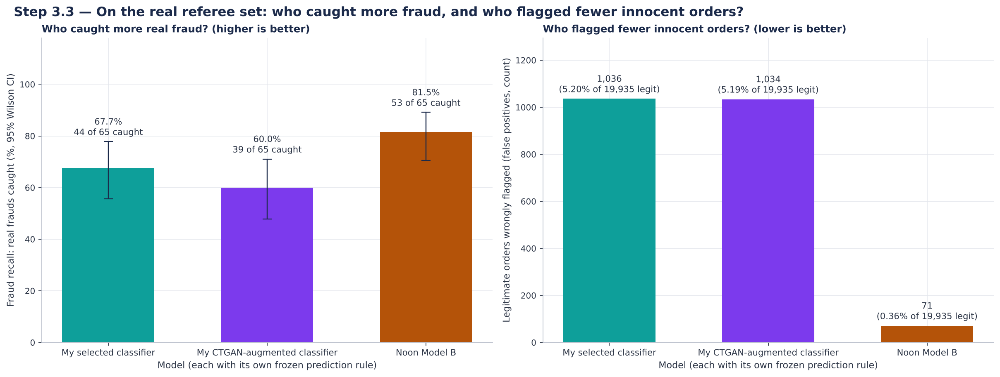

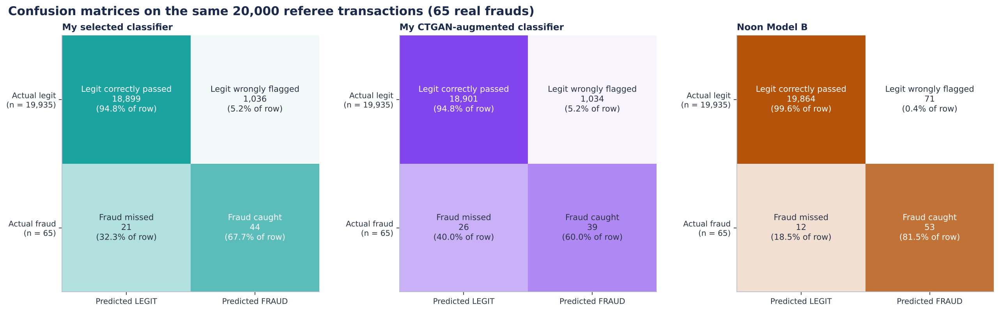

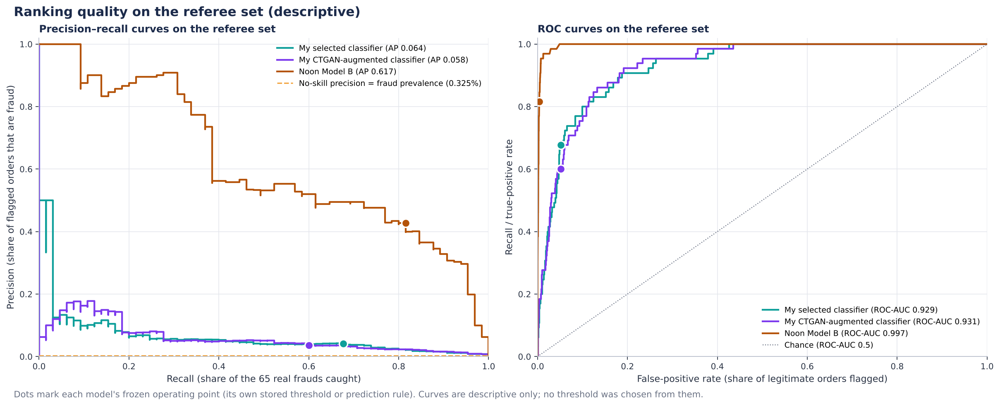

,answer (computed)
Who detected more fraudulent transactions?,Noon Model B (53 of 65)
Who flagged fewer legitimate transactions?,Noon Model B (71 false positives)
Difference in fraud recall (Noon − my selected),+0.138 (+13.8 percentage points; +9 frauds)
Difference in false positives (Noon − my selected),-965
CTGAN-augmented vs my selected: recall,-0.077 (-5 frauds)
CTGAN-augmented vs my selected: false positives,-2


In [12]:
P.p3_headline(res, COLORS3, P3 / "charts" / "3.3_final_bar_chart_recall_and_false_positives.png",
              "Step 3.3 — On the real referee set: who caught more fraud, and who flagged fewer innocent orders?")
P.p3_confusions(res, COLORS3, P3 / "charts" / "3.1_3.2_confusion_matrices.png",
                f"Confusion matrices on the same {N_REF:,} referee transactions ({N_FRAUD} real frauds)")
points = {n: (res.loc[n, "recall"], res.loc[n, "precision"], res.loc[n, "false-positive rate"]) for n in res.index}
P.p3_pr_roc(y_ref, {NAME_SEL: p_sel, NAME_GAN: p_gan, NAME_NOON: p_noon}, points, COLORS3,
            P3 / "charts" / "3.3_precision_recall_and_roc.png", "Ranking quality on the referee set (descriptive)")

d_rec = res.loc[NAME_NOON, "recall"] - res.loc[NAME_SEL, "recall"]
d_fp = int(res.loc[NAME_NOON, "FP"] - res.loc[NAME_SEL, "FP"])
answers = pd.Series({
    "Who detected more fraudulent transactions?": f"{res['TP'].idxmax()} ({int(res['TP'].max())} of {N_FRAUD})",
    "Who flagged fewer legitimate transactions?": f"{res['FP'].idxmin()} ({int(res['FP'].min()):,} false positives)",
    "Difference in fraud recall (Noon − my selected)": f"{d_rec:+.3f} ({d_rec * 100:+.1f} percentage points; {int(res.loc[NAME_NOON, 'TP'] - res.loc[NAME_SEL, 'TP']):+d} frauds)",
    "Difference in false positives (Noon − my selected)": f"{d_fp:+,}",
    "CTGAN-augmented vs my selected: recall": f"{res.loc[NAME_GAN, 'recall'] - res.loc[NAME_SEL, 'recall']:+.3f} ({int(res.loc[NAME_GAN, 'TP'] - res.loc[NAME_SEL, 'TP']):+d} frauds)",
    "CTGAN-augmented vs my selected: false positives": f"{int(res.loc[NAME_GAN, 'FP'] - res.loc[NAME_SEL, 'FP']):+,}",
})
display(answers.to_frame("answer (computed)"))
answers.to_csv(P3 / "metrics" / "C3_step_3_3_answers.csv")

### C4 Uncertainty and paired comparisons (supplementary)

* Only 65 frauds exist, so one detection moves recall by 1.5 percentage points.
* Recall and precision intervals are **95% Wilson** intervals. AP and ROC-AUC intervals come from a class-stratified bootstrap (2,000 resamples).
* Paired comparisons use the same rows for both models:
  * an exact McNemar test on discordant decisions, run separately for fraud rows and legitimate rows;
  * a paired, class-stratified bootstrap of the differences.
* These intervals describe finite-sample uncertainty **within this referee set** only. They do not cover differences between this set and Noon's full transaction population, and they do not replace the required metrics.

In [13]:
ci = res[["recall", "recall 95% CI low", "recall 95% CI high", "precision", "precision 95% CI low", "precision 95% CI high",
          "average precision (PR-AUC)", "AP 95% CI low", "AP 95% CI high", "ROC-AUC", "ROC-AUC 95% CI low", "ROC-AUC 95% CI high"]]
display(ci.T)
ci.to_csv(P3 / "metrics" / "C4_confidence_intervals.csv")
paired = []
for a_name, a_pred, b_name, b_pred in ((NAME_SEL, pred_sel, NAME_NOON, pred_noon), (NAME_SEL, pred_sel, NAME_GAN, pred_gan)):
    mc = R.mcnemar(y_ref, a_pred, b_pred); mc.insert(0, "A vs B", f"A = {a_name} · B = {b_name}")
    pb = R.paired_bootstrap(y_ref, a_pred, b_pred, B_BOOT, SEED); pb.insert(0, "A vs B", f"A = {a_name} · B = {b_name}")
    display(mc); display(pb)
    paired.append((mc, pb))
pd.concat([m for m, _ in paired]).to_csv(P3 / "metrics" / "C4_mcnemar_exact.csv", index=False)
pd.concat([b for _, b in paired]).to_csv(P3 / "metrics" / "C4_paired_bootstrap_differences.csv", index=False)

model,My selected classifier,My CTGAN-augmented classifier,Noon Model B
recall,0.6769,0.6000,0.8154
recall 95% CI low,0.5561,0.4786,0.7045
recall 95% CI high,0.7780,0.7103,0.8911
precision,0.0407,0.0363,0.4274
precision 95% CI low,0.0305,0.0267,0.3438
precision 95% CI high,0.0543,0.0493,0.5154
average precision (PR-AUC),0.0639,0.0583,0.6169
AP 95% CI low,0.0363,0.0369,0.5107
AP 95% CI high,0.1264,0.1023,0.7254
ROC-AUC,0.9286,0.9309,0.9970


,A vs B,rows,flagged by both,flagged only by A,flagged only by B,exact McNemar p
0,A = My selected classifier · B = Noon Model B,fraud rows (detections),38,6,15,0.0784
1,A = My selected classifier · B = Noon Model B,legitimate rows (false alarms),39,997,32,0.0000


,A vs B,metric,difference (B − A),95% CI low,95% CI high
0,A = My selected classifier · B = Noon Model B,recall,0.1385,0.0000,0.2769
1,A = My selected classifier · B = Noon Model B,precision,0.3867,0.3269,0.4553
2,A = My selected classifier · B = Noon Model B,F1,0.4840,0.4167,0.5527
3,A = My selected classifier · B = Noon Model B,FP,-965.0000,"-1,029.0000",-906.9750


,A vs B,rows,flagged by both,flagged only by A,flagged only by B,exact McNemar p
0,A = My selected classifier · B = My CTGAN-augmented classifier,fraud rows (detections),39,5,0,0.0625
1,A = My selected classifier · B = My CTGAN-augmented classifier,legitimate rows (false alarms),881,155,153,0.9546


,A vs B,metric,difference (B − A),95% CI low,95% CI high
0,A = My selected classifier · B = My CTGAN-augmented classifier,recall,-0.0769,-0.1385,-0.0154
1,A = My selected classifier · B = My CTGAN-augmented classifier,precision,-0.0044,-0.0087,-0.0008
2,A = My selected classifier · B = My CTGAN-augmented classifier,F1,-0.0083,-0.0164,-0.0016
3,A = My selected classifier · B = My CTGAN-augmented classifier,FP,-2.0000,-36.0000,32.0250


## D. Step 3.4 — Explaining the gap (descriptive evidence only)

Everything in this section is **post-hoc and descriptive**. The referee labels are used to describe what kind of fraud each model caught or missed. No finding is fed back into any model, threshold or choice.

### D1 Generalisation: Phase 1 synthetic test vs the real referee set

In [14]:
tm = p1["test_metrics"]
gen = pd.DataFrame([{
    "model": n, "dataset": ds, "fraud prevalence": prev, "recall": rec, "precision": pre, "false-positive rate": fpr,
    "ROC-AUC": auc, "average precision": ap} for n, arm in ((NAME_SEL, "A_baseline"), (NAME_GAN, "B_ctgan"))
    for ds, prev, rec, pre, fpr, auc, ap in (
        ("Phase 1 synthetic test (7,500 rows)", tm[arm]["n_fraud"] / tm[arm]["n"], tm[arm]["recall"], tm[arm]["precision"], tm[arm]["fpr"], tm[arm]["roc_auc"], tm[arm]["pr_auc_ap"]),
        (f"Real referee set ({N_REF:,} rows)", N_FRAUD / N_REF, res.loc[n, "recall"], res.loc[n, "precision"], res.loc[n, "false-positive rate"], res.loc[n, "ROC-AUC"], res.loc[n, "average precision (PR-AUC)"]))])
# Precision expected on the referee set if the synthetic-test recall and FPR had held (prevalence effect only)
for n, arm in ((NAME_SEL, "A_baseline"), (NAME_GAN, "B_ctgan")):
    r_, f_, pi = tm[arm]["recall"], tm[arm]["fpr"], N_FRAUD / N_REF
    gen.loc[(gen.model == n) & gen.dataset.str.startswith("Real"), "precision expected from prevalence alone"] = r_ * pi / (r_ * pi + f_ * (1 - pi))
display(gen)
gen.to_csv(P3 / "gap_analysis" / "D1_synthetic_test_vs_referee.csv", index=False)

,model,dataset,fraud prevalence,recall,precision,false-positive rate,ROC-AUC,average precision,precision expected from prevalence alone
0,My selected classifier,"Phase 1 synthetic test (7,500 rows)",0.0303,0.5110,0.5446,0.0133,0.9376,0.5165,NaN
1,My selected classifier,"Real referee set (20,000 rows)",0.0032,0.6769,0.0407,0.0520,0.9286,0.0639,0.1111
2,My CTGAN-augmented classifier,"Phase 1 synthetic test (7,500 rows)",0.0303,0.4890,0.5781,0.0111,0.9367,0.5100,NaN
3,My CTGAN-augmented classifier,"Real referee set (20,000 rows)",0.0032,0.6000,0.0363,0.0519,0.9309,0.0583,0.1252


### D2 What does real fraud look like? Real referee fraud compared with the three fraud sources

This comparison shows which generator's picture of fraud the real fraud resembles. It uses the same type-appropriate effect sizes as Phase 2 (KS D for continuous and integer features; TVD for hour and categorical features). It is descriptive: with only 65 real frauds, small differences are noisy.

,Real referee fraud,My seed fraud (training),My CTGAN fraud,Noon synthetic fraud (unique rows)
orders placed 00:00–05:59,47.7,14.2,11.9,60.1
location_mismatch = 1,60.0,24.6,23.4,62.9
device_change = 1,70.8,20.1,31.9,65.6
account age ≤ 7 days,6.2,45.7,35.6,3.0
account age > 180 days,33.8,33.0,43.2,43.9
discount_applied = 1,40.0,50.8,50.3,43.0
≥ 1 previous refund,43.1,28.5,36.4,44.6
≥ 4 orders in last 7 days,41.5,21.6,30.2,50.4
paid cash on delivery,21.5,11.8,9.5,16.8
rows (n),65.0,1058.0,2116.0,1033.0


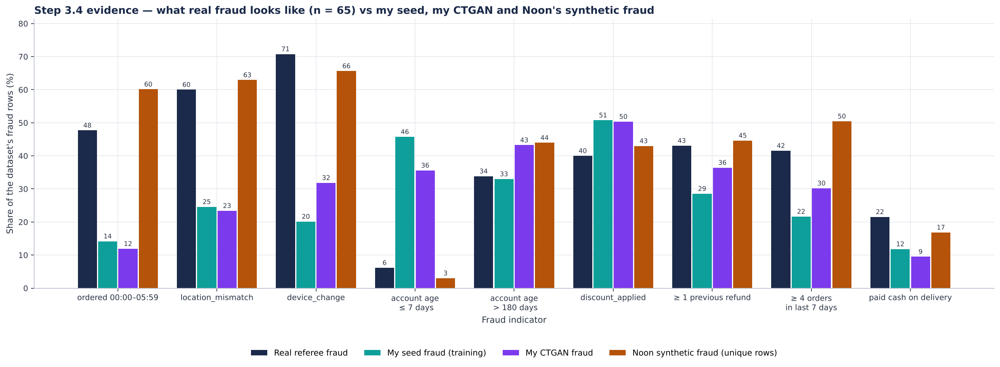

pair,Real referee fraud vs My CTGAN fraud,Real referee fraud vs My seed fraud (training),Real referee fraud vs Noon synthetic fraud (unique rows),noise floor: 65 rows vs their own source (mean of 200 draws)
feature,,,,
account_age_days,0.324,0.429,0.160,0.101
delivery_distance_km,0.296,0.214,0.141,0.100
device_change,0.389,0.506,0.051,0.042
discount_applied,0.103,0.108,0.030,0.046
hour_of_day,0.512,0.489,0.316,0.214
location_mismatch,0.366,0.354,0.029,0.044
num_orders_last_7d,0.190,0.303,0.107,0.076
order_amount,0.161,0.218,0.061,0.103
payment_method,0.242,0.199,0.047,0.077


,Real referee legitimate,My seed legitimate (training)
orders placed 00:00–05:59,24.5,8.9
location_mismatch = 1,4.9,11.5
device_change = 1,8.0,3.3
account age ≤ 7 days,0.1,4.6
account age > 180 days,61.7,77.9
discount_applied = 1,34.6,35.5
≥ 1 previous refund,26.5,14.3
≥ 4 orders in last 7 days,35.6,10.6
paid cash on delivery,15.3,14.9
rows (n),19935.0,33942.0


,feature,headline effect,effect size,magnitude (judgement band),median A,median B,mean A,mean B
0,order_amount,KS D,0.1826,moderate,84.9000,63.2350,99.6693,77.1436
1,account_age_days,KS D,0.2926,moderate,225.0000,384.5000,263.7114,545.6725
2,hour_of_day,TVD (24 hours),0.2878,moderate,NaN,NaN,11.5828,14.9883
3,num_orders_last_7d,KS D,0.4366,large,3.0000,1.0000,3.0143,1.4947
4,delivery_distance_km,KS D,0.1754,moderate,4.2000,3.1600,5.0337,3.6605
5,prev_refunds,KS D,0.1224,small,0.0000,0.0000,0.3049,0.1742
6,payment_method,TVD,0.2303,moderate,NaN,NaN,NaN,NaN
7,discount_applied,TVD,0.0091,negligible,NaN,NaN,0.3462,0.3553
8,device_change,TVD,0.0469,negligible,NaN,NaN,0.0804,0.0334
9,location_mismatch,TVD,0.0663,small,NaN,NaN,0.0490,0.1153


In [15]:
ref_fraud = referee[referee[TARGET] == 1]
ref_legit = referee[referee[TARGET] == 0]
seed_fraud = train[train[TARGET] == 1]
seed_legit = train[train[TARGET] == 0]
my_ctgan = pd.read_csv(DATA / "synthetic_fraud_gan.csv")
noon_u = noon_syn.drop_duplicates(FEATURES)
srcs = {"Real referee fraud": ref_fraud, "My seed fraud (training)": seed_fraud, "My CTGAN fraud": my_ctgan, "Noon synthetic fraud (unique rows)": noon_u}

def indicators(d):
    return {"orders placed 00:00–05:59": d.hour_of_day.between(0, 5).mean() * 100,
            "location_mismatch = 1": d.location_mismatch.mean() * 100,
            "device_change = 1": d.device_change.mean() * 100,
            "account age ≤ 7 days": (d.account_age_days <= 7).mean() * 100,
            "account age > 180 days": (d.account_age_days > 180).mean() * 100,
            "discount_applied = 1": d.discount_applied.mean() * 100,
            "≥ 1 previous refund": (d.prev_refunds >= 1).mean() * 100,
            "≥ 4 orders in last 7 days": (d.num_orders_last_7d >= 4).mean() * 100,
            "paid cash on delivery": (d.payment_method == "cod").mean() * 100}
prof_tab = pd.DataFrame({k: indicators(v) for k, v in srcs.items()})
prof_tab.loc["rows (n)"] = [len(v) for v in srcs.values()]
display(prof_tab.style.format("{:.1f}"))
prof_tab.to_csv(P3 / "gap_analysis" / "D2_fraud_indicator_profiles.csv")
P.p3_fraud_profiles(prof_tab.drop(index="rows (n)").rename(index=lambda s: s.replace(" = 1", "").replace(" in last", "\nin last").replace("ordered ", "").replace("orders placed", "ordered").replace("account age", "account age\n")),
                    {"Real referee fraud": NAVY, "My seed fraud (training)": SEED_FRAUD_COLOR, "My CTGAN fraud": MY_GAN_COLOR, "Noon synthetic fraud (unique rows)": NOON_COLOR},
                    P3 / "charts" / "3.4_real_fraud_vs_generators_profiles.png",
                    f"Step 3.4 evidence — what real fraud looks like (n = {len(ref_fraud)}) vs my seed, my CTGAN and Noon's synthetic fraud")

eff_rows = []
for name in ["My seed fraud (training)", "My CTGAN fraud", "Noon synthetic fraud (unique rows)"]:
    e = C.compare_features(ref_fraud, srcs[name], "Real referee fraud", name, n_perm=0, seed=SEED)
    e["pair"] = f"Real referee fraud vs {name}"
    eff_rows.append(e[["pair", "feature", "headline effect", "effect size", "magnitude (judgement band)"]])
eff_real = pd.concat(eff_rows, ignore_index=True)
eff_wide = eff_real.pivot(index="feature", columns="pair", values="effect size")
# Sampling-noise floor: the distance expected between 65 rows and the source they were drawn from (same distribution),
# so that effect sizes measured on only 65 real frauds are not over-read. 200 random draws from Noon's unique rows.
rng_floor = np.random.default_rng(SEED)
floor = pd.concat([C.compare_features(noon_u.iloc[rng_floor.choice(len(noon_u), len(ref_fraud), replace=False)], noon_u, "draw", "src",
                                      n_perm=0, seed=SEED).set_index("feature")["effect size"] for _ in range(200)], axis=1).mean(axis=1)
eff_wide["noise floor: 65 rows vs their own source (mean of 200 draws)"] = floor
eff_wide.loc["mean over 10 features"] = eff_wide.mean()
display(eff_wide.style.format("{:.3f}").set_caption("Distance from real referee fraud (0 = identical; lower = closer to real fraud)"))
eff_real.to_csv(P3 / "gap_analysis" / "D2_effect_sizes_real_fraud_vs_sources.csv", index=False)
eff_wide.to_csv(P3 / "gap_analysis" / "D2_effect_sizes_wide.csv")

legit_ind = pd.DataFrame({"Real referee legitimate": indicators(ref_legit), "My seed legitimate (training)": indicators(seed_legit)})
legit_ind.loc["rows (n)"] = [len(ref_legit), len(seed_legit)]
display(legit_ind.style.format("{:.1f}").set_caption("Legitimate behaviour: real vs what my seed assumed"))
legit_ind.to_csv(P3 / "gap_analysis" / "D2_legit_indicator_profiles.csv")
legit_cmp = C.compare_features(ref_legit, seed_legit, "Real referee legitimate", "My seed legitimate (training)", n_perm=0, seed=SEED)
display(legit_cmp[["feature", "headline effect", "effect size", "magnitude (judgement band)", "median A", "median B", "mean A", "mean B"]])
legit_cmp.to_csv(P3 / "gap_analysis" / "D2_real_legit_vs_my_seed_legit.csv", index=False)

### D3 Which real frauds did each model catch?

,Caught by both,Caught only by my selected classifier,Caught only by Noon Model B,Missed by both
0,38,6,15,6


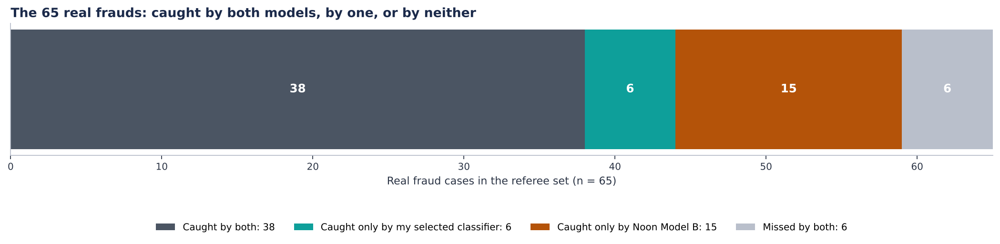

,Caught by my selected classifier,Missed by my selected classifier,Caught by Noon Model B,Missed by Noon Model B
orders placed 00:00–05:59,36.4,71.4,50.9,33.3
location_mismatch = 1,65.9,47.6,62.3,50.0
device_change = 1,77.3,57.1,75.5,50.0
account age ≤ 7 days,9.1,0.0,7.5,0.0
account age > 180 days,31.8,38.1,37.7,16.7
discount_applied = 1,38.6,42.9,43.4,25.0
≥ 1 previous refund,56.8,14.3,43.4,41.7
≥ 4 orders in last 7 days,43.2,38.1,37.7,58.3
paid cash on delivery,18.2,28.6,26.4,0.0
rows (n),44.0,21.0,53.0,12.0


,False positives of my selected classifier,False positives of Noon Model B,All real legitimate orders
orders placed 00:00–05:59,29.3,45.1,24.5
location_mismatch = 1,8.3,62.0,4.9
device_change = 1,43.1,60.6,8.0
account age ≤ 7 days,1.1,4.2,0.1
account age > 180 days,36.3,46.5,61.7
discount_applied = 1,29.2,40.8,34.6
≥ 1 previous refund,66.9,47.9,26.5
≥ 4 orders in last 7 days,54.1,47.9,35.6
paid cash on delivery,12.3,18.3,15.3
rows (n),1036.0,71.0,19935.0


In [16]:
f = y_ref == 1
ov = pd.DataFrame([{"Caught by both": int(((pred_sel == 1) & (pred_noon == 1) & f).sum()),
                    "Caught only by my selected classifier": int(((pred_sel == 1) & (pred_noon == 0) & f).sum()),
                    "Caught only by Noon Model B": int(((pred_sel == 0) & (pred_noon == 1) & f).sum()),
                    "Missed by both": int(((pred_sel == 0) & (pred_noon == 0) & f).sum())}])
display(ov)
ov.to_csv(P3 / "gap_analysis" / "D3_fraud_detection_overlap.csv", index=False)
P.p3_detection_overlap(ov, ["#4B5563", COLORS3[NAME_SEL], COLORS3[NAME_NOON], "#B9BFCB"],
                       P3 / "charts" / "3.4_fraud_detection_overlap.png",
                       f"The {N_FRAUD} real frauds: caught by both models, by one, or by neither")
grp = {"Caught by my selected classifier": ref_fraud[pred_sel[f] == 1], "Missed by my selected classifier": ref_fraud[pred_sel[f] == 0],
       "Caught by Noon Model B": ref_fraud[pred_noon[f] == 1], "Missed by Noon Model B": ref_fraud[pred_noon[f] == 0]}
cm_tab = pd.DataFrame({k: indicators(v) for k, v in grp.items()})
cm_tab.loc["rows (n)"] = [len(v) for v in grp.values()]
display(cm_tab.style.format("{:.1f}"))
cm_tab.to_csv(P3 / "gap_analysis" / "D3_caught_vs_missed_profiles.csv")
fp_tab = pd.DataFrame({"False positives of my selected classifier": indicators(ref_legit[pred_sel[~f] == 1]),
                       "False positives of Noon Model B": indicators(ref_legit[pred_noon[~f] == 1]),
                       "All real legitimate orders": indicators(ref_legit)})
fp_tab.loc["rows (n)"] = [int(pred_sel[~f].sum()), int(pred_noon[~f].sum()), len(ref_legit)]
display(fp_tab.style.format("{:.1f}"))
fp_tab.to_csv(P3 / "gap_analysis" / "D3_false_positive_profiles.csv")

### Step 3.4 — Why does Noon perform differently?

*Every number below comes from tables C1–D3. **Observed** = computed; **Interpretation** = my reading, which these data cannot prove.*

**1–2. Who catches more real fraud, and who flags fewer innocent orders?**
* *Observed.* Noon Model B catches **53 of 65** real frauds (recall 0.815). My selected classifier catches **44 of 65** (0.677). The difference is **+0.138**, or 9 more frauds for Noon.
* *Observed.* Noon flags **71** legitimate orders; mine flags **1,036**, so Noon raises **965 fewer** false alarms. Noon's precision is 0.427 vs 0.041, and its F1 0.561 vs 0.077.
* *Observed — how certain is this?*
  * **False positives:** clear-cut. Of the legitimate orders only one model flagged, 997 were flagged by mine alone and 32 by Noon's alone (exact McNemar p < 0.001).
  * **Recall:** less certain with only 65 frauds. 15 frauds were caught only by Noon and 6 only by mine (exact McNemar p = 0.078). The paired bootstrap 95% interval for Noon's recall advantage runs from 0.000 to 0.277. Noon is ahead on recall, but this referee set cannot pin down by how much.

**3. Did my CTGAN augmentation help on real data?**
* *Observed.* No. The CTGAN-augmented classifier catches **39 of 65** (recall 0.600), **5 fewer** than my selected classifier. Its false positives are essentially the same (1,034 vs 1,036). All 5 discordant frauds go against the GAN model. Exact McNemar p = 0.0625, which is the smallest p-value possible with 5 discordant pairs; the paired bootstrap interval for the recall difference runs from −0.138 to −0.015.
* *Interpretation.* This matches Phase 1, where the pre-declared rule found no measurable improvement from CTGAN and selected the baseline. Phase 2 also showed why my GAN could not have helped much: it learned my own assumptions, and real fraud is far from them (point 5). A GAN can only re-sample the picture of fraud it was trained on.

**4. Is this consistent with Phase 2?**
* *Observed.* Yes. Phase 2 found that my fraud and Noon's differ most on night ordering, location mismatch, device change and account age. Real referee fraud sits on **Noon's side** of every one of these:

| Indicator (share of fraud rows) | Real referee fraud | My seed fraud | My CTGAN fraud | Noon synthetic fraud |
|---|---|---|---|---|
| Ordered 00:00–05:59 | 47.7% | 14.2% | 11.9% | 60.1% |
| Location mismatch | 60.0% | 24.6% | 23.4% | 62.9% |
| Device change | 70.8% | 20.1% | 31.9% | 65.6% |
| Account ≤ 7 days old | 6.2% | 45.7% | 35.6% | 3.0% |

* *Observed.* Averaged over the 10 features, real fraud is **0.099** away from Noon's synthetic fraud. That is close to the **0.086** distance expected between 65 rows and their own source from sampling noise alone. Real fraud is **0.297** away from my seed fraud and **0.271** from my CTGAN fraud.
* *Interpretation.* Noon's generator learned a picture of fraud close to the real one: established accounts, night-time orders, new device, mismatched location. My Phase 1 assumptions put most weight on brand-new-account promo abuse, which barely appears in the real fraud (6.2% of real frauds are ≤ 7 days old).

**5. Why might Noon's GAN have learned what my seed data lacked?**
* *[SOURCE FACT]* `B_NOON_benchmark.md` says Noon's GAN was trained on Noon's **real** fraud examples, and Model B was trained on real data plus that GAN fraud. My models never saw a single real row. My seed data was built from public research and my own assumptions (Phase 1 register).
* *Observed — the fraud side.* My classifier misses exactly the fraud my assumptions under-weighted:
  * **Night orders:** 71.4% of the 21 frauds it missed were placed 00:00–05:59, vs 36.4% of those it caught. In Phase 1 I made night ordering a deliberately weak signal (H6).
  * **Refunds:** 56.8% of the frauds it caught had a previous refund, vs 14.3% of those it missed. It leans heavily on refund history.
* *Observed — the legitimate side.* This is the larger problem: real legitimate customers behave differently from my synthetic ones.

| Indicator (share of legitimate rows) | Real referee legitimate | My seed legitimate |
|---|---|---|
| Ordered 00:00–05:59 | 24.5% | 8.9% |
| ≥ 1 previous refund | 26.5% | 14.3% |
| Device change | 8.0% | 3.3% |
| ≥ 4 orders in last 7 days | 35.6% | 10.6% |

* *Observed.* My classifier treats these behaviours as risky. Its 1,036 false positives are concentrated in them: 66.9% have a previous refund, 43.1% a device change and 54.1% at least 4 recent orders, against 26.5%, 8.0% and 35.6% of all real legitimate orders.
* *Observed — prevalence.* Its false-positive rate rose from 1.33% on my synthetic test set to **5.20%** on the real set. If only the fraud rate had changed (3% synthetic to 0.325% real) and recall and false-positive rate had held, precision would have fallen to about **11.1%** from base rates alone. The actual precision of 4.1% shows that real legitimate behaviour, not just rarity, is driving the false alarms.
* *Interpretation.* The gap therefore has two sides. Noon's model learned what real fraud looks like **and** what real legitimate customers look like; mine learned both from assumptions.

**6. Is it all down to the GAN? No — other differences matter and cannot be separated here.**
* **Training data:** Noon's includes real transactions; mine has none.
* **Model family:** Noon uses a random forest (200 trees, balanced class weights); mine is gradient boosting with Platt calibration.
* **Decision rules:** Noon uses majority vote; mine uses a threshold of 0.297 on calibrated probabilities, tuned for a 3%-fraud synthetic world.
* **Class composition** of training data also differs.

Separating these effects would need retraining, which Phase 3 forbids. Noon's own Model A (real data only, no GAN) reportedly reached recall of only 0.14, which suggests real data **plus** realistic synthetic fraud is what worked for Noon. I could not re-score Model A, because it was not supplied.

Ranking quality is a separate point. My model still ranks real fraud well above chance (ROC-AUC 0.929 vs Noon's 0.997). But at a 0.325% fraud rate, its average precision (0.064 vs 0.617) shows that too many legitimate orders score as high as real fraud.

**7. What limits these conclusions?**
* **Sample size:** there are only 65 real frauds. Recall intervals are wide (mine: 0.556–0.778; Noon: 0.704–0.891, 95% Wilson).
* **One referee sample:** it may not represent Noon's full or future transaction population; for example, the fraud rate in production may differ from 0.325%.
* **Unknown Noon training data:** its timing and overlap with the referee period are unknown. Noon's model may have an in-distribution advantage that a production deployment would not keep. I found no exact referee rows in Noon's synthetic file (0 overlaps), but I cannot check Noon's real training data.
* **Descriptive analysis only:** sections D2–D3 use the referee labels after the fact. They explain the gap; they were not used to change anything, and with 65 frauds some differences are noise.
* **Limits of the benchmark:** Noon's synthetic sample (Phase 2) is a benchmark, not ground truth. The referee results are the real evidence, but they judge **these** models on **this** sample.

## E. Quality control (Part 9 checklist, automated)

In [17]:
audit = []
def chk(name, ok, detail=""):
    audit.append({"check": name, "result": "Passed" if ok else "FAILED", "detail": detail})

chk("All three intended models identified (selected = A_baseline per Phase 1; secondary = B_ctgan; Noon = RandomForest)",
    sel.metadata["arm"] == p1["final_arm"] == "A_baseline" and gan.metadata["arm"] == "B_ctgan" and type(rf).__name__ == "RandomForestClassifier")
chk("Selected model not confused with the CTGAN candidate (different arm, threshold and file hash)",
    sel.metadata["arm"] != gan.metadata["arm"] and sel.threshold != gan.threshold and MODEL_HASHES_BEFORE["models/fraud_model.joblib"] != MODEL_HASHES_BEFORE["models/fraud_model_gan_augmented.joblib"])
chk("Baseline file is the same fitted artefact as the selected model (not reported twice)", baseline_identical and same_as_selected)
hashes_after = {n: C.sha256(p) for n, p, _, _ in inputs if n.endswith(".joblib")}
chk("No model retrained or modified (all four model files hash-identical before and after scoring, and to their records)",
    hashes_after == MODEL_HASHES_BEFORE and bool(inv.loc[inv.input.str.endswith(".joblib"), "matches recorded hash"].all()))
chk("All models scored on the same 20,000 referee rows", all(len(a) == N_REF for a in (pred_sel, pred_gan, pred_noon)) and N_REF == 20000)
chk("All 65 fraud cases included for every model", bool((res["n fraud"] == N_FRAUD).all()) and N_FRAUD == 65 and bool(((res.TP + res.FN) == N_FRAUD).all()))
chk("Original schema preserved; Noon payment-method encoding matches its stored columns",
    list(referee.columns) == list(SCHEMA) and bool(noon_meta["helper encoding == stored columns (names + order)"])
    and bool(noon_meta["every referee row has exactly one payment_method column = 1"]))
chk("Each model's frozen prediction rule applied (stored thresholds; Noon's native predict)",
    np.array_equal(pred_sel, (p_sel >= sel.threshold).astype(int)) and np.array_equal(pred_gan, (p_gan >= gan.threshold).astype(int))
    and sel.threshold == p1["final_threshold_calibrated"] and np.array_equal(pred_noon, rf.predict(X_noon)))
src_text = (ROOT / "notebooks" / "phase3_evaluation.py").read_text()
chk("Referee labels kept out of every model input (X_ref has no is_fraud; no fit/calibrate call in Phase 3 code)",
    TARGET not in X_ref.columns and not any(t in src_text for t in ["." + "fit(", "fit_" + "transform(", "Calibrated" + "ClassifierCV", "threshold" + "_sweep(", "cost_optimal" + "_threshold("]))
chk("Noon benchmark reproduction checked (all published figures)", bool(repro["match"].all()), f"{int(repro['match'].sum())}/{len(repro)} match")
chk("Helper score_on_referee agrees with the independent recomputation", bool(helper_vs_mine.all()))
chk("Noon predictions identical under scikit-learn 1.8.0 (isolated env) and 1.9.1",
    bool(crossver.get("predictions identical (1.8.0 vs 1.9.1)", False)), str(crossver.get("max |probability difference|", "not tested")))
chk("Confusion matrices reconcile with dataset size (TP+FP+FN+TN = 20,000)", bool(((res.TP + res.FP + res.FN + res.TN) == N_REF).all()))
chk("Recall, precision and F1 independently verified with scikit-learn", bool(check["all match"].all()))
reload_ok = all(np.array_equal(joblib.load(ROOT / "models" / fn).predict(X_ref), pr) for fn, pr in (("fraud_model.joblib", pred_sel), ("fraud_model_gan_augmented.joblib", pred_gan)))
chk("Predictions reproduce from freshly reloaded model files", reload_ok)
chk("Saved prediction file reproduces the reported confusion matrices",
    all(np.array_equal(pd.read_csv(P3 / "predictions" / "B1_referee_predictions_all_models.csv")[c].to_numpy(), v) for c, v in (("selected_pred", pred_sel), ("ctgan_pred", pred_gan), ("noon_pred", pred_noon))))
p1_ok = R.cells_digest(nb_path, None) == p1_manifest["phase1_notebook_cells_sha256"] and bool(R.verify_files({k: v for k, v in p1_files.items() if k.startswith(("data/", "models/"))}, ROOT)["unchanged"].all())
p2_ok = R.cells_digest(nb_path, 2) == p2_freeze["phase2_notebook_cells_sha256"] and bool(R.verify_files(p2_freeze["files"], ROOT)["unchanged"].all())
chk("Phase 1 and Phase 2 outputs unchanged (cells, data, models, Phase 2 outputs and reports)", p1_ok and p2_ok)
chk("Professor files unchanged; no __pycache__ in the professor folder",
    bool(R.verify_files({f"professor_supplied/{k}": v for k, v in prof_recorded.items()}, ROOT)["unchanged"].all()) and not (PROF / "__pycache__").exists())
chk("All charts written", all((P3 / "charts" / f).exists() for f in ["3.3_final_bar_chart_recall_and_false_positives.png", "3.1_3.2_confusion_matrices.png",
    "3.3_precision_recall_and_roc.png", "3.4_real_fraud_vs_generators_profiles.png", "3.4_fraud_detection_overlap.png"]))
markers = ["STEP_3_4_" + "EXPLANATION", "PHASE_3_" + "SUMMARY", "TO" + "DO"]
chk("No unfilled placeholder text in the Phase 3 section", not any(m in src_text for m in markers))
r_ = res
pct = lambda x: f"{100 * x:.1f}%"
QUOTED = {
    "sel recall 0.677": f"sel recall {r_.loc[NAME_SEL, 'recall']:.3f}", "gan recall 0.600": f"gan recall {r_.loc[NAME_GAN, 'recall']:.3f}",
    "noon recall 0.815": f"noon recall {r_.loc[NAME_NOON, 'recall']:.3f}", "sel prec 0.041": f"sel prec {r_.loc[NAME_SEL, 'precision']:.3f}",
    "gan prec 0.036": f"gan prec {r_.loc[NAME_GAN, 'precision']:.3f}", "noon prec 0.427": f"noon prec {r_.loc[NAME_NOON, 'precision']:.3f}",
    "sel F1 0.077": f"sel F1 {r_.loc[NAME_SEL, 'F1']:.3f}", "gan F1 0.069": f"gan F1 {r_.loc[NAME_GAN, 'F1']:.3f}", "noon F1 0.561": f"noon F1 {r_.loc[NAME_NOON, 'F1']:.3f}",
    "CM sel 44/1036/21/18899": "CM sel {TP}/{FP}/{FN}/{TN}".format(**r_.loc[NAME_SEL, ["TP", "FP", "FN", "TN"]].astype(int).to_dict()),
    "CM gan 39/1034/26/18901": "CM gan {TP}/{FP}/{FN}/{TN}".format(**r_.loc[NAME_GAN, ["TP", "FP", "FN", "TN"]].astype(int).to_dict()),
    "CM noon 53/71/12/19864": "CM noon {TP}/{FP}/{FN}/{TN}".format(**r_.loc[NAME_NOON, ["TP", "FP", "FN", "TN"]].astype(int).to_dict()),
    "diff recall +0.138": f"diff recall {r_.loc[NAME_NOON, 'recall'] - r_.loc[NAME_SEL, 'recall']:+.3f}",
    "fewer FP 965": f"fewer FP {int(r_.loc[NAME_SEL, 'FP'] - r_.loc[NAME_NOON, 'FP'])}",
    "mcnemar legit 997/32": f"mcnemar legit {int(paired[0][0].iloc[1]['flagged only by A'])}/{int(paired[0][0].iloc[1]['flagged only by B'])}",
    "mcnemar fraud 6/15 p 0.078": f"mcnemar fraud {int(paired[0][0].iloc[0]['flagged only by A'])}/{int(paired[0][0].iloc[0]['flagged only by B'])} p {paired[0][0].iloc[0]['exact McNemar p']:.3f}",
    "boot recall 0.000–0.277": f"boot recall {paired[0][1].set_index('metric').loc['recall', '95% CI low']:.3f}–{paired[0][1].set_index('metric').loc['recall', '95% CI high']:.3f}",
    "gan mcnemar 5/0 p 0.0625": f"gan mcnemar {int(paired[1][0].iloc[0]['flagged only by A'])}/{int(paired[1][0].iloc[0]['flagged only by B'])} p {paired[1][0].iloc[0]['exact McNemar p']:.4f}",
    "gan boot −0.138 to −0.015": "gan boot {:.3f} to {:.3f}".format(*paired[1][1].set_index("metric").loc["recall", ["95% CI low", "95% CI high"]]).replace("-", "−"),
    "dist noon 0.099 floor 0.086 seed 0.297 ctgan 0.271": "dist noon {:.3f} floor {:.3f} seed {:.3f} ctgan {:.3f}".format(
        eff_wide.loc["mean over 10 features", "Real referee fraud vs Noon synthetic fraud (unique rows)"], eff_wide.loc["mean over 10 features", "noise floor: 65 rows vs their own source (mean of 200 draws)"],
        eff_wide.loc["mean over 10 features", "Real referee fraud vs My seed fraud (training)"], eff_wide.loc["mean over 10 features", "Real referee fraud vs My CTGAN fraud"]),
    "real fraud 47.7/60.0/70.8/6.2": "real fraud {:.1f}/{:.1f}/{:.1f}/{:.1f}".format(*prof_tab.loc[["orders placed 00:00–05:59", "location_mismatch = 1", "device_change = 1", "account age ≤ 7 days"], "Real referee fraud"]),
    "seed fraud 14.2/24.6/20.1/45.7": "seed fraud {:.1f}/{:.1f}/{:.1f}/{:.1f}".format(*prof_tab.loc[["orders placed 00:00–05:59", "location_mismatch = 1", "device_change = 1", "account age ≤ 7 days"], "My seed fraud (training)"]),
    "ctgan fraud 11.9/23.4/31.9/35.6": "ctgan fraud {:.1f}/{:.1f}/{:.1f}/{:.1f}".format(*prof_tab.loc[["orders placed 00:00–05:59", "location_mismatch = 1", "device_change = 1", "account age ≤ 7 days"], "My CTGAN fraud"]),
    "noon fraud 60.1/62.9/65.6/3.0": "noon fraud {:.1f}/{:.1f}/{:.1f}/{:.1f}".format(*prof_tab.loc[["orders placed 00:00–05:59", "location_mismatch = 1", "device_change = 1", "account age ≤ 7 days"], "Noon synthetic fraud (unique rows)"]),
    "missed night 71.4 caught 36.4": "missed night {:.1f} caught {:.1f}".format(cm_tab.loc["orders placed 00:00–05:59", "Missed by my selected classifier"], cm_tab.loc["orders placed 00:00–05:59", "Caught by my selected classifier"]),
    "refund caught 56.8 missed 14.3": "refund caught {:.1f} missed {:.1f}".format(cm_tab.loc["≥ 1 previous refund", "Caught by my selected classifier"], cm_tab.loc["≥ 1 previous refund", "Missed by my selected classifier"]),
    "legit real 24.5/26.5/8.0/35.6": "legit real {:.1f}/{:.1f}/{:.1f}/{:.1f}".format(*legit_ind.loc[["orders placed 00:00–05:59", "≥ 1 previous refund", "device_change = 1", "≥ 4 orders in last 7 days"], "Real referee legitimate"]),
    "legit seed 8.9/14.3/3.3/10.6": "legit seed {:.1f}/{:.1f}/{:.1f}/{:.1f}".format(*legit_ind.loc[["orders placed 00:00–05:59", "≥ 1 previous refund", "device_change = 1", "≥ 4 orders in last 7 days"], "My seed legitimate (training)"]),
    "FP sel 66.9/43.1/54.1": "FP sel {:.1f}/{:.1f}/{:.1f}".format(*fp_tab.loc[["≥ 1 previous refund", "device_change = 1", "≥ 4 orders in last 7 days"], "False positives of my selected classifier"]),
    "fpr synth 1.33% real 5.20%": f"fpr synth {100 * tm['A_baseline']['fpr']:.2f}% real {100 * r_.loc[NAME_SEL, 'false-positive rate']:.2f}%",
    "expected precision 11.1%": f"expected precision {100 * gen.loc[(gen.model == NAME_SEL) & gen.dataset.str.startswith('Real'), 'precision expected from prevalence alone'].iloc[0]:.1f}%",
    "auc 0.929 vs 0.997": f"auc {r_.loc[NAME_SEL, 'ROC-AUC']:.3f} vs {r_.loc[NAME_NOON, 'ROC-AUC']:.3f}",
    "ap 0.064 vs 0.617": f"ap {r_.loc[NAME_SEL, 'average precision (PR-AUC)']:.3f} vs {r_.loc[NAME_NOON, 'average precision (PR-AUC)']:.3f}",
    "wilson sel 0.556–0.778 noon 0.704–0.891": "wilson sel {:.3f}–{:.3f} noon {:.3f}–{:.3f}".format(r_.loc[NAME_SEL, "recall 95% CI low"], r_.loc[NAME_SEL, "recall 95% CI high"], r_.loc[NAME_NOON, "recall 95% CI low"], r_.loc[NAME_NOON, "recall 95% CI high"]),
    "overlap 38/6/15/6": "overlap {}/{}/{}/{}".format(*ov.iloc[0].tolist()),
}
bad = {k: v for k, v in QUOTED.items() if k != v}
chk("Numbers quoted in the written explanation equal this run's results", bool(QUOTED) and not bad, str(bad) if bad else f"{len(QUOTED)} values checked")
audit = pd.DataFrame(audit)
display(audit)
audit.to_csv(P3 / "audit" / "E_QC_checks.csv", index=False)
print(f"{int((audit.result == 'Passed').sum())} of {len(audit)} checks passed · Phase 3 runtime {(time.time() - T0) / 60:.1f} min")

,check,result,detail
0,All three intended models identified (selected = A_baseline per Phase 1; secondary = B...,Passed,
1,"Selected model not confused with the CTGAN candidate (different arm, threshold and fil...",Passed,
2,Baseline file is the same fitted artefact as the selected model (not reported twice),Passed,
3,No model retrained or modified (all four model files hash-identical before and after s...,Passed,
4,"All models scored on the same 20,000 referee rows",Passed,
5,All 65 fraud cases included for every model,Passed,
6,Original schema preserved; Noon payment-method encoding matches its stored columns,Passed,
7,Each model's frozen prediction rule applied (stored thresholds; Noon's native predict),Passed,
8,Referee labels kept out of every model input (X_ref has no is_fraud; no fit/calibrate ...,Passed,
9,Noon benchmark reproduction checked (all published figures),Passed,7/7 match


21 of 21 checks passed · Phase 3 runtime 1.4 min


## Phase 3 summary (for the final report)

All three models were scored on the same **20,000** real referee transactions (65 frauds, 0.325%) with their own frozen prediction rules. Nothing was retrained, recalibrated or re-thresholded.

| Model | Recall | Precision | F1 | TP | FP | FN | TN |
|---|---|---|---|---|---|---|---|
| My selected classifier (A, baseline) | 0.677 | 0.041 | 0.077 | 44 | 1,036 | 21 | 18,899 |
| My CTGAN-augmented classifier (B) | 0.600 | 0.036 | 0.069 | 39 | 1,034 | 26 | 18,901 |
| Noon Model B | 0.815 | 0.427 | 0.561 | 53 | 71 | 12 | 19,864 |

* **Benchmark reproduction.** Noon's model reproduces its published figures exactly (confusion matrix 19,864 / 71 / 12 / 53). Its predictions are identical under scikit-learn 1.8.0 in an isolated environment and 1.9.1 in this project, so the version warning is a software notice, not a performance issue.
* **Step 3.3 answers.** Noon catches more fraud (+9 frauds, +13.8 percentage points of recall) **and** flags far fewer innocent orders (71 vs 1,036). My CTGAN augmentation did not carry over to real data: 5 fewer frauds caught, false positives unchanged.
* **Step 3.4 explanation.** Real fraud closely resembles Noon's synthetic fraud (mean distance 0.099, near the 0.086 noise floor) and differs from mine (0.297). It is mainly night-time, new-device, mismatched-location fraud on established accounts. Real legitimate customers also order at night, change devices, claim refunds and order often more than my seed assumed, which drives my 5.2% false-positive rate. Model family, decision rules and Noon's access to real data also differ, and these effects cannot be separated without retraining.
* **Limitations.** 65 frauds (wide intervals: recall 0.556–0.778 for mine and 0.704–0.891 for Noon's); one referee sample; Noon's training data undocumented.

Phase 4 (the app) has not been started.

## F. Phase 3 output inventory (Part 8 deliverables)

In [18]:
DELIVERABLE = {
    "audit/A1_input_inventory.csv": "1 · Verified inventory of the seven Phase 3 inputs (presence, hash, purpose)",
    "audit/A1_freeze_checks_before_scoring.csv": "1 · Phase 1 / Phase 2 / professor-file freeze checks before scoring",
    "audit/A3_my_model_metadata.csv": "1 · Metadata of my saved models (arm, family, thresholds, calibrator, classes)",
    "audit/A3_selection_verification.csv": "1 · Selected-model verification; baseline-file identity check",
    "audit/A3_fraudmodel_interface_checks.csv": "1 · FraudModel interface checks (raw input, calibrated probability, stored threshold)",
    "audit/A4_noon_model_metadata.csv": "1 · Noon Model B metadata, encoding alignment and version warnings",
    "audit/A2_referee_integrity_checks.csv": "2 · Referee data-dictionary integrity checks",
    "audit/A2_referee_label_counts.csv": "2 · Referee counts (rows, legitimate, fraud, prevalence)",
    "audit/A2_referee_vs_my_training_ranges.csv": "2 · Referee values outside my training ranges (descriptive)",
    "audit/A2_exact_row_overlap.csv": "2 · Exact-row leakage screen (referee vs my data and Noon's synthetic data)",
    "predictions/B1_referee_predictions_all_models.csv": "3 · Row-level scores and predictions for all three models",
    "metrics/C1_comparison_table.csv": "4 · Comparison table: recall, precision, F1, TP, FP, FN, TN",
    "metrics/C1_referee_metrics_all_models.csv": "4 · Full metric set (FPR, specificity, AP, ROC-AUC, flagged, accuracy, CIs)",
    "metrics/C1_sklearn_crosscheck.csv": "4 · Independent scikit-learn recomputation",
    "metrics/C3_step_3_3_answers.csv": "4 · Step 3.3 answers (computed)",
    "metrics/C1_confusion_matrices.json": "5 · Confusion matrices [[TN, FP], [FN, TP]]",
    "charts/3.1_3.2_confusion_matrices.png": "5 · Confusion matrices for all three models",
    "charts/3.3_final_bar_chart_recall_and_false_positives.png": "6 · Required recall and false-positive chart (Step 3.3)",
    "charts/3.3_precision_recall_and_roc.png": "7 · Precision–recall and ROC curves with operating points",
    "charts/3.4_fraud_detection_overlap.png": "7 · Which real frauds each model caught",
    "charts/3.4_real_fraud_vs_generators_profiles.png": "7 · Real fraud vs my seed, my CTGAN and Noon's synthetic fraud",
    "metrics/C4_confidence_intervals.csv": "8 · Wilson (recall, precision) and bootstrap (AP, ROC-AUC) 95% intervals",
    "metrics/C4_mcnemar_exact.csv": "8 · Paired exact McNemar tests (supplementary)",
    "metrics/C4_paired_bootstrap_differences.csv": "8 · Paired bootstrap differences (supplementary)",
    "metrics/C2_noon_benchmark_reproduction.csv": "9 · Noon benchmark reproduction check",
    "audit/B2_helper_vs_recomputed.csv": "9 · Helper score_on_referee vs independent recomputation",
    "audit/B2_noon_cross_version_check.csv": "9 · Noon predictions: scikit-learn 1.8.0 (isolated) vs 1.9.1",
    "audit/noon_predictions_sklearn_1.8.0.csv": "9 · Noon predictions from the isolated scikit-learn 1.8.0 environment",
    "gap_analysis/D1_synthetic_test_vs_referee.csv": "Step 3.4 · Phase 1 synthetic test vs real referee (my models)",
    "gap_analysis/D2_fraud_indicator_profiles.csv": "Step 3.4 · Fraud indicator shares by source",
    "gap_analysis/D2_effect_sizes_wide.csv": "Step 3.4 · Distance of real fraud from each source, with noise floor",
    "gap_analysis/D2_effect_sizes_real_fraud_vs_sources.csv": "Step 3.4 · Per-feature effect sizes (long form)",
    "gap_analysis/D2_legit_indicator_profiles.csv": "Step 3.4 · Real vs my seed legitimate behaviour",
    "gap_analysis/D2_real_legit_vs_my_seed_legit.csv": "Step 3.4 · Real vs my seed legitimate effect sizes",
    "gap_analysis/D3_fraud_detection_overlap.csv": "Step 3.4 · Frauds caught by both, one or neither model",
    "gap_analysis/D3_caught_vs_missed_profiles.csv": "Step 3.4 · Profiles of caught vs missed frauds",
    "gap_analysis/D3_false_positive_profiles.csv": "Step 3.4 · Profiles of each model's false positives",
    "audit/E_QC_checks.csv": "Part 9 · Automated quality-control checks",
}
inventory = pd.DataFrame([{"file": f"outputs/phase3/{k}", "deliverable": v, "exists": (P3 / k).exists(),
                           "KB": round((P3 / k).stat().st_size / 1024, 1) if (P3 / k).exists() else None} for k, v in DELIVERABLE.items()])
inventory = pd.concat([inventory, pd.DataFrame([
    {"file": "notebooks/fraud_detection_analysis.ipynb (Phase 3 section)", "deliverable": "10 · Reproducible Phase 3 notebook section", "exists": nb_path.exists()},
    {"file": "reports/phase3_report.md", "deliverable": "11 · Written Phase 3 report", "exists": (ROOT / "reports" / "phase3_report.md").exists()},
    {"file": "reports/phase3_quality_review.md", "deliverable": "12 · Passed / failed / untested checks", "exists": (ROOT / "reports" / "phase3_quality_review.md").exists()}])], ignore_index=True)
untracked = sorted(str(p.relative_to(P3)) for p in P3.rglob("*") if p.is_file() and str(p.relative_to(P3)) not in DELIVERABLE
                   and p.name not in ("phase3_output_inventory.csv", "noon_predictions_sklearn_1.8.0.csv.meta.txt"))
display(inventory)
inventory.to_csv(P3 / "phase3_output_inventory.csv", index=False)
print(f"{int(inventory.exists.sum())}/{len(inventory)} deliverables present · files in outputs/phase3 not listed: {untracked or 'none'}")

,file,deliverable,exists,KB
0,outputs/phase3/audit/A1_input_inventory.csv,"1 · Verified inventory of the seven Phase 3 inputs (presence, hash, purpose)",True,0.8000
1,outputs/phase3/audit/A1_freeze_checks_before_scoring.csv,1 · Phase 1 / Phase 2 / professor-file freeze checks before scoring,True,0.2000
2,outputs/phase3/audit/A3_my_model_metadata.csv,"1 · Metadata of my saved models (arm, family, thresholds, calibrator, classes)",True,1.1000
3,outputs/phase3/audit/A3_selection_verification.csv,1 · Selected-model verification; baseline-file identity check,True,0.4000
4,outputs/phase3/audit/A3_fraudmodel_interface_checks.csv,"1 · FraudModel interface checks (raw input, calibrated probability, stored threshold)",True,0.3000
5,outputs/phase3/audit/A4_noon_model_metadata.csv,"1 · Noon Model B metadata, encoding alignment and version warnings",True,0.8000
6,outputs/phase3/audit/A2_referee_integrity_checks.csv,2 · Referee data-dictionary integrity checks,True,1.0000
7,outputs/phase3/audit/A2_referee_label_counts.csv,"2 · Referee counts (rows, legitimate, fraud, prevalence)",True,0.2000
8,outputs/phase3/audit/A2_referee_vs_my_training_ranges.csv,2 · Referee values outside my training ranges (descriptive),True,0.3000
9,outputs/phase3/audit/A2_exact_row_overlap.csv,2 · Exact-row leakage screen (referee vs my data and Noon's synthetic data),True,0.2000


41/41 deliverables present · files in outputs/phase3 not listed: none
